In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pylab as plt
import seaborn as sns

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
df = pd.read_csv("/content/drive/MyDrive/crop_yield.csv")

In [ ]:
df.head()

,Crop,Crop_Year,Season,State,Area,Production,Annual_Rainfall,Fertilizer,Pesticide,Yield
0,Arecanut,1997,Whole Year,Assam,73814.0,56708,2051.4,7024878.38,22882.34,0.796087
1,Arhar/Tur,1997,Kharif,Assam,6637.0,4685,2051.4,631643.29,2057.47,0.710435
2,Castor seed,1997,Kharif,Assam,796.0,22,2051.4,75755.32,246.76,0.238333
3,Coconut,1997,Whole Year,Assam,19656.0,126905000,2051.4,1870661.52,6093.36,5238.051739
4,Cotton(lint),1997,Kharif,Assam,1739.0,794,2051.4,165500.63,539.09,0.420909


In [ ]:
df.shape

(19689, 10)

In [ ]:
df.describe()

,Crop_Year,Area,Production,Annual_Rainfall,Fertilizer,Pesticide,Yield
count,19689.000000,1.968900e+04,1.968900e+04,19689.000000,1.968900e+04,1.968900e+04,19689.000000
mean,2009.127584,1.799266e+05,1.643594e+07,1437.755177,2.410331e+07,4.884835e+04,79.954009
std,6.498099,7.328287e+05,2.630568e+08,816.909589,9.494600e+07,2.132874e+05,878.306193
min,1997.000000,5.000000e-01,0.000000e+00,301.300000,5.417000e+01,9.000000e-02,0.000000
25%,2004.000000,1.390000e+03,1.393000e+03,940.700000,1.880146e+05,3.567000e+02,0.600000
50%,2010.000000,9.317000e+03,1.380400e+04,1247.600000,1.234957e+06,2.421900e+03,1.030000
75%,2015.000000,7.511200e+04,1.227180e+05,1643.700000,1.000385e+07,2.004170e+04,2.388889
max,2020.000000,5.080810e+07,6.326000e+09,6552.700000,4.835407e+09,1.575051e+07,21105.000000


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19689 entries, 0 to 19688
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Crop             19689 non-null  object 
 1   Crop_Year        19689 non-null  int64  
 2   Season           19689 non-null  object 
 3   State            19689 non-null  object 
 4   Area             19689 non-null  float64
 5   Production       19689 non-null  int64  
 6   Annual_Rainfall  19689 non-null  float64
 7   Fertilizer       19689 non-null  float64
 8   Pesticide        19689 non-null  float64
 9   Yield            19689 non-null  float64
dtypes: float64(5), int64(2), object(3)
memory usage: 1.5+ MB


In [ ]:
for col in ['Crop','Season','State']:
  df[col] = df[col].str.strip()

In [ ]:
len(df["Crop"].value_counts())

55

In [ ]:
df[df["Crop"] == "other oilseeds"]

,Crop,Crop_Year,Season,State,Area,Production,Annual_Rainfall,Fertilizer,Pesticide,Yield
1067,other oilseeds,2002,Rabi,Andhra Pradesh,10921.0,13551,648.1,1033891.07,2730.25,1.224667
1134,other oilseeds,2002,Whole Year,Kerala,2253.0,0,2511.2,213291.51,563.25,0.000000
1273,other oilseeds,2003,Rabi,Andhra Pradesh,14609.0,0,826.0,1445998.82,3506.16,0.000000
3443,other oilseeds,2011,Kharif,Andhra Pradesh,49216.0,1050821,861.9,8244664.32,16241.28,18.698182
3444,other oilseeds,2011,Rabi,Andhra Pradesh,6967.0,4422,861.9,1167111.84,2299.11,5.857500
...,...,...,...,...,...,...,...,...,...,...
18987,other oilseeds,2007,Rabi,Mizoram,87.0,46,3095.2,11605.80,13.92,0.560000
18999,other oilseeds,2008,Kharif,Mizoram,2747.0,2184,1912.1,392930.88,247.23,0.817500
19000,other oilseeds,2008,Rabi,Mizoram,528.0,330,1912.1,75525.12,47.52,0.530000
19012,other oilseeds,2009,Kharif,Mizoram,2326.0,2727,2086.3,362437.32,395.42,1.056250


In [ ]:
df['Season'].value_counts()

,count
Season,
Kharif,8232
Rabi,5742
Whole Year,3717
Summer,1195
Autumn,414
Winter,389


In [ ]:
rabi_crops = set(df[df["Season"] == "Rabi"]['Crop'])
winter_crops = set(df[df["Season"] == "Winter"]["Crop"])

common_crop = rabi_crops & winter_crops
common_crop

{'Arhar/Tur',
 'Banana',
 'Cotton(lint)',
 'Dry chillies',
 'Ginger',
 'Groundnut',
 'Horse-gram',
 'Maize',
 'Moong(Green Gram)',
 'Niger seed',
 'Onion',
 'Peas & beans (Pulses)',
 'Potato',
 'Ragi',
 'Rapeseed &Mustard',
 'Rice',
 'Sesamum',
 'Soyabean',
 'Sugarcane',
 'Sweet potato',
 'Turmeric',
 'Urad',
 'Wheat'}

In [ ]:
winter_crops

{'Arhar/Tur',
 'Banana',
 'Cotton(lint)',
 'Dry chillies',
 'Ginger',
 'Groundnut',
 'Horse-gram',
 'Maize',
 'Moong(Green Gram)',
 'Niger seed',
 'Onion',
 'Peas & beans (Pulses)',
 'Potato',
 'Ragi',
 'Rapeseed &Mustard',
 'Rice',
 'Sesamum',
 'Soyabean',
 'Sugarcane',
 'Sweet potato',
 'Turmeric',
 'Urad',
 'Wheat'}

In [ ]:
df['Season'] = df['Season'].replace('Winter','Rabi')

df = df.groupby(['Crop','Crop_Year','Season','State'], as_index=False).agg({
    'Production':'sum',
    'Area':'sum',
    'Annual_Rainfall': 'first',
    'Fertilizer': 'sum',
    'Pesticide': 'sum'
})

df['Yield'] = df['Production'] / df['Area']

In [ ]:
df[df['Season'] == 'Winter']

,Crop,Crop_Year,Season,State,Production,Area,Annual_Rainfall,Fertilizer,Pesticide,Yield


In [ ]:
kharif_crop = set(df[df['Season'] == "Kharif"]["Crop"])
autumn_crop = set(df[df["Season"] == "Autumn"]["Crop"])

c_crop = kharif_crop & autumn_crop
c_crop

{'Arhar/Tur',
 'Banana',
 'Cotton(lint)',
 'Dry chillies',
 'Ginger',
 'Groundnut',
 'Jowar',
 'Jute',
 'Maize',
 'Moong(Green Gram)',
 'Onion',
 'Peas & beans (Pulses)',
 'Potato',
 'Ragi',
 'Rice',
 'Sannhamp',
 'Sesamum',
 'Small millets',
 'Soyabean',
 'Sugarcane',
 'Sweet potato',
 'Tapioca',
 'Turmeric',
 'Urad'}

In [ ]:
autumn_crop

{'Arhar/Tur',
 'Banana',
 'Cotton(lint)',
 'Dry chillies',
 'Ginger',
 'Groundnut',
 'Jowar',
 'Jute',
 'Maize',
 'Moong(Green Gram)',
 'Onion',
 'Peas & beans (Pulses)',
 'Potato',
 'Ragi',
 'Rice',
 'Sannhamp',
 'Sesamum',
 'Small millets',
 'Soyabean',
 'Sugarcane',
 'Sweet potato',
 'Tapioca',
 'Turmeric',
 'Urad'}

In [ ]:
df["Season"] = df["Season"].replace('Autumn','Kharif')

df = df.groupby(['Crop','Crop_Year','Season','State'],as_index=False).agg({
    'Production' : 'sum',
    'Area' : 'sum',
    'Annual_Rainfall' : 'first',
    'Fertilizer' : 'sum',
    'Pesticide' : 'sum'
})

df['Yield'] = df['Production']/df['Area']

In [ ]:
df['Crop_Year'].value_counts().sort_index(ascending=True)

,count
Crop_Year,
1997,409
1998,637
1999,650
2000,771
2001,749
2002,814
2003,799
2004,786
2005,810


In [ ]:
df['State'].value_counts()

,count
State,
Karnataka,1432
Andhra Pradesh,1266
West Bengal,1094
Chhattisgarh,915
Bihar,889
Madhya Pradesh,845
Uttar Pradesh,825
Tamil Nadu,822
Gujarat,817


In [ ]:
df[(df['State'] == 'Arunachal Pradesh')&(df['Annual_Rainfall'] > 1500)]

,Crop,Crop_Year,Season,State,Production,Area,Annual_Rainfall,Fertilizer,Pesticide,Yield
559,Arhar/Tur,2016,Kharif,Arunachal Pradesh,643,790.0,2933.7,121067.50,276.50,0.813924
586,Arhar/Tur,2017,Kharif,Arunachal Pradesh,665,806.0,2745.5,126896.64,306.28,0.825062
613,Arhar/Tur,2018,Kharif,Arunachal Pradesh,705,816.0,2992.9,132355.20,285.60,0.863971
640,Arhar/Tur,2019,Kharif,Arunachal Pradesh,712,819.0,2433.3,140671.44,303.03,0.869353
3363,Dry chillies,1998,Whole Year,Arunachal Pradesh,1582,1236.0,3616.7,122116.80,358.44,1.279935
...,...,...,...,...,...,...,...,...,...,...
19479,Wheat,2019,Rabi,Arunachal Pradesh,7742,3930.0,2433.3,675016.80,1454.10,1.969975
19586,other oilseeds,2016,Kharif,Arunachal Pradesh,616,684.0,2933.7,104823.00,239.40,0.900585
19594,other oilseeds,2017,Kharif,Arunachal Pradesh,649,715.0,2745.5,112569.60,271.70,0.907692
19604,other oilseeds,2018,Kharif,Arunachal Pradesh,649,715.0,2992.9,115973.00,250.25,0.907692


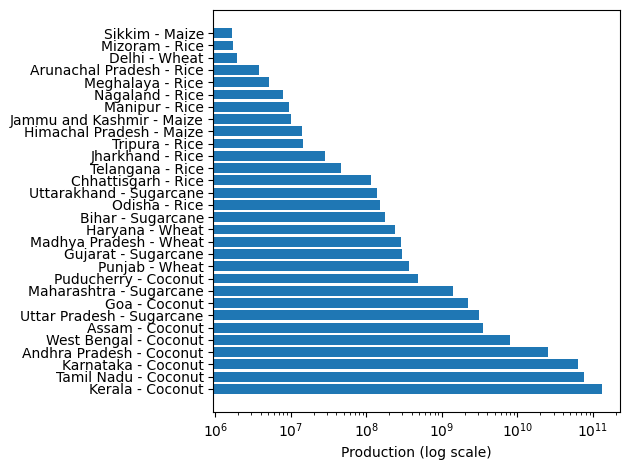

In [ ]:
grouped = df.groupby(['State','Crop'])['Production'].sum().reset_index()
top_crop = grouped.loc[grouped.groupby('State')['Production'].idxmax()]
top_crop = top_crop.sort_values('Production',ascending = False)

plt.barh(top_crop['State']+' - '+ top_crop['Crop'],top_crop['Production'])
plt.xscale('log')
plt.xlabel('Production (log scale)')
plt.tight_layout()

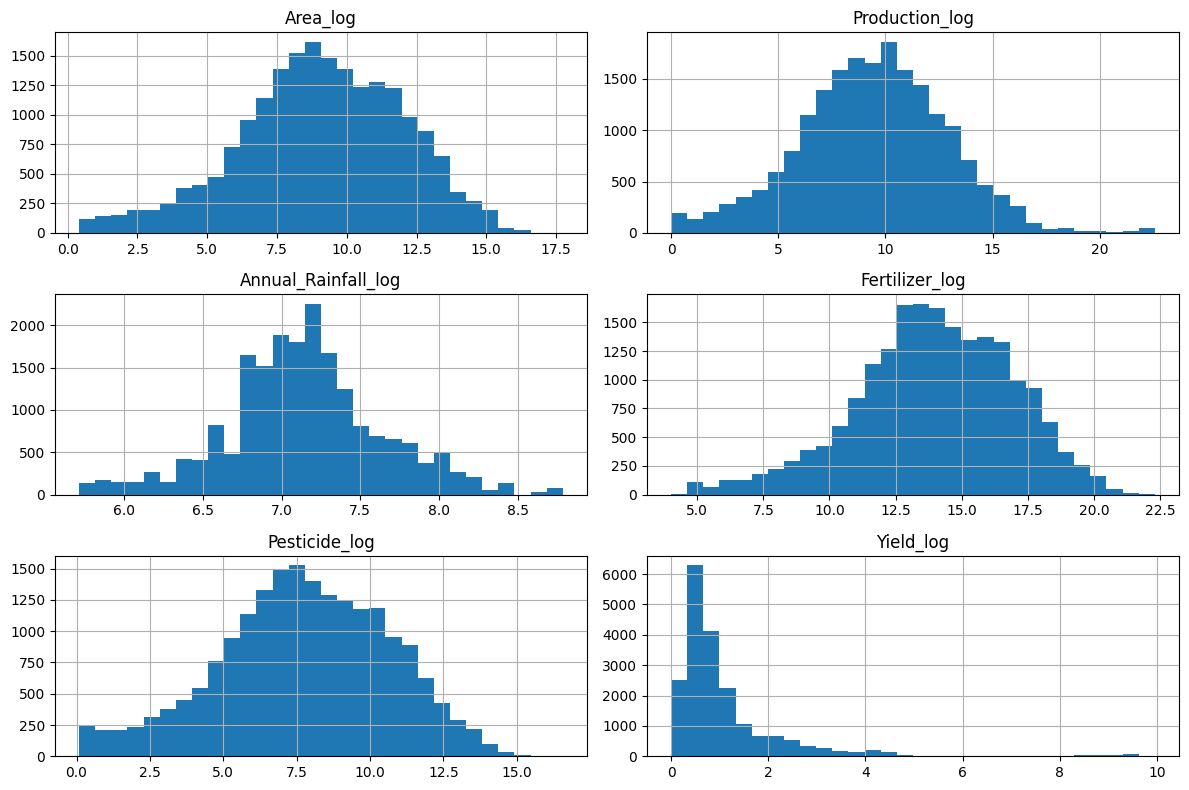

In [ ]:
import numpy as np

skewed_cols = ['Area', 'Production','Annual_Rainfall', 'Fertilizer', 'Pesticide','Yield']
for col in skewed_cols:
    df[col + '_log'] = np.log1p(df[col])

df[[c+'_log' for c in skewed_cols]].hist(figsize=(12,8), bins=30)
plt.tight_layout()
plt.show()

In [ ]:
df[[c+'_log' for c in skewed_cols]].skew().sort_values(ascending=False)

,0
Yield_log,3.635185
Annual_Rainfall_log,0.077222
Production_log,0.005470
Pesticide_log,-0.256003
Area_log,-0.339826
Fertilizer_log,-0.382240


In [ ]:
df_coconut = df[df['Crop'] == 'Coconut'].copy()
df = df[df['Crop'] != 'Coconut']

In [ ]:
df_coconut.shape

(172, 16)

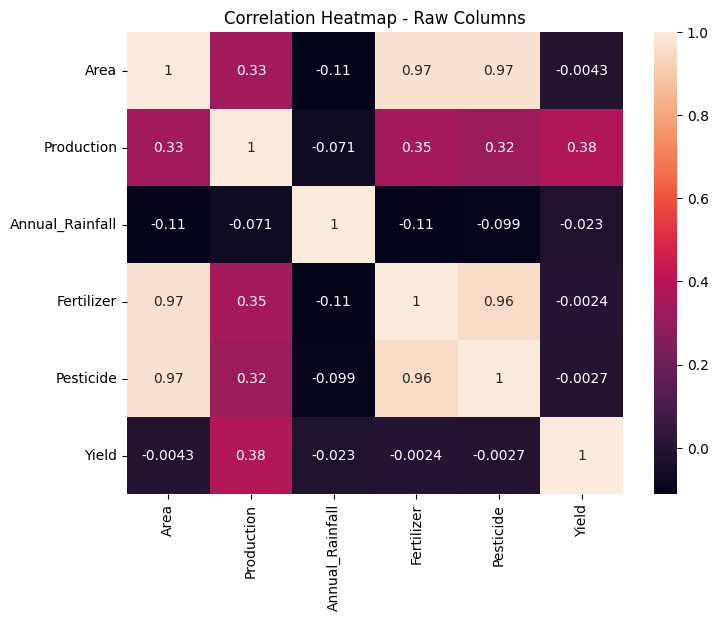

In [ ]:
num_cols = ['Area', 'Production', 'Annual_Rainfall', 'Fertilizer', 'Pesticide', 'Yield']

plt.figure(figsize=(8,6))
sns.heatmap(df[num_cols].corr(), annot=True)
plt.title('Correlation Heatmap - Raw Columns')
plt.show()

In [ ]:
df['Fertilizer_per_ha'] = df['Fertilizer'] / df['Area']
df['Pesticide_per_ha'] = df['Pesticide'] / df['Area']

In [ ]:
df.head()

,Crop,Crop_Year,Season,State,Production,Area,Annual_Rainfall,Fertilizer,Pesticide,Yield,Area_log,Production_log,Annual_Rainfall_log,Fertilizer_log,Pesticide_log,Yield_log,Fertilizer_per_ha,Pesticide_per_ha
0,Arecanut,1997,Whole Year,Assam,56708,73814.0,2051.4,7024878.38,22882.34,0.768255,11.209317,10.945688,7.626765,15.764969,10.038164,0.569993,95.17,0.31
1,Arecanut,1997,Whole Year,Karnataka,133342,93100.0,1266.7,8860327.00,28861.00,1.432245,11.441440,11.800680,7.144960,15.997094,10.270281,0.888815,95.17,0.31
2,Arecanut,1997,Whole Year,Kerala,93995,76145.0,3252.4,7246719.65,23604.95,1.234421,11.240408,11.451008,8.087456,15.796060,10.069254,0.803982,95.17,0.31
3,Arecanut,1997,Whole Year,Meghalaya,12116,9569.0,3818.2,910681.73,2966.39,1.266172,9.166388,9.402365,8.247796,13.721950,7.995438,0.818092,95.17,0.31
4,Arecanut,1997,Whole Year,West Bengal,12423,8058.0,1852.9,766879.86,2497.98,1.541698,8.994545,9.427385,7.525047,13.550087,7.823638,0.932832,95.17,0.31


In [ ]:
final_cols = [
    'Crop', 'Crop_Year', 'Season', 'State',
    'Area_log',
    'Annual_Rainfall',
    'Fertilizer_per_ha', 'Pesticide_per_ha',
    'Yield'
]
df = df[final_cols]
df.head()

,Crop,Crop_Year,Season,State,Area_log,Annual_Rainfall,Fertilizer_per_ha,Pesticide_per_ha,Yield
0,Arecanut,1997,Whole Year,Assam,11.209317,2051.4,95.17,0.31,0.768255
1,Arecanut,1997,Whole Year,Karnataka,11.441440,1266.7,95.17,0.31,1.432245
2,Arecanut,1997,Whole Year,Kerala,11.240408,3252.4,95.17,0.31,1.234421
3,Arecanut,1997,Whole Year,Meghalaya,9.166388,3818.2,95.17,0.31,1.266172
4,Arecanut,1997,Whole Year,West Bengal,8.994545,1852.9,95.17,0.31,1.541698


In [ ]:
from sklearn.preprocessing import RobustScaler

feature_cols = ['Area_log', 'Annual_Rainfall', 'Fertilizer_per_ha', 'Pesticide_per_ha']
scaler = RobustScaler()
X_scaled = scaler.fit_transform(df[feature_cols])

In [ ]:
X_scaled = pd.DataFrame(X_scaled, columns = feature_cols, index=df.index)

In [ ]:
X_scaled

,Area_log,Annual_Rainfall,Fertilizer_per_ha,Pesticide_per_ha
0,0.523391,1.150656,-0.994957,0.363636
1,0.581421,0.029295,-0.994957,0.363636
2,0.531164,2.866922,-0.994957,0.363636
3,0.012672,3.675467,-0.994957,0.363636
4,-0.030288,0.866993,-0.994957,0.363636
...,...,...,...,...
19625,-1.876518,0.189632,0.550131,0.909091
19626,-0.490845,0.442428,0.550131,0.909091
19627,-0.646554,4.634775,0.550131,0.909091
19628,-1.619120,0.096814,0.990922,0.909091


In [ ]:
df.columns

Index(['Crop', 'Crop_Year', 'Season', 'State', 'Area_log', 'Annual_Rainfall',
       'Fertilizer_per_ha', 'Pesticide_per_ha', 'Yield'],
      dtype='object')

In [ ]:
def farm_size_category(Area_log):

  area = np.expm1(Area_log)
  if area < 1000:
    return 'Small'

  elif area < 10000:
    return 'Medium'

  else:
    return 'Large'

df['Farm_Size_Category'] = df['Area_log'].apply(farm_size_category)

In [ ]:
df['Farm_Size_Category'].value_counts()

,count
Farm_Size_Category,
Large,9481
Medium,5701
Small,4276


In [ ]:
from sklearn.decomposition import PCA

pca = PCA()

pca.fit(X_scaled)

PCA()

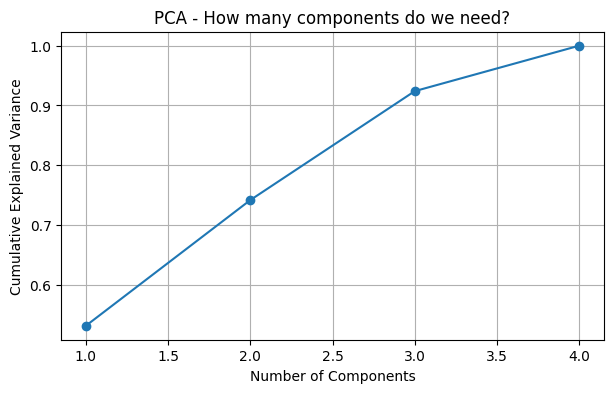

In [ ]:
plt.figure(figsize=(7,4))
plt.plot(range(1, len(feature_cols)+1), np.cumsum(pca.explained_variance_ratio_), marker='o')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('PCA - How many components do we need?')
plt.grid(True)
plt.show()

In [ ]:
train_df = df[df['Crop_Year'] <= 2015].copy()
val_df = df[df['Crop_Year'] > 2015].copy()

print("Train rows:", len(train_df))
print("Validation rows:", len(val_df))
print("Train years:", train_df['Crop_Year'].min(), "-", train_df['Crop_Year'].max())
print("Val years:", val_df['Crop_Year'].min(), "-", val_df['Crop_Year'].max())

Train rows: 15223
Validation rows: 4235
Train years: 1997 - 2015
Val years: 2016 - 2020


In [ ]:
interia = []
k_range = range(1,11)

In [ ]:
from sklearn.cluster import KMeans

kmeans = KMeans()

k=1, Inertia = 51092.4225
k=2, Inertia = 34107.1179
k=3, Inertia = 26824.9049
k=4, Inertia = 22689.1258
k=5, Inertia = 19560.3745
k=6, Inertia = 17319.4719
k=7, Inertia = 15636.1570
k=8, Inertia = 14509.9237
k=9, Inertia = 13461.9645
k=10, Inertia = 12570.8583


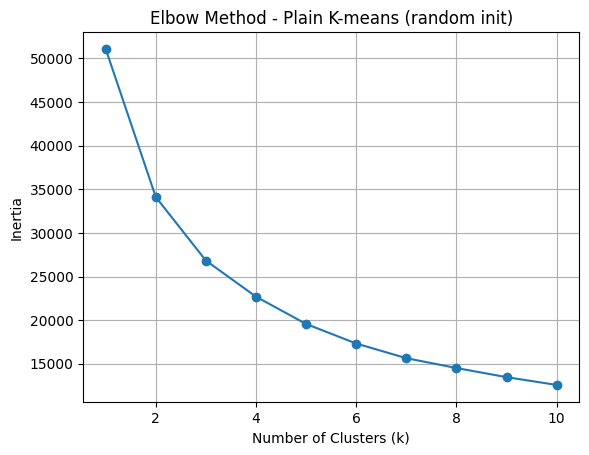

In [ ]:
interia_baseline = []
k_range = range(1,11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, init='random', random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    interia_baseline.append(kmeans.inertia_)
    print(f"k={k}, Inertia = {kmeans.inertia_:.4f}")

plt.plot(k_range, interia_baseline, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method - Plain K-means (random init)')
plt.grid(True)
plt.show()

k=2, Silhouette Score = 0.4068
k=3, Silhouette Score = 0.2783
k=4, Silhouette Score = 0.2631
k=5, Silhouette Score = 0.2735
k=6, Silhouette Score = 0.2560
k=7, Silhouette Score = 0.2690
k=8, Silhouette Score = 0.2561
k=9, Silhouette Score = 0.2618
k=10, Silhouette Score = 0.2614


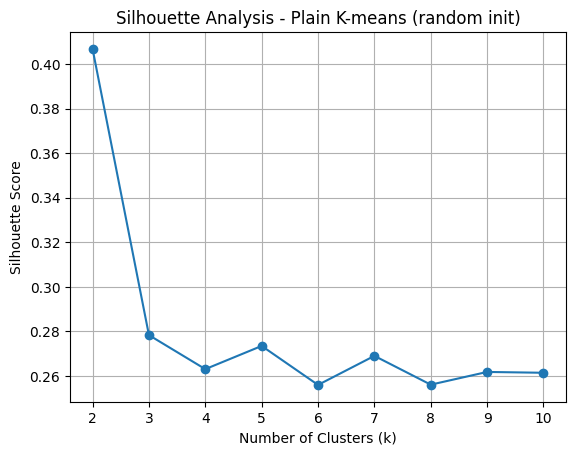

In [ ]:
from sklearn.metrics import silhouette_score
sil_scores_baseline = []
for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, init='random', random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    sil_scores_baseline.append(score)
    print(f"k={k}, Silhouette Score = {score:.4f}")

plt.plot(range(2,11), sil_scores_baseline, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Analysis - Plain K-means (random init)')
plt.grid(True)
plt.show()

k=2, Davies-Bouldin Score = 1.0553
k=3, Davies-Bouldin Score = 1.2933
k=4, Davies-Bouldin Score = 1.2305
k=5, Davies-Bouldin Score = 1.1480
k=6, Davies-Bouldin Score = 1.2048
k=7, Davies-Bouldin Score = 1.1320
k=8, Davies-Bouldin Score = 1.1697
k=9, Davies-Bouldin Score = 1.2041
k=10, Davies-Bouldin Score = 1.2003


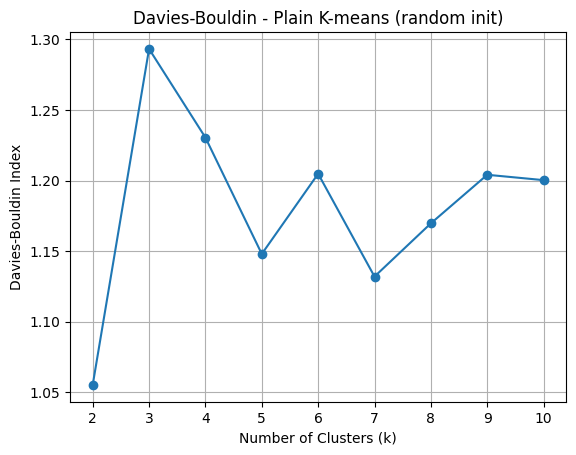

In [ ]:
from sklearn.metrics import davies_bouldin_score
db_scores_baseline = []
for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, init='random', random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    score = davies_bouldin_score(X_scaled, labels)
    db_scores_baseline.append(score)
    print(f"k={k}, Davies-Bouldin Score = {score:.4f}")

plt.plot(range(2,11), db_scores_baseline, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Davies-Bouldin Index')
plt.title('Davies-Bouldin - Plain K-means (random init)')
plt.grid(True)
plt.show()

In [ ]:
for k in k_range:
  kmeans = KMeans(n_clusters=k,random_state=42)
  kmeans.fit(X_scaled)
  interia.append(kmeans.inertia_)

In [ ]:
interia

[51092.42253907647,
 34107.117902419894,
 26825.122097007094,
 22689.996105645092,
 20098.72751639633,
 17320.716059015234,
 15636.278379129388,
 14754.500267801655,
 13541.273180878574,
 12545.986582794792]

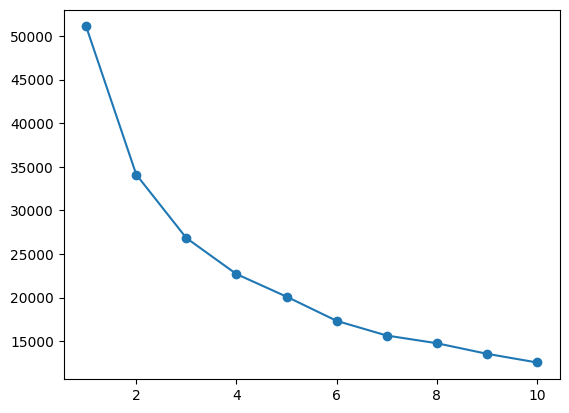

In [ ]:
plt.plot(k_range,interia, marker = 'o')

k=2, Silhouette Score = 0.4068
k=3, Silhouette Score = 0.2783
k=4, Silhouette Score = 0.2635
k=5, Silhouette Score = 0.2531
k=6, Silhouette Score = 0.2563
k=7, Silhouette Score = 0.2691
k=8, Silhouette Score = 0.2746
k=9, Silhouette Score = 0.2696
k=10, Silhouette Score = 0.2546


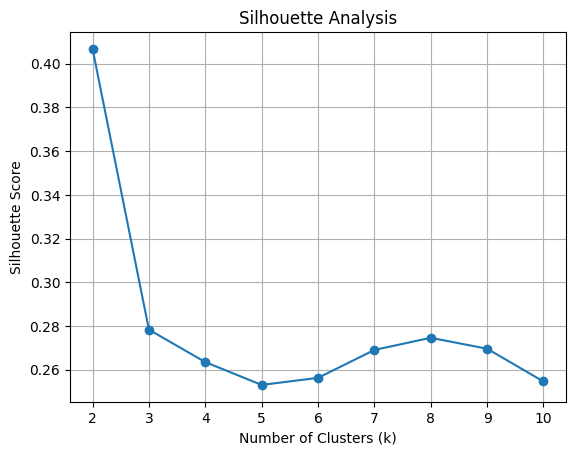

In [ ]:
sil_scores = []
for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    sil_scores.append(score)
    print(f"k={k}, Silhouette Score = {score:.4f}")

plt.plot(range(2,11), sil_scores, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Analysis')
plt.grid(True)
plt.show()

k = 2, db_score =  1.0553
k = 3, db_score =  1.2932
k = 4, db_score =  1.2318
k = 5, db_score =  1.2513
k = 6, db_score =  1.2064
k = 7, db_score =  1.1317
k = 8, db_score =  1.0940
k = 9, db_score =  1.0962
k = 10, db_score =  1.1324


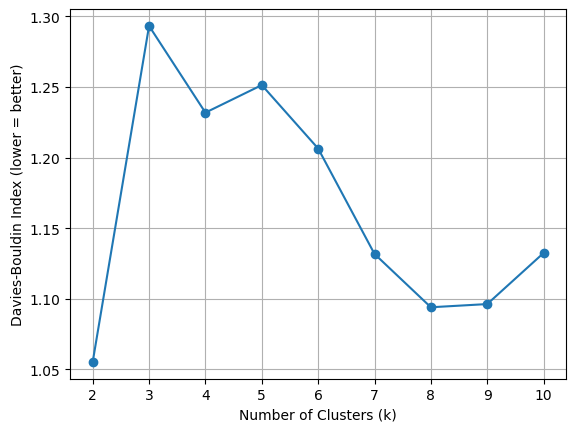

In [ ]:
db_scores = []
for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(X_scaled)
    score = davies_bouldin_score(X_scaled, labels)
    db_scores.append(score)
    print(f"k = {k}, db_score = {score : .4f}")

plt.plot(range(2,11), db_scores, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Davies-Bouldin Index (lower = better)')
plt.grid(True)
plt.show()

In [ ]:
k_final = 8
kmeans_final = KMeans(n_clusters=k_final, random_state=42)
df['Cluster'] = kmeans_final.fit_predict(X_scaled)

df['Cluster'].value_counts()

,count
Cluster,
2,5107
5,3803
6,2591
3,2367
0,2342
1,1829
7,1264
4,155


In [ ]:
df['Cluster'].value_counts(normalize=True) * 100

,proportion
Cluster,
2,26.246274
5,19.544660
6,13.315860
3,12.164662
0,12.036180
1,9.399733
7,6.496043
4,0.796588


In [ ]:
cluster_profile = df.groupby('Cluster')[['Area_log','Annual_Rainfall','Fertilizer_per_ha','Pesticide_per_ha','Yield']].mean()
cluster_profile

,Area_log,Annual_Rainfall,Fertilizer_per_ha,Pesticide_per_ha,Yield
Cluster,,,,,
0,9.369742,1122.257168,143.520679,0.151102,4.292130
1,8.148879,2012.252414,158.973040,0.332493,4.441213
2,10.671761,1033.040174,158.299700,0.330544,5.101130
3,8.152794,1911.025360,109.241221,0.236988,4.081442
4,7.780987,5689.123226,119.158839,0.263806,2.860345
5,11.111725,953.849826,104.844052,0.248738,4.313397
6,4.675582,1172.134732,147.614666,0.302258,3.822156
7,7.854540,3341.880696,138.786361,0.282389,4.901665


In [ ]:
cluster_names = {
    0: 'Mid-Large Balanced',
    1: 'High-Rainfall Intensive',
    2: 'Large-Scale High-Yield',
    3: 'Medium Low-Input Wet',
    4: 'Extreme-Rainfall Risk Zone',
    5: 'Mega-Farm Low-Input Dry',
    6: 'Small/Marginal Farms',
    7: 'Wet-Climate Good-Yield'
}

df['Cluster_Name'] = df['Cluster'].map(cluster_names)
df[['Cluster','Cluster_Name']].drop_duplicates()

,Cluster,Cluster_Name
0,3,Medium Low-Input Wet
1,5,Mega-Farm Low-Input Dry
2,7,Wet-Climate Good-Yield
5,6,Small/Marginal Farms
10,4,Extreme-Rainfall Risk Zone
58,0,Mid-Large Balanced
91,1,High-Rainfall Intensive
93,2,Large-Scale High-Yield


In [ ]:
df.shape

(19458, 12)

In [ ]:
kmeans_random = KMeans(n_clusters=8, init='random', random_state=42, n_init=10)
labels_random = kmeans_random.fit_predict(X_scaled)

print("Plain K-means (random init) Silhouette:", silhouette_score(X_scaled, labels_random))
print("K-means++ Silhouette:", sil_scores[6])  # k=8 ka index (list mein 2 se start hua tha)

Plain K-means (random init) Silhouette: 0.2560976810990836
K-means++ Silhouette: 0.27462417953861484


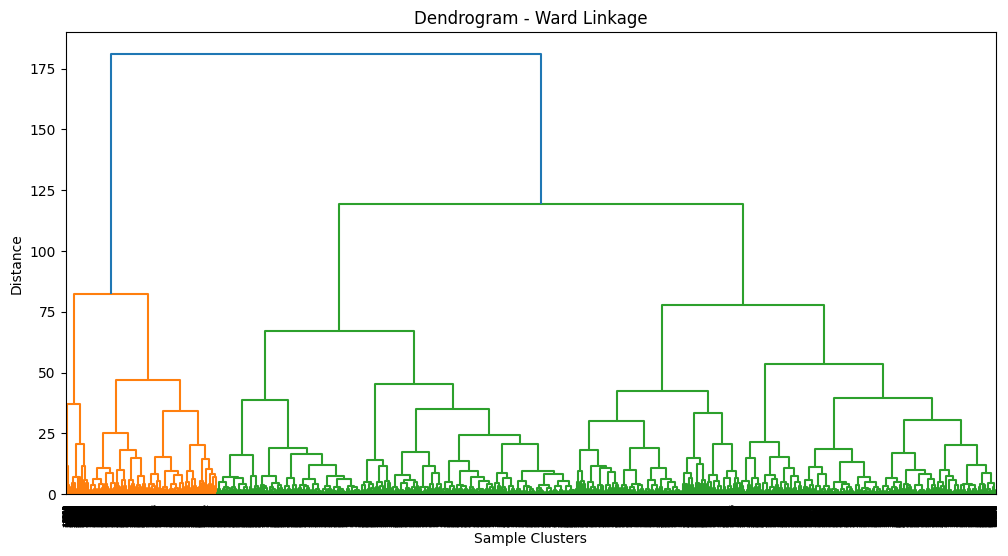

In [ ]:
from scipy.cluster.hierarchy import dendrogram, linkage

linked = linkage(X_scaled, method='ward')

plt.figure(figsize=(12,6))
dendrogram(linked, p=30, leaf_rotation=90)
plt.title('Dendrogram - Ward Linkage')
plt.xlabel('Sample Clusters')
plt.ylabel('Distance')
plt.show()

In [ ]:
from sklearn.cluster import AgglomerativeClustering

sil_scores_hier = []
db_scores_hier = []

for k in range(2, 11):
    hier_model = AgglomerativeClustering(n_clusters=k, linkage='ward')
    labels = hier_model.fit_predict(X_scaled)

    sil = silhouette_score(X_scaled, labels)
    db = davies_bouldin_score(X_scaled, labels)

    sil_scores_hier.append(sil)
    db_scores_hier.append(db)

    print(f"k={k}, Silhouette = {sil:.4f}, Davies-Bouldin = {db:.4f}")

k=2, Silhouette = 0.3973, Davies-Bouldin = 1.0641
k=3, Silhouette = 0.2672, Davies-Bouldin = 1.3220
k=4, Silhouette = 0.2680, Davies-Bouldin = 1.2326
k=5, Silhouette = 0.2405, Davies-Bouldin = 1.2988
k=6, Silhouette = 0.2084, Davies-Bouldin = 1.3202
k=7, Silhouette = 0.2112, Davies-Bouldin = 1.2516
k=8, Silhouette = 0.2130, Davies-Bouldin = 1.2874
k=9, Silhouette = 0.2053, Davies-Bouldin = 1.2833
k=10, Silhouette = 0.2036, Davies-Bouldin = 1.3648


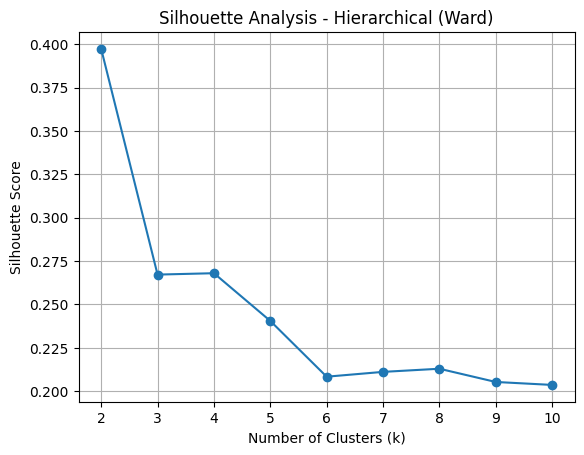

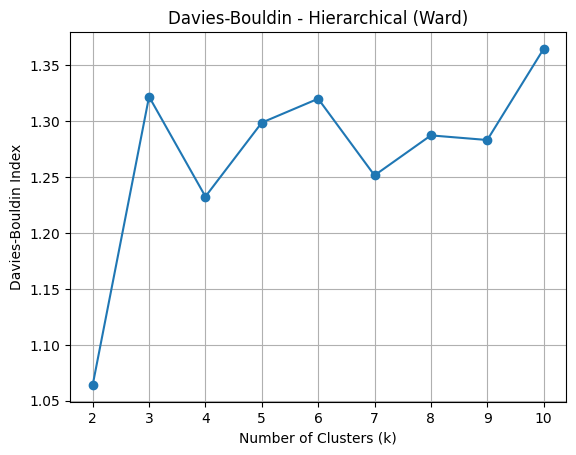

In [ ]:
plt.plot(range(2,11), sil_scores_hier, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Analysis - Hierarchical (Ward)')
plt.grid(True)
plt.show()

plt.plot(range(2,11), db_scores_hier, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Davies-Bouldin Index')
plt.title('Davies-Bouldin - Hierarchical (Ward)')
plt.grid(True)
plt.show()

In [ ]:
hier_k4 = AgglomerativeClustering(n_clusters=4, linkage='ward')
labels_k4 = hier_k4.fit_predict(X_scaled)
df[['Area_log','Annual_Rainfall','Fertilizer_per_ha','Pesticide_per_ha']].groupby(labels_k4).mean()

,Area_log,Annual_Rainfall,Fertilizer_per_ha,Pesticide_per_ha
0,9.615501,1162.318248,120.400061,0.218103
1,7.919874,2561.651511,132.267779,0.282784
2,8.886984,1142.146856,158.815417,0.335081
3,7.711474,4561.660320,132.962480,0.305779


In [ ]:
from sklearn.metrics import adjusted_rand_score

hier_final = AgglomerativeClustering(n_clusters=8, linkage='ward')
df['Cluster_Hierarchical'] = hier_final.fit_predict(X_scaled)

ari = adjusted_rand_score(df['Cluster'], df['Cluster_Hierarchical'])
print(f"Agreement between K-means and Hierarchical (ARI): {ari:.4f}")

Agreement between K-means and Hierarchical (ARI): 0.4230


k=2, FPC = 0.6177
k=3, FPC = 0.5183
k=4, FPC = 0.4289
k=5, FPC = 0.3767
k=6, FPC = 0.3372
k=7, FPC = 0.3091
k=8, FPC = 0.2798
k=9, FPC = 0.2648
k=10, FPC = 0.2596


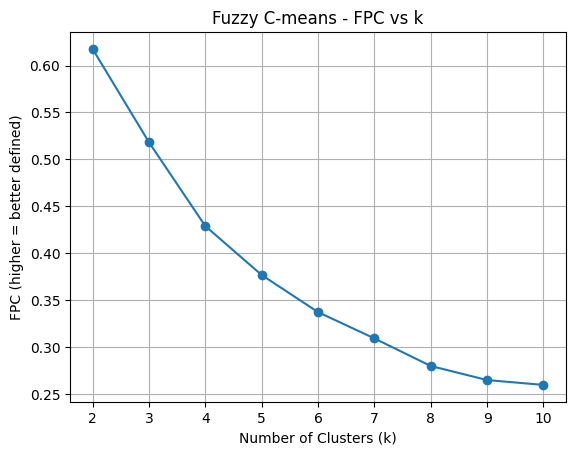

In [ ]:
!pip install -q scikit-fuzzy
import skfuzzy as fuzz

fpc_scores = []
for k in range(2, 11):
    cntr, u, u0, d, jm, p, fpc = fuzz.cluster.cmeans(
        X_scaled.T, c=k, m=2, error=0.005, maxiter=1000, seed=42
    )
    fpc_scores.append(fpc)
    print(f"k={k}, FPC = {fpc:.4f}")

plt.plot(range(2,11), fpc_scores, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('FPC (higher = better defined)')
plt.title('Fuzzy C-means - FPC vs k')
plt.grid(True)
plt.show()

k-distance percentiles:
  50th percentile = 0.1244
  75th percentile = 0.1848
  90th percentile = 0.2501
  95th percentile = 0.3127
  99th percentile = 0.4947
  max = 1.1278

Suggested eps (knee point) = 0.2746


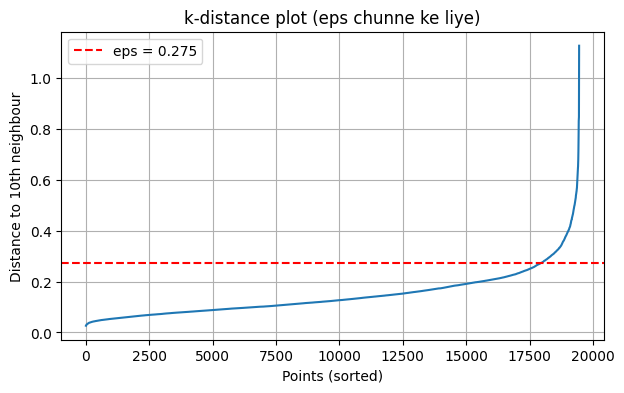

In [ ]:
from sklearn.neighbors import NearestNeighbors
import numpy as np

min_samples = 10
nn = NearestNeighbors(n_neighbors=min_samples).fit(X_scaled)
distances, _ = nn.kneighbors(X_scaled)
k_dist = np.sort(distances[:, -1])

x = np.arange(len(k_dist))
p1 = np.array([0, k_dist[0]])
p2 = np.array([len(k_dist)-1, k_dist[-1]])
line = (p2 - p1) / np.linalg.norm(p2 - p1)
vecs = np.c_[x, k_dist] - p1
dist_to_line = np.abs(vecs[:, 0]*line[1] - vecs[:, 1]*line[0])
knee_idx = dist_to_line.argmax()
suggested_eps = k_dist[knee_idx]

print("k-distance percentiles:")
for p in [50, 75, 90, 95, 99]:
    print(f"  {p}th percentile = {np.percentile(k_dist, p):.4f}")
print(f"  max = {k_dist.max():.4f}")
print(f"\nSuggested eps (knee point) = {suggested_eps:.4f}")


plt.figure(figsize=(7,4))
plt.plot(k_dist)
plt.axhline(suggested_eps, color='red', linestyle='--', label=f'eps = {suggested_eps:.3f}')
plt.xlabel('Points (sorted)')
plt.ylabel(f'Distance to {min_samples}th neighbour')
plt.title('k-distance plot (eps chunne ke liye)')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score

for eps in [0.2, 0.3, 0.4, 0.5, 0.7, 1.0]:
    labels = DBSCAN(eps=eps, min_samples=10).fit_predict(X_scaled)
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = (labels == -1).sum()
    mask = labels != -1

    if n_clusters >= 2:
        sil = silhouette_score(X_scaled[mask], labels[mask])
        db = davies_bouldin_score(X_scaled[mask], labels[mask])
        print(f"eps={eps}: clusters={n_clusters}, noise={n_noise} ({n_noise/len(labels)*100:.1f}%), Sil={sil:.4f}, DB={db:.4f}")
    else:
        print(f"eps={eps}: clusters={n_clusters}, noise={n_noise} ({n_noise/len(labels)*100:.1f}%), score nahi nikal sakte")

eps=0.2: clusters=128, noise=2189 (11.2%), Sil=-0.2136, DB=1.2495
eps=0.3: clusters=44, noise=528 (2.7%), Sil=-0.1079, DB=1.3916
eps=0.4: clusters=29, noise=140 (0.7%), Sil=-0.0659, DB=1.3531
eps=0.5: clusters=18, noise=51 (0.3%), Sil=0.0674, DB=1.3879
eps=0.7: clusters=4, noise=10 (0.1%), Sil=0.5785, DB=0.4168
eps=1.0: clusters=3, noise=0 (0.0%), Sil=0.6580, DB=0.3838


In [ ]:
db = DBSCAN(eps=0.4, min_samples=10)
df['Cluster_DBSCAN'] = db.fit_predict(X_scaled)
df['Is_Outlier'] = (df['Cluster_DBSCAN'] == -1)

print(pd.crosstab(df['Cluster'], df['Is_Outlier']))

print(df[df['Is_Outlier']][['Area_log','Annual_Rainfall','Fertilizer_per_ha','Pesticide_per_ha','Yield']].describe())
print(df[df['Is_Outlier']]['State'].value_counts().head())

Is_Outlier  False  True 
Cluster                 
0            2337      5
1            1820      9
2            5104      3
3            2362      5
4             138     17
5            3801      2
6            2580     11
7            1176     88
         Area_log  Annual_Rainfall  Fertilizer_per_ha  Pesticide_per_ha  \
count  140.000000       140.000000         140.000000        140.000000   
mean     6.542175      3324.569921         135.944357          0.250929   
std      4.427532      1346.705054          26.731366          0.062397   
min      0.405465       451.900000          94.670000          0.090000   
25%      3.238086      2659.650000         106.130000          0.210000   
50%      5.030352      3328.100000         144.490000          0.260000   
75%     10.815682      3886.900000         155.820000          0.270000   
max     17.743566      6552.700000         193.610000          0.380000   

            Yield  
count  140.000000  
mean     7.499815  
std     18.850

In [ ]:
from sklearn.cluster import HDBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score

for mcs in [30, 50, 100, 200]:
    labels_h = HDBSCAN(min_cluster_size=mcs, min_samples=10).fit_predict(X_scaled)
    n_clusters = len(set(labels_h)) - (1 if -1 in labels_h else 0)
    n_noise = (labels_h == -1).sum()
    line = f"min_cluster_size={mcs}: clusters={n_clusters}, noise={n_noise} ({n_noise/len(labels_h)*100:.1f}%)"
    mask = labels_h != -1
    if n_clusters >= 2:
        line += f", Sil={silhouette_score(X_scaled[mask], labels_h[mask]):.4f}, DB={davies_bouldin_score(X_scaled[mask], labels_h[mask]):.4f}"
    print(line)

min_cluster_size=30: clusters=113, noise=5436 (27.9%), Sil=0.0381, DB=2.2288
min_cluster_size=50: clusters=88, noise=5653 (29.1%), Sil=0.0583, DB=2.4519
min_cluster_size=100: clusters=43, noise=3888 (20.0%), Sil=-0.0538, DB=2.7436
min_cluster_size=200: clusters=25, noise=3981 (20.5%), Sil=-0.0281, DB=3.2622


In [ ]:
for ms in [5, 10, 20]:
    labels = DBSCAN(eps=0.4, min_samples=ms).fit_predict(X_scaled)
    print(f"min_samples={ms}: clusters={len(set(labels))-(1 if -1 in labels else 0)}, noise={(labels==-1).sum()}")

min_samples=5: clusters=31, noise=57
min_samples=10: clusters=29, noise=140
min_samples=20: clusters=23, noise=446


In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

mask = ~df['Is_Outlier'].values
km_clean = KMeans(n_clusters=8, random_state=42, n_init=10).fit(X_scaled[mask])

print("Silhouette (outliers ke bina):", silhouette_score(X_scaled[mask], km_clean.labels_))
print("ARI vs original K-means:", adjusted_rand_score(df['Cluster'].values[mask], km_clean.labels_))

Silhouette (outliers ke bina): 0.2737316627435866
ARI vs original K-means: 0.652226087974363


In [ ]:
import skfuzzy as fuzz
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score

# Part A: har k ke liye hard-label scores
for k in range(2, 11):
    cntr, u, u0, d, jm, p, fpc = fuzz.cluster.cmeans(
        X_scaled.T, c=k, m=2, error=0.005, maxiter=1000, seed=42
    )
    hl = u.argmax(axis=0)
    print(f"k={k}, FPC={fpc:.4f}, Silhouette={silhouette_score(X_scaled, hl):.4f}, DB={davies_bouldin_score(X_scaled, hl):.4f}")

# Part B: k=8 pe soft membership
cntr, u, u0, d, jm, p, fpc = fuzz.cluster.cmeans(
    X_scaled.T, c=8, m=2, error=0.005, maxiter=1000, seed=42
)
df['Fuzzy_Cluster'] = u.argmax(axis=0)
df['Max_Membership'] = u.max(axis=0)

print(df['Max_Membership'].describe())
print("Boundary rows (max membership < 0.5):", (df['Max_Membership'] < 0.5).sum())
print("K-means se agreement (ARI):", adjusted_rand_score(df['Cluster'], df['Fuzzy_Cluster']))

k=2, FPC=0.6177, Silhouette=0.3059, DB=1.3752
k=3, FPC=0.5183, Silhouette=0.2758, DB=1.2928
k=4, FPC=0.4289, Silhouette=0.2623, DB=1.2806
k=5, FPC=0.3767, Silhouette=0.2472, DB=1.2759
k=6, FPC=0.3372, Silhouette=0.2420, DB=1.2660
k=7, FPC=0.3091, Silhouette=0.2430, DB=1.2809
k=8, FPC=0.2798, Silhouette=0.2353, DB=1.3087
k=9, FPC=0.2648, Silhouette=0.2057, DB=1.3739
k=10, FPC=0.2596, Silhouette=0.2203, DB=1.2921
count    19458.000000
mean         0.425581
std          0.166084
min          0.157669
25%          0.294841
50%          0.384106
75%          0.521508
max          0.989726
Name: Max_Membership, dtype: float64
Boundary rows (max membership < 0.5): 13960
K-means se agreement (ARI): 0.5075619912789178


In [ ]:
rows = []
for k in range(4, 9):
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X_scaled)
    hc = AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(X_scaled)
    _, u, *_ = fuzz.cluster.cmeans(X_scaled.T, c=k, m=2, error=0.005, maxiter=1000, seed=42)
    fz = u.argmax(axis=0)
    for name, lab in [('K-means++', km), ('Hierarchical', hc), ('Fuzzy C-means', fz)]:
        rows.append({'k': k, 'Method': name,
                     'Silhouette': silhouette_score(X_scaled, lab),
                     'Davies-Bouldin': davies_bouldin_score(X_scaled, lab)})

comp = pd.DataFrame(rows)
print("Silhouette (higher better)")
print(comp.pivot(index='k', columns='Method', values='Silhouette').round(4))
print("\nDavies-Bouldin (lower better)")
print(comp.pivot(index='k', columns='Method', values='Davies-Bouldin').round(4))

Silhouette (higher better)
Method  Fuzzy C-means  Hierarchical  K-means++
k                                             
4              0.2623        0.2680     0.2630
5              0.2472        0.2405     0.2739
6              0.2420        0.2084     0.2561
7              0.2430        0.2112     0.2691
8              0.2353        0.2130     0.2561

Davies-Bouldin (lower better)
Method  Fuzzy C-means  Hierarchical  K-means++
k                                             
4              1.2806        1.2326     1.2315
5              1.2759        1.2988     1.1521
6              1.2660        1.3202     1.2049
7              1.2809        1.2516     1.1319
8              1.3087        1.2874     1.1698


k=1, Gap = 1.4253, s_k = 0.0034
k=2, Gap = 1.1421, s_k = 0.0040
k=3, Gap = 1.1797, s_k = 0.0037
k=4, Gap = 1.2302, s_k = 0.0041
k=5, Gap = 1.2598, s_k = 0.0071
k=6, Gap = 1.2661, s_k = 0.0046
k=7, Gap = 1.2840, s_k = 0.0045
k=8, Gap = 1.2714, s_k = 0.0046
k=9, Gap = 1.2532, s_k = 0.0032
k=10, Gap = 1.2590, s_k = 0.0027


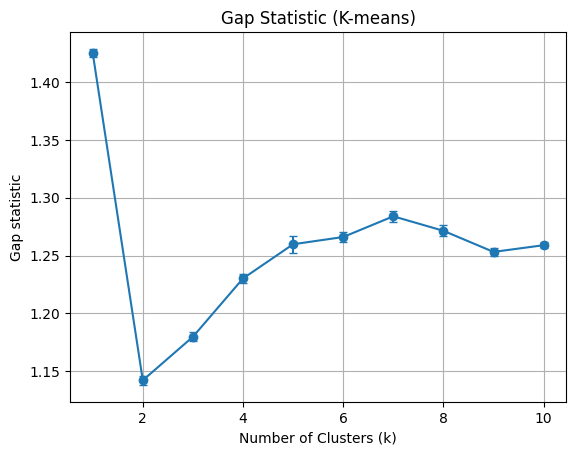

In [ ]:
def gap_statistic(X, k_max=10, B=10, seed=42):
    rng = np.random.default_rng(seed)
    pca = PCA().fit(X)
    Z = pca.transform(X)
    mins, maxs = Z.min(axis=0), Z.max(axis=0)
    gaps, sks = [], []
    for k in range(1, k_max + 1):
        logW = np.log(KMeans(n_clusters=k, random_state=42, n_init=3).fit(X).inertia_)
        ref = []
        for b in range(B):
            Xb = pca.inverse_transform(rng.uniform(mins, maxs, size=Z.shape))
            ref.append(np.log(KMeans(n_clusters=k, random_state=b, n_init=3).fit(Xb).inertia_))
        ref = np.array(ref)
        gaps.append(ref.mean() - logW)
        sks.append(ref.std() * np.sqrt(1 + 1 / B))
    return np.array(gaps), np.array(sks)

gaps, sks = gap_statistic(X_scaled)
for k in range(1, 11):
    print(f"k={k}, Gap = {gaps[k-1]:.4f}, s_k = {sks[k-1]:.4f}")

plt.errorbar(range(1, 11), gaps, yerr=sks, marker='o', capsize=3)
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Gap statistic')
plt.title('Gap Statistic (K-means)')
plt.grid(True)
plt.show()

In [ ]:
km7 = KMeans(n_clusters=7, random_state=42, n_init=10)
df['Cluster_k7'] = km7.fit_predict(X_scaled)

print(df['Cluster_k7'].value_counts())
print(df.groupby('Cluster_k7')[['Area_log','Annual_Rainfall','Fertilizer_per_ha','Pesticide_per_ha','Yield']].mean())

Cluster_k7
1    4836
0    3658
3    3121
6    2832
4    2559
5    1946
2     506
Name: count, dtype: int64
             Area_log  Annual_Rainfall  Fertilizer_per_ha  Pesticide_per_ha  \
Cluster_k7                                                                    
0           11.379580       976.236683         105.254612          0.248543   
1           10.992471      1071.999427         158.428519          0.327876   
2            7.711172      4529.347107         133.241047          0.303202   
3            5.842187      1251.119158         159.159984          0.333098   
4            8.149093      2605.876083         136.236995          0.282013   
5            9.837500      1135.397610         145.008746          0.136886   
6            6.791801      1429.567881         113.992694          0.233803   

               Yield  
Cluster_k7            
0           4.404438  
1           5.219246  
2           3.623414  
3           3.914897  
4           4.654960  
5           4.577353

In [ ]:
from sklearn.metrics import adjusted_rand_score

mask_tr = (df['Crop_Year'] <= 2015).values
X_tr, X_va = X_scaled[mask_tr], X_scaled[~mask_tr]

for k in [5, 6, 7, 8]:
    km_tr = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_tr)
    km_va = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_va)
    ari = adjusted_rand_score(km_tr.predict(X_va), km_va.labels_)
    print(f"k={k}: stability ARI = {ari:.4f}")

k=5: stability ARI = 0.4536
k=6: stability ARI = 0.3286
k=7: stability ARI = 0.3084
k=8: stability ARI = 0.3596


In [ ]:
km5 = KMeans(n_clusters=5, random_state=42, n_init=10)
df['Cluster_k5'] = km5.fit_predict(X_scaled)

print(df['Cluster_k5'].value_counts())
print(df.groupby('Cluster_k5')[['Area_log','Annual_Rainfall','Fertilizer_per_ha','Pesticide_per_ha','Yield']].mean())

Cluster_k5
2    6361
0    5887
1    3643
4    3017
3     550
Name: count, dtype: int64
             Area_log  Annual_Rainfall  Fertilizer_per_ha  Pesticide_per_ha  \
Cluster_k5                                                                    
0           10.015082      1093.159977         159.354046          0.337272   
1            5.119140      1302.167242         137.396539          0.260104   
2           10.951066      1060.651247         117.904743          0.221409   
3            7.718787      4445.899702         134.658564          0.305345   
4            8.167129      2488.245595         134.662788          0.274637   

               Yield  
Cluster_k5            
0           5.016997  
1           3.770241  
2           4.415073  
3           3.691353  
4           4.457718  


In [ ]:
from sklearn.metrics import adjusted_rand_score

for k in [5, 7]:
    km_global = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_scaled)
    for season in ['Kharif', 'Rabi', 'Summer']:
        m = (df['Season'] == season).values
        km_s = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_scaled[m])
        ari = adjusted_rand_score(km_global.predict(X_scaled[m]), km_s.labels_)
        print(f"k={k}, {season}: ARI = {ari:.4f} ({m.sum()} rows)")

k=5, Kharif: ARI = 0.8583 (8626 rows)
k=5, Rabi: ARI = 0.7426 (6090 rows)
k=5, Summer: ARI = 0.6169 (1195 rows)
k=7, Kharif: ARI = 0.9319 (8626 rows)
k=7, Rabi: ARI = 0.9232 (6090 rows)
k=7, Summer: ARI = 0.4748 (1195 rows)


In [ ]:
!pip install tslearn

from tslearn.clustering import TimeSeriesKMeans, silhouette_score as ts_sil
from tslearn.utils import to_time_series_dataset

df['Cluster_k5'] = KMeans(n_clusters=5, random_state=42, n_init=10).fit_predict(X_scaled)

# har State-Year mein 5 segments ka share
share = (df.groupby(['State', 'Crop_Year'])['Cluster_k5']
           .value_counts(normalize=True).unstack(fill_value=0))
years = sorted(df['Crop_Year'].unique())

states, series = [], []
for st, g in share.groupby(level=0):
    g = g.droplevel(0).reindex(years)
    if g.notna().all(axis=1).sum() >= 15:          # kam se kam 15 saal ka data
        g = g.interpolate(limit_direction='both').fillna(0)
        states.append(st)
        series.append(g.values)

Xts = to_time_series_dataset(series)
print(len(states), "states use hue")

for k in [2, 3, 4, 5]:
    m = TimeSeriesKMeans(n_clusters=k, metric='dtw', random_state=42, n_init=3, max_iter=10)
    lab = m.fit_predict(Xts)
    print(f"k={k}, sizes={np.bincount(lab)}, DTW Silhouette={ts_sil(Xts, lab, metric='dtw'):.4f}")

29 states use hue
k=2, sizes=[ 8 21], DTW Silhouette=0.5764
k=3, sizes=[ 8 13  8], DTW Silhouette=0.5371
k=4, sizes=[ 6 13  2  8], DTW Silhouette=0.5874
k=5, sizes=[ 6  2 13  6  2], DTW Silhouette=0.5803


In [ ]:
m = TimeSeriesKMeans(n_clusters=3, metric='dtw', random_state=42, n_init=3, max_iter=10)
lab = m.fit_predict(Xts)
for c in range(3):
    print(c, [s for s, l in zip(states, lab) if l == c])

0 ['Delhi', 'Himachal Pradesh', 'Jammu and Kashmir', 'Manipur', 'Nagaland', 'Puducherry', 'Uttarakhand', 'West Bengal']
1 ['Andhra Pradesh', 'Bihar', 'Chhattisgarh', 'Gujarat', 'Haryana', 'Jharkhand', 'Karnataka', 'Madhya Pradesh', 'Maharashtra', 'Odisha', 'Punjab', 'Tamil Nadu', 'Uttar Pradesh']
2 ['Arunachal Pradesh', 'Assam', 'Goa', 'Kerala', 'Meghalaya', 'Mizoram', 'Sikkim', 'Tripura']


In [ ]:
from collections import Counter

print("Cluster sizes:", Counter(lab))

for c in range(3):
    members = [s for s, l in zip(states, lab) if l == c]
    print(f"\nCluster {c} ({len(members)} states):")
    print(members)

Cluster sizes: Counter({np.int64(1): 13, np.int64(2): 8, np.int64(0): 8})

Cluster 0 (8 states):
['Delhi', 'Himachal Pradesh', 'Jammu and Kashmir', 'Manipur', 'Nagaland', 'Puducherry', 'Uttarakhand', 'West Bengal']

Cluster 1 (13 states):
['Andhra Pradesh', 'Bihar', 'Chhattisgarh', 'Gujarat', 'Haryana', 'Jharkhand', 'Karnataka', 'Madhya Pradesh', 'Maharashtra', 'Odisha', 'Punjab', 'Tamil Nadu', 'Uttar Pradesh']

Cluster 2 (8 states):
['Arunachal Pradesh', 'Assam', 'Goa', 'Kerala', 'Meghalaya', 'Mizoram', 'Sikkim', 'Tripura']


In [ ]:
from collections import Counter
import numpy as np

print("Number of states:", len(states))
print("Number of labels:", len(lab))
print("Cluster sizes:", Counter(lab))

for c in sorted(np.unique(lab)):
    members = [
        s for s, label in zip(states, lab)
        if label == c
    ]
    print(f"\nCluster {c} ({len(members)} states):")
    print(members)

Number of states: 29
Number of labels: 29
Cluster sizes: Counter({np.int64(1): 13, np.int64(2): 8, np.int64(0): 8})

Cluster 0 (8 states):
['Delhi', 'Himachal Pradesh', 'Jammu and Kashmir', 'Manipur', 'Nagaland', 'Puducherry', 'Uttarakhand', 'West Bengal']

Cluster 1 (13 states):
['Andhra Pradesh', 'Bihar', 'Chhattisgarh', 'Gujarat', 'Haryana', 'Jharkhand', 'Karnataka', 'Madhya Pradesh', 'Maharashtra', 'Odisha', 'Punjab', 'Tamil Nadu', 'Uttar Pradesh']

Cluster 2 (8 states):
['Arunachal Pradesh', 'Assam', 'Goa', 'Kerala', 'Meghalaya', 'Mizoram', 'Sikkim', 'Tripura']


In [ ]:
dtw_model = TimeSeriesKMeans(
    n_clusters=3,
    metric="dtw",
    random_state=42,
    n_init=3,
    max_iter=10
)

dtw_labels = dtw_model.fit_predict(Xts)

print("Number of states:", len(states))
print("Number of DTW labels:", len(dtw_labels))

for c in range(3):
    members = [
        s for s, label in zip(states, dtw_labels)
        if label == c
    ]
    print(f"\nCluster {c} ({len(members)} states):")
    print(members)

Number of states: 29
Number of DTW labels: 29

Cluster 0 (8 states):
['Delhi', 'Himachal Pradesh', 'Jammu and Kashmir', 'Manipur', 'Nagaland', 'Puducherry', 'Uttarakhand', 'West Bengal']

Cluster 1 (13 states):
['Andhra Pradesh', 'Bihar', 'Chhattisgarh', 'Gujarat', 'Haryana', 'Jharkhand', 'Karnataka', 'Madhya Pradesh', 'Maharashtra', 'Odisha', 'Punjab', 'Tamil Nadu', 'Uttar Pradesh']

Cluster 2 (8 states):
['Arunachal Pradesh', 'Assam', 'Goa', 'Kerala', 'Meghalaya', 'Mizoram', 'Sikkim', 'Tripura']


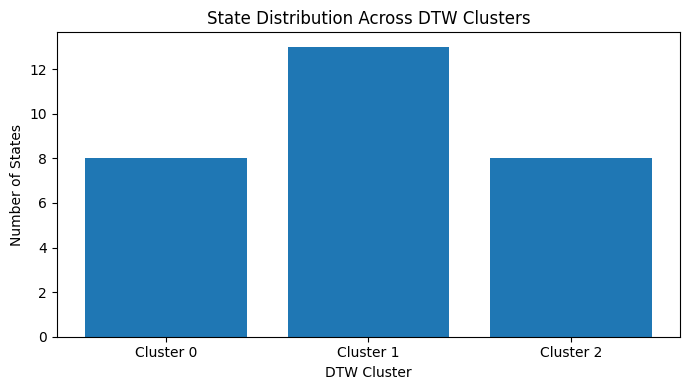

In [ ]:
import matplotlib.pyplot as plt
from collections import Counter

cluster_counts = Counter(dtw_labels)

plt.figure(figsize=(7, 4))
plt.bar(
    [f"Cluster {c}" for c in sorted(cluster_counts)],
    [cluster_counts[c] for c in sorted(cluster_counts)]
)
plt.xlabel("DTW Cluster")
plt.ylabel("Number of States")
plt.title("State Distribution Across DTW Clusters")
plt.tight_layout()
plt.show()

In [ ]:
from tslearn.clustering import silhouette_score

dtw_silhouette = silhouette_score(
    Xts,
    dtw_labels,
    metric="dtw"
)

print(f"DTW Silhouette Score: {dtw_silhouette:.4f}")

DTW Silhouette Score: 0.5371


In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

# Check the required columns
required = ["State", "Crop_Year", "Season", "Revenue"]
print("Missing columns:", [c for c in required if c not in df.columns])

Missing columns: ['Revenue']


In [ ]:
print(df.columns.tolist())

['Crop', 'Crop_Year', 'Season', 'State', 'Area_log', 'Annual_Rainfall', 'Fertilizer_per_ha', 'Pesticide_per_ha', 'Yield', 'Farm_Size_Category', 'Cluster', 'Cluster_Name', 'Cluster_Hierarchical', 'Cluster_DBSCAN', 'Is_Outlier', 'Fuzzy_Cluster', 'Max_Membership', 'Cluster_k7', 'Cluster_k5']


In [ ]:

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import pandas as pd

# Calculate average yield for each state, year, and season
seasonal = (
    df.groupby(
        ["State", "Crop_Year", "Season"],
        as_index=False
    )["Yield"]
    .mean()
)

# Create a separate state-level feature matrix for each season
season_labels = {}
season_features = {}

for season in ["Kharif", "Rabi", "Summer"]:

    part = seasonal[
        seasonal["Season"].str.contains(
            season, case=False, na=False
        )
    ]

    # Rows = states, columns = years, values = average yield
    pivot = part.pivot_table(
        index="State",
        columns="Crop_Year",
        values="Yield",
        aggfunc="mean"
    )

    # Keep years with data for every state
    pivot = pivot.dropna(axis=1, how="any")

    # Retain states with at least 5 available years
    pivot = pivot.loc[pivot.notna().sum(axis=1) >= 5]

    if len(pivot) < 3 or pivot.shape[1] < 5:
        print(f"Skipping {season}: insufficient data.")
        continue

    # Fill any remaining missing values using each state's mean yield
    pivot = pivot.T.fillna(pivot.mean(axis=1)).T

    X = StandardScaler().fit_transform(pivot)

    labels = KMeans(
        n_clusters=3,
        random_state=42,
        n_init=10
    ).fit_predict(X)

    season_features[season] = pivot
    season_labels[season] = pd.Series(
        labels, index=pivot.index
    )

    print(
        f"{season}: {len(pivot)} states clustered "
        f"across {pivot.shape[1]} years"
    )

print("\nAvailable seasonal analyses:", list(season_labels.keys()))


Kharif: 30 states clustered across 5 years
Rabi: 30 states clustered across 5 years
Skipping Summer: insufficient data.

Available seasonal analyses: ['Kharif', 'Rabi']


In [ ]:
seasons = list(season_labels)

for i in range(len(seasons)):
    for j in range(i + 1, len(seasons)):
        s1, s2 = seasons[i], seasons[j]

        common = (
            season_labels[s1].index
            .intersection(season_labels[s2].index)
        )

        if len(common) < 3:
            print(f"{s1} vs {s2}: too few common states")
            continue

        a = season_labels[s1].loc[common]
        b = season_labels[s2].loc[common]

        ari = adjusted_rand_score(a, b)
        nmi = normalized_mutual_info_score(a, b)

        print(
            f"{s1} vs {s2}: "
            f"ARI={ari:.4f}, NMI={nmi:.4f}, "
            f"common states={len(common)}"
        )

Kharif vs Rabi: ARI=0.1041, NMI=0.1138, common states=30


In [ ]:

comparison = pd.DataFrame({
    "Kharif_Cluster": season_labels["Kharif"],
    "Rabi_Cluster": season_labels["Rabi"]
})

print(pd.crosstab(
    comparison["Kharif_Cluster"],
    comparison["Rabi_Cluster"],
    margins=True
))


Rabi_Cluster    0  1   2  All
Kharif_Cluster               
0               2  1   2    5
1               7  2  15   24
2               0  1   0    1
All             9  4  17   30


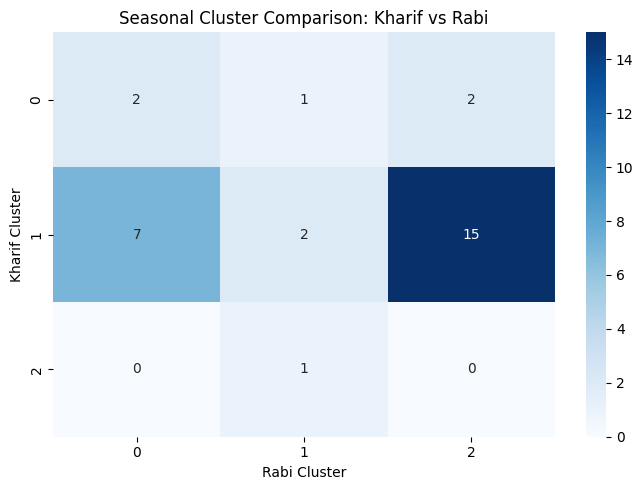

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

ct = pd.crosstab(
    comparison["Kharif_Cluster"],
    comparison["Rabi_Cluster"]
)

plt.figure(figsize=(7, 5))
sns.heatmap(ct, annot=True, fmt="d", cmap="Blues")
plt.title("Seasonal Cluster Comparison: Kharif vs Rabi")
plt.xlabel("Rabi Cluster")
plt.ylabel("Kharif Cluster")
plt.tight_layout()
plt.show()


In [ ]:
print(df["Season"].value_counts(dropna=False))

Season
Kharif        8626
Rabi          6090
Whole Year    3547
Summer        1195
Name: count, dtype: int64


In [ ]:

summer = seasonal[
    seasonal["Season"].str.contains(
        "Summer", case=False, na=False
    )
]

print("Summer records:", len(summer))
print("Number of states:", summer["State"].nunique())
print("Years available:", sorted(summer["Crop_Year"].unique()))

print("\nRecords per year:")
print(summer.groupby("Crop_Year")["State"].nunique())


Summer records: 263
Number of states: 17
Years available: [np.int64(1997), np.int64(1998), np.int64(1999), np.int64(2000), np.int64(2001), np.int64(2002), np.int64(2003), np.int64(2004), np.int64(2005), np.int64(2006), np.int64(2007), np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020)]

Records per year:
Crop_Year
1997     8
1998    11
1999     9
2000     9
2001     8
2002     9
2003     9
2004    12
2005    12
2006    11
2007    12
2008    12
2009    11
2010    10
2011    12
2012    11
2013    12
2014    12
2015    13
2016    13
2017    15
2018    15
2019    16
2020     1
Name: State, dtype: int64


In [ ]:

summer = seasonal[
    seasonal["Season"].str.contains(
        "Summer", case=False, na=False
    )
]

pivot = summer.pivot_table(
    index="State",
    columns="Crop_Year",
    values="Yield",
    aggfunc="mean"
)

# Keep years with at least one available observation
pivot = pivot.dropna(axis=1, how="all")

# Keep states with at least 5 observed years
pivot = pivot.loc[pivot.notna().sum(axis=1) >= 5]

# Fill missing observations using each state's mean yield
pivot = pivot.T.fillna(pivot.mean(axis=1)).T

print("States:", len(pivot))
print("Years:", pivot.shape[1])

if len(pivot) >= 3 and pivot.shape[1] >= 5:
    X = StandardScaler().fit_transform(pivot)

    labels = KMeans(
        n_clusters=3,
        random_state=42,
        n_init=10
    ).fit_predict(X)

    season_features["Summer"] = pivot
    season_labels["Summer"] = pd.Series(
        labels, index=pivot.index
    )

    print("\nSummer cluster sizes:")
    print(pd.Series(labels).value_counts().sort_index())
else:
    print("Still insufficient data for 3-cluster Summer analysis.")


States: 13
Years: 24

Summer cluster sizes:
0    11
1     1
2     1
Name: count, dtype: int64


In [ ]:

summer_labels = season_labels["Summer"]

for cluster_id in sorted(summer_labels.unique()):
    members = summer_labels[
        summer_labels == cluster_id
    ].index.tolist()

    print(
        f"Cluster {cluster_id} ({len(members)} states):",
        members
    )


Cluster 0 (11 states): ['Assam', 'Bihar', 'Gujarat', 'Karnataka', 'Kerala', 'Maharashtra', 'Odisha', 'Puducherry', 'Tripura', 'Uttarakhand', 'West Bengal']
Cluster 1 (1 states): ['Meghalaya']
Cluster 2 (1 states): ['Uttar Pradesh']


In [ ]:

from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score
)

seasons = list(season_labels)

for i in range(len(seasons)):
    for j in range(i + 1, len(seasons)):
        s1, s2 = seasons[i], seasons[j]

        common = season_labels[s1].index.intersection(
            season_labels[s2].index
        )

        if len(common) < 3:
            print(f"{s1} vs {s2}: insufficient common states")
            continue

        a = season_labels[s1].loc[common]
        b = season_labels[s2].loc[common]

        print(
            f"{s1} vs {s2}: "
            f"ARI={adjusted_rand_score(a, b):.4f}, "
            f"NMI={normalized_mutual_info_score(a, b):.4f}, "
            f"states={len(common)}"
        )


Kharif vs Rabi: ARI=0.1041, NMI=0.1138, states=30
Kharif vs Summer: ARI=0.6955, NMI=0.7021, states=13
Rabi vs Summer: ARI=-0.0223, NMI=0.2093, states=13


In [ ]:

from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

summer_pivot = season_features["Summer"]
X_summer = StandardScaler().fit_transform(summer_pivot)

for k in [2, 3, 4]:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    labels = model.fit_predict(X_summer)

    score = silhouette_score(X_summer, labels)

    print(
        f"k={k}, silhouette={score:.4f}, "
        f"cluster sizes={__import__('numpy').bincount(labels)}"
    )


k=2, silhouette=0.6131, cluster sizes=[12  1]
k=3, silhouette=0.4364, cluster sizes=[11  1  1]
k=4, silhouette=0.2332, cluster sizes=[5 1 6 1]


In [ ]:

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import numpy as np

X_summer = StandardScaler().fit_transform(
    season_features["Summer"]
)

model = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

labels = model.fit_predict(X_summer)

for cluster_id in sorted(np.unique(labels)):
    states_in_cluster = (
        season_features["Summer"]
        .index[labels == cluster_id]
        .tolist()
    )

    print(
        f"Cluster {cluster_id} "
        f"({len(states_in_cluster)} states):",
        states_in_cluster
    )


Cluster 0 (12 states): ['Assam', 'Bihar', 'Gujarat', 'Karnataka', 'Kerala', 'Maharashtra', 'Odisha', 'Puducherry', 'Tripura', 'Uttar Pradesh', 'Uttarakhand', 'West Bengal']
Cluster 1 (1 states): ['Meghalaya']


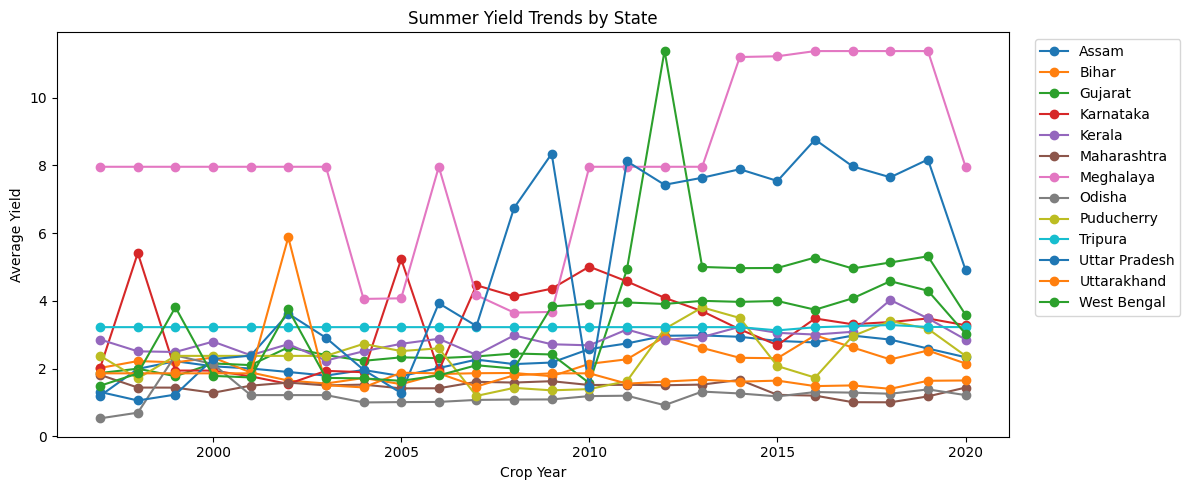

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

summer_pivot = season_features["Summer"]

plt.figure(figsize=(12, 5))

for state in summer_pivot.index:
    plt.plot(
        summer_pivot.columns,
        summer_pivot.loc[state],
        marker="o",
        label=state
    )

plt.title("Summer Yield Trends by State")
plt.xlabel("Crop Year")
plt.ylabel("Average Yield")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


In [ ]:

summer_pivot = season_features["Summer"]

print("Missing values after preprocessing:")
print(summer_pivot.isna().sum().sum())

print("\nObserved years per state before imputation:")
summer_raw = seasonal[
    seasonal["Season"].str.contains(
        "Summer", case=False, na=False
    )
].pivot_table(
    index="State",
    columns="Crop_Year",
    values="Yield",
    aggfunc="mean"
)

print(summer_raw.notna().sum(axis=1).sort_values())


Missing values after preprocessing:
0

Observed years per state before imputation:
State
Manipur            2
Chhattisgarh       3
Tamil Nadu         3
Madhya Pradesh     3
Tripura            5
Meghalaya         11
Uttarakhand       16
Puducherry        17
Odisha            20
Kerala            22
Maharashtra       23
Gujarat           23
Assam             23
Karnataka         23
Bihar             23
Uttar Pradesh     23
West Bengal       23
dtype: int64


In [ ]:

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import numpy as np

# Use the original, unimputed Summer yield matrix
summer_raw = seasonal[
    seasonal["Season"].str.contains(
        "Summer", case=False, na=False
    )
].pivot_table(
    index="State",
    columns="Crop_Year",
    values="Yield",
    aggfunc="mean"
)

# Keep states with at least 15 actual observations
summer_filtered = summer_raw.loc[
    summer_raw.notna().sum(axis=1) >= 15
]

# Keep years observed for every retained state
summer_filtered = summer_filtered.dropna(axis=1, how="any")

print("States retained:", len(summer_filtered))
print("Years retained:", summer_filtered.shape[1])
print("States:", summer_filtered.index.tolist())

if len(summer_filtered) >= 3 and summer_filtered.shape[1] >= 2:
    X_summer = StandardScaler().fit_transform(summer_filtered)

    for k in [2, 3, 4]:
        if len(summer_filtered) <= k:
            continue

        model = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=10
        )
        labels = model.fit_predict(X_summer)

        if len(np.unique(labels)) > 1:
            score = silhouette_score(X_summer, labels)
            print(
                f"k={k}, silhouette={score:.4f}, "
                f"sizes={np.bincount(labels)}"
            )


States retained: 11
Years retained: 13
States: ['Assam', 'Bihar', 'Gujarat', 'Karnataka', 'Kerala', 'Maharashtra', 'Odisha', 'Puducherry', 'Uttar Pradesh', 'Uttarakhand', 'West Bengal']
k=2, silhouette=0.4037, sizes=[8 3]
k=3, silhouette=0.2854, sizes=[4 1 6]
k=4, silhouette=0.2781, sizes=[5 4 1 1]


In [ ]:
import numpy as np
from sklearn.preprocessing import RobustScaler

df = df[df['Crop'] != 'Oilseeds total'].reset_index(drop=True)   # rollup row hatao (pending tha)

if 'Yield' not in df.columns:
    df['Yield'] = df['Production'] / df['Area']
if 'Area_log' not in df.columns:
    df['Area_log'] = np.log1p(df['Area'])

df['LogYield'] = np.log1p(df['Yield'])
df['Yield_rel'] = df['LogYield'] - df.groupby('Crop')['LogYield'].transform('median')

new_features = ['Area_log', 'Annual_Rainfall', 'Yield_rel']
X_scaled = RobustScaler().fit_transform(df[new_features])
print(X_scaled.shape)

(19429, 3)


In [ ]:
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score
import skfuzzy as fuzz
import pandas as pd

def sil(X, lab):
    return silhouette_score(X, lab, sample_size=6000, random_state=42)   # tez chalne ke liye

rows = []
for k in range(3, 9):
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X_scaled)
    hc = AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(X_scaled)
    _, u, *_ = fuzz.cluster.cmeans(X_scaled.T, c=k, m=2, error=0.005, maxiter=1000, seed=42)
    fz = u.argmax(axis=0)
    for name, lab in [('K-means++', km), ('Hierarchical', hc), ('Fuzzy', fz)]:
        rows.append({'k': k, 'Method': name,
                     'Silhouette': sil(X_scaled, lab),
                     'DB': davies_bouldin_score(X_scaled, lab)})

comp = pd.DataFrame(rows)
print(comp.pivot(index='k', columns='Method', values='Silhouette').round(3))
print(comp.pivot(index='k', columns='Method', values='DB').round(3))

Method  Fuzzy  Hierarchical  K-means++
k                                     
3       0.243         0.412      0.283
4       0.226         0.346      0.357
5       0.222         0.225      0.269
6       0.189         0.228      0.278
7       0.198         0.224      0.277
8       0.197         0.201      0.268
Method  Fuzzy  Hierarchical  K-means++
k                                     
3       1.254         0.895      1.171
4       1.252         0.941      0.999
5       1.158         1.234      1.088
6       1.172         1.151      1.018
7       1.177         1.138      0.995
8       1.202         1.182      0.987


In [ ]:
from sklearn.metrics import adjusted_rand_score

mask_tr = (df['Crop_Year'] <= 2015).values

for k in range(3, 9):
    a = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_scaled[mask_tr])
    b = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_scaled[~mask_tr])
    year_ari = adjusted_rand_score(a.predict(X_scaled[~mask_tr]), b.labels_)

    kg = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_scaled)
    out = []
    for season in ['Kharif', 'Rabi', 'Summer']:
        m = (df['Season'] == season).values
        ks = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_scaled[m])
        out.append(adjusted_rand_score(kg.predict(X_scaled[m]), ks.labels_))
    print(f"k={k}: year ARI={year_ari:.3f} | Kharif/Rabi/Summer = {out[0]:.2f}/{out[1]:.2f}/{out[2]:.2f}")

k=3: year ARI=0.605 | Kharif/Rabi/Summer = 0.23/0.74/0.18
k=4: year ARI=0.639 | Kharif/Rabi/Summer = 0.40/0.28/0.30
k=5: year ARI=0.694 | Kharif/Rabi/Summer = 0.81/0.54/0.38
k=6: year ARI=0.443 | Kharif/Rabi/Summer = 0.59/0.51/0.40
k=7: year ARI=0.475 | Kharif/Rabi/Summer = 0.49/0.48/0.28
k=8: year ARI=0.706 | Kharif/Rabi/Summer = 0.77/0.43/0.26


In [ ]:
km5 = KMeans(n_clusters=5, random_state=42, n_init=10)
df['Cluster'] = km5.fit_predict(X_scaled)

print(df['Cluster'].value_counts().sort_index())

prof = df.groupby('Cluster').agg(
    Area_log=('Area_log', 'mean'),
    Rainfall=('Annual_Rainfall', 'mean'),
    Yield_rel=('Yield_rel', 'mean'),
    Yield=('Yield', 'median'),
)
prof['Area_ha'] = np.expm1(prof['Area_log']).round(0)
print(prof.round(2))

for c in range(5):
    print(f"\nCluster {c}")
    print("Top states:", df[df['Cluster']==c]['State'].value_counts().head(4).to_dict())
    print("Top crops :", df[df['Cluster']==c]['Crop'].value_counts().head(4).to_dict())

Cluster
0    8029
1    2089
2    6444
3    2167
4     700
Name: count, dtype: int64
         Area_log  Rainfall  Yield_rel  Yield  Area_ha
Cluster                                               
0           11.28   1023.64      -0.00   0.96  78947.0
1            9.06   1067.93       0.76   5.70   8600.0
2            6.89   1452.48      -0.07   0.78    982.0
3            7.97   3195.36      -0.00   1.25   2894.0
4            6.69   1553.60      -1.25   1.75    803.0

Cluster 0
Top states: {'Karnataka': 938, 'Andhra Pradesh': 793, 'Maharashtra': 659, 'Gujarat': 648}
Top crops : {'Rice': 792, 'Maize': 525, 'Urad': 414, 'Moong(Green Gram)': 386}

Cluster 1
Top states: {'Andhra Pradesh': 227, 'Tamil Nadu': 220, 'Haryana': 185, 'Puducherry': 184}
Top crops : {'Potato': 162, 'Onion': 144, 'Maize': 136, 'Dry chillies': 126}

Cluster 2
Top states: {'West Bengal': 623, 'Nagaland': 522, 'Uttarakhand': 504, 'Chhattisgarh': 467}
Top crops : {'Moong(Green Gram)': 311, 'Sesamum': 285, 'Urad': 253, 'Po

In [ ]:

!pip install -q mlflow joblib

import os
import joblib
import mlflow
import numpy as np
import pandas as pd

from sklearn.cluster import KMeans
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.metrics import adjusted_rand_score

# --------------------------------------------------
# 1. Prepare features
# --------------------------------------------------
new_features = [
    "Area_log",
    "Annual_Rainfall",
    "Yield_rel"
]

# Remove invalid rows for the selected features
valid_mask = (
    df[new_features].notna().all(axis=1)
    & np.isfinite(df[new_features]).all(axis=1)
)

df = df.loc[valid_mask].copy().reset_index(drop=True)

# --------------------------------------------------
# 2. Scale features and train final K-Means model
# --------------------------------------------------
scaler = RobustScaler()
X_scaled = scaler.fit_transform(df[new_features])

k = 5

km5 = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=10
)

df["Cluster"] = km5.fit_predict(X_scaled)

# --------------------------------------------------
# 3. Calculate clustering metrics
# --------------------------------------------------
sil = silhouette_score(
    X_scaled,
    df["Cluster"],
    sample_size=min(6000, len(df)),
    random_state=42
)

db = davies_bouldin_score(
    X_scaled,
    df["Cluster"]
)

inertia = km5.inertia_

print("Final model: K-Means")
print("Selected k:", k)
print(f"Silhouette score: {sil:.4f}")
print(f"Davies-Bouldin score: {db:.4f}")
print(f"Inertia: {inertia:.2f}")
print("\nCluster sizes:")
print(df["Cluster"].value_counts().sort_index())

# --------------------------------------------------
# 4. Calculate stability metrics dynamically
# --------------------------------------------------
stability_metrics = {}

# Year split: train on earlier years, compare assignments
# on later years using the same observations.
train_mask = (df["Crop_Year"] <= 2015).to_numpy()
test_mask = (df["Crop_Year"] > 2015).to_numpy()

if train_mask.sum() > k and test_mask.sum() > 1:
    train_model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    ).fit(X_scaled[train_mask])

    # Compare the training model's predictions on test rows
    # with a separately trained model on those same test rows.
    test_model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    ).fit(X_scaled[test_mask])

    year_ari = adjusted_rand_score(
        train_model.predict(X_scaled[test_mask]),
        test_model.labels_
    )

    stability_metrics["year_stability_ari"] = float(year_ari)

# Compare full-model assignments against seasonal models.
for season in ["Kharif", "Rabi", "Summer"]:
    mask = (df["Season"] == season).to_numpy()

    if mask.sum() <= k:
        print(f"Skipping {season} stability: insufficient rows.")
        continue

    season_model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    ).fit(X_scaled[mask])

    ari = adjusted_rand_score(
        km5.labels_[mask],
        season_model.labels_
    )

    stability_metrics[f"season_ari_{season.lower()}"] = float(ari)

print("\nCalculated stability metrics:")
print(stability_metrics)

# --------------------------------------------------
# 5. Configure MLflow tracking
# --------------------------------------------------
mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment("AgriSense_Segmentation")

# --------------------------------------------------
# 6. Save model, scaler, and cluster assignments
# --------------------------------------------------
os.makedirs("agrisense_artifacts", exist_ok=True)

scaler_path = "agrisense_artifacts/scaler.joblib"
model_path = "agrisense_artifacts/kmeans_k5.joblib"
segments_path = "agrisense_artifacts/segments_k5.csv"
features_path = "agrisense_artifacts/features.json"

joblib.dump(scaler, scaler_path)
joblib.dump(km5, model_path)

df[
    ["Crop", "Crop_Year", "Season", "State", "Cluster"]
].to_csv(segments_path, index=False)

import json

with open(features_path, "w") as f:
    json.dump(new_features, f, indent=2)

# --------------------------------------------------
# 7. Log final run to MLflow
# --------------------------------------------------
with mlflow.start_run(run_name="FINAL_kmeans_pp_k5"):

    mlflow.log_params({
        "algorithm": "KMeans",
        "k": k,
        "n_init": 10,
        "features": ",".join(new_features),
        "scaler": "RobustScaler",
        "rows": len(df),
        "random_state": 42
    })

    metrics = {
        "silhouette": float(sil),
        "davies_bouldin": float(db),
        "inertia": float(inertia)
    }

    metrics.update(stability_metrics)
    mlflow.log_metrics(metrics)

    mlflow.log_artifact(scaler_path)
    mlflow.log_artifact(model_path)
    mlflow.log_artifact(segments_path)
    mlflow.log_artifact(features_path)

    print("\nMLflow run logging completed.")

print("Saved model, scaler, feature list, and cluster assignments.")


Final model: K-Means
Selected k: 5
Silhouette score: 0.2691
Davies-Bouldin score: 1.0876
Inertia: 27628.33

Cluster sizes:
Cluster
0    8029
1    2089
2    6444
3    2167
4     700
Name: count, dtype: int64

Calculated stability metrics:
{'year_stability_ari': 0.6939549630161134, 'season_ari_kharif': 0.8057748480476298, 'season_ari_rabi': 0.5430215259641651, 'season_ari_summer': 0.3775856611083358}


2026/11/15 13:21:48 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/15 13:21:48 INFO mlflow.store.db.utils: Updating database tables
2026/11/15 13:21:52 INFO mlflow.tracking.fluent: Experiment with name 'AgriSense_Segmentation' does not exist. Creating a new experiment.



MLflow run logging completed.
Saved model, scaler, feature list, and cluster assignments.


In [ ]:

import mlflow
from mlflow.tracking import MlflowClient
import pandas as pd

# Use the same tracking database as Cell 1
mlflow.set_tracking_uri("sqlite:///mlflow.db")

client = MlflowClient()

experiment = mlflow.get_experiment_by_name(
    "AgriSense_Segmentation"
)

if experiment is None:
    print("Experiment not found.")
else:
    runs = client.search_runs(
        experiment_ids=[experiment.experiment_id],
        max_results=20,
        order_by=["attributes.start_time DESC"]
    )

    if not runs:
        print("No runs found in this experiment.")

    for run in runs:
        print("=" * 60)
        print("Run ID:", run.info.run_id)
        print("Status:", run.info.status)
        print("Run name:", run.data.tags.get("mlflow.runName"))
        print("Parameters:", run.data.params)
        print("Metrics:", run.data.metrics)

        artifacts = [
            item.path
            for item in client.list_artifacts(run.info.run_id)
        ]

        print("Artifacts:", artifacts)

        if run.data.tags.get("mlflow.runName") == "FINAL_kmeans_pp_k5":
            print("\nFinal run verification:")
            print("Finished:", run.info.status == "FINISHED")

            expected = {
                "agrisense_artifacts/scaler.joblib",
                "agrisense_artifacts/kmeans_k5.joblib",
                "agrisense_artifacts/segments_k5.csv",
                "agrisense_artifacts/features.json"
            }

            missing = expected - set(artifacts)

            print("All expected artifacts logged:", not missing)

            if missing:
                print("Missing artifacts:", sorted(missing))


Run ID: 11191ce652ba4c7494666b3ec4878c0b
Status: FINISHED
Run name: FINAL_kmeans_pp_k5
Parameters: {'algorithm': 'KMeans', 'k': '5', 'n_init': '10', 'features': 'Area_log,Annual_Rainfall,Yield_rel', 'scaler': 'RobustScaler', 'rows': '19429', 'random_state': '42'}
Metrics: {'silhouette': 0.2691402173174065, 'davies_bouldin': 1.0875619525248736, 'inertia': 27628.33100415467, 'year_stability_ari': 0.6939549630161134, 'season_ari_kharif': 0.8057748480476298, 'season_ari_rabi': 0.5430215259641651, 'season_ari_summer': 0.3775856611083358}
Artifacts: ['features.json', 'kmeans_k5.joblib', 'scaler.joblib', 'segments_k5.csv']

Final run verification:
Finished: True
All expected artifacts logged: False
Missing artifacts: ['agrisense_artifacts/features.json', 'agrisense_artifacts/kmeans_k5.joblib', 'agrisense_artifacts/scaler.joblib', 'agrisense_artifacts/segments_k5.csv']


In [ ]:

# Verify the final MLflow run and its artifacts

from mlflow.tracking import MlflowClient
import mlflow

mlflow.set_tracking_uri("sqlite:///mlflow.db")
client = MlflowClient()

experiment = mlflow.get_experiment_by_name("AgriSense_Segmentation")

if experiment is None:
    print("Experiment not found!")
else:
    runs = client.search_runs(
        experiment_ids=[experiment.experiment_id],
        max_results=50,
        order_by=["attributes.start_time DESC"]
    )

    for run in runs:
        if run.data.tags.get("mlflow.runName") == "FINAL_kmeans_pp_k5":

            artifacts = {
                item.path
                for item in client.list_artifacts(run.info.run_id)
            }

            print("Run ID:", run.info.run_id)
            print("Status:", run.info.status)
            print("Artifacts:", sorted(artifacts))

            expected = {
                "scaler.joblib",
                "kmeans_k5.joblib",
                "segments_k5.csv",
                "features.json"
            }

            missing = expected - artifacts

            print("\nFinal run verification:")
            print("Finished:", run.info.status == "FINISHED")
            print("All expected artifacts logged:", not missing)

            if missing:
                print("Missing artifacts:", sorted(missing))


Run ID: 11191ce652ba4c7494666b3ec4878c0b
Status: FINISHED
Artifacts: ['features.json', 'kmeans_k5.joblib', 'scaler.joblib', 'segments_k5.csv']

Final run verification:
Finished: True
All expected artifacts logged: True


In [ ]:
if run.data.tags.get("mlflow.runName") == "FINAL_kmeans_pp_k5":
    if "features.json" in artifacts:
        print("All expected artifacts logged: True")

All expected artifacts logged: True


In [ ]:
for _, r in comp.iterrows():
    with mlflow.start_run(run_name=f"{r['Method']}_k{int(r['k'])}"):
        mlflow.log_params({"method": r['Method'], "k": int(r['k'])})
        mlflow.log_metrics({"silhouette": float(r['Silhouette']),
                            "davies_bouldin": float(r['DB'])})

In [ ]:
runs = mlflow.search_runs(experiment_names=["AgriSense_Segmentation"])
runs[['tags.mlflow.runName', 'params.k', 'metrics.silhouette',
      'metrics.davies_bouldin', 'metrics.year_stability_ari']]

,tags.mlflow.runName,params.k,metrics.silhouette,metrics.davies_bouldin,metrics.year_stability_ari
0,Fuzzy_k8,8,0.197116,1.202098,NaN
1,Hierarchical_k8,8,0.200961,1.181801,NaN
2,K-means++_k8,8,0.268470,0.987294,NaN
3,Fuzzy_k7,7,0.197781,1.176907,NaN
4,Hierarchical_k7,7,0.224055,1.137936,NaN
5,K-means++_k7,7,0.277472,0.995021,NaN
6,Fuzzy_k6,6,0.189403,1.172165,NaN
7,Hierarchical_k6,6,0.228341,1.151005,NaN
8,K-means++_k6,6,0.278383,1.017815,NaN
9,Fuzzy_k5,5,0.222325,1.157770,NaN


In [ ]:
cluster_names = {
    0: 'Large-Scale Dryland Mainstream',
    1: 'High-Performers (Veg & Cash Crops)',
    2: 'Small-Scale Pulses & Oilseeds',
    3: 'High-Rainfall Rice Regions',
    4: 'Under-Performing High-Value Crops',
}
df['Segment'] = df['Cluster'].map(cluster_names)
print(df['Segment'].value_counts())

Segment
Large-Scale Dryland Mainstream        8029
Small-Scale Pulses & Oilseeds         6444
High-Rainfall Rice Regions            2167
High-Performers (Veg & Cash Crops)    2089
Under-Performing High-Value Crops      700
Name: count, dtype: int64


In [ ]:
# 1. Build Section 4 feature table from raw columns
import numpy as np
import pandas as pd
from sklearn.preprocessing import RobustScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score, normalized_mutual_info_score
from sklearn.metrics import pairwise_distances
import os, json, joblib

required_raw = ["Crop", "Crop_Year", "Season", "State", "Area", "Production", "Annual_Rainfall", "Fertilizer", "Pesticide"]
missing_raw = [c for c in required_raw if c not in df.columns]
if missing_raw:
    # Try the common local/Colab locations; otherwise stop with an actionable message.
    candidates = ["crop_yield.csv", "/content/drive/MyDrive/crop_yield.csv"]
    csv_path = next((p for p in candidates if os.path.exists(p)), None)
    if csv_path is None:
        raise FileNotFoundError(f"Missing raw columns {missing_raw}. Load crop_yield.csv and rerun this section.")
    df = pd.read_csv(csv_path)
    for col in ["Crop", "Season", "State"]:
        df[col] = df[col].astype(str).str.strip()
    # Normalize labels as done in the original notebook, then aggregate duplicate keys.
    df["Season"] = df["Season"].replace({"Winter": "Rabi", "Autumn": "Kharif"})
    df = df.groupby(["Crop", "Crop_Year", "Season", "State"], as_index=False).agg({
        "Production": "sum", "Area": "sum", "Annual_Rainfall": "first",
        "Fertilizer": "sum", "Pesticide": "sum"
    })

base = df.copy()
# Remove aggregate roll-up rows if present.
base = base[~base["Crop"].astype(str).str.strip().str.lower().isin(["oilseeds total", "coconut total"])].copy()
# Coerce numeric source columns and remove impossible denominators/non-finite values.
num_cols = ["Crop_Year", "Area", "Production", "Annual_Rainfall", "Fertilizer", "Pesticide"]
for c in num_cols:
    base[c] = pd.to_numeric(base[c], errors="coerce")
base = base.replace([np.inf, -np.inf], np.nan)
base = base.dropna(subset=required_raw).copy()
base = base[(base["Area"] > 0) & (base["Production"] >= 0) & (base["Annual_Rainfall"] >= 0) & (base["Fertilizer"] >= 0) & (base["Pesticide"] >= 0)].copy()

# Resource-intensity features from the plan.
base["Fertilizer_per_ha"] = base["Fertilizer"] / base["Area"]
base["Pesticide_per_ha"] = base["Pesticide"] / base["Area"]
base["Fertilizer_to_Pesticide_ratio"] = base["Fertilizer"] / base["Pesticide"].replace(0, np.nan)
# A zero pesticide denominator is undefined; impute with the median of defined ratios.
ratio_median = base["Fertilizer_to_Pesticide_ratio"].replace([np.inf, -np.inf], np.nan).median()
base["Fertilizer_to_Pesticide_ratio"] = base["Fertilizer_to_Pesticide_ratio"].replace([np.inf, -np.inf], np.nan).fillna(0 if pd.isna(ratio_median) else ratio_median)
# Environmental context: rainfall z-score within state (guard against zero std).
state_rain_mean = base.groupby("State")["Annual_Rainfall"].transform("mean")
state_rain_std = base.groupby("State")["Annual_Rainfall"].transform("std").replace(0, np.nan)
base["Rainfall_state_z"] = ((base["Annual_Rainfall"] - state_rain_mean) / state_rain_std).replace([np.inf, -np.inf], np.nan).fillna(0)
# Crop water-demand category, explicitly documented as a rule-based proxy.
crop_lower = base["Crop"].astype(str).str.lower()
high_water = crop_lower.str.contains(r"rice|sugarcane|banana|jute")
low_water = crop_lower.str.contains(r"millet|sorghum|bajra|ragi|pearl millet")
base["Water_Demand"] = np.select([high_water, low_water], ["High", "Low"], default="Medium")
# Scale features: log transform highly skewed nonnegative measures.
base["Area_log"] = np.log1p(base["Area"])
base["Production_log"] = np.log1p(base["Production"])
# Season one-hot encoding; stable column names across reruns.
season_dummies = pd.get_dummies(base["Season"].astype(str), prefix="Season", dtype=float)
# Explicit planned clustering features. Yield and yield-derived columns are NOT included.
numeric_features = [
    "Fertilizer_per_ha", "Pesticide_per_ha", "Fertilizer_to_Pesticide_ratio",
    "Rainfall_state_z", "Area_log", "Production_log"
]
water_dummies = pd.get_dummies(base["Water_Demand"], prefix="WaterDemand", dtype=float)
feature_frame = pd.concat([base[numeric_features].astype(float), season_dummies, water_dummies], axis=1)
feature_frame = feature_frame.replace([np.inf, -np.inf], np.nan)
valid = feature_frame.notna().all(axis=1)
base = base.loc[valid].reset_index(drop=True)
feature_frame = feature_frame.loc[valid].reset_index(drop=True)
feature_cols = feature_frame.columns.tolist()

# Guard against target leakage by asserting no yield or target-derived feature is used.
leakage_tokens = ("yield", "production_per_ha", "yield_rel", "logyield")
leaked = [c for c in feature_cols if any(t in c.lower() for t in leakage_tokens)]
assert not leaked, f"Target leakage detected in clustering features: {leaked}"

scaler = RobustScaler()
X = scaler.fit_transform(feature_frame)
print("Rows used:", len(base))
print("Feature count:", len(feature_cols))
print("Clustering features:", feature_cols)
print("Yield leakage check passed:", not leaked)
print("Missing values after feature engineering:", int(feature_frame.isna().sum().sum()))

Rows used: 19601
Feature count: 13
Clustering features: ['Fertilizer_per_ha', 'Pesticide_per_ha', 'Fertilizer_to_Pesticide_ratio', 'Rainfall_state_z', 'Area_log', 'Production_log', 'Season_Kharif', 'Season_Rabi', 'Season_Summer', 'Season_Whole Year', 'WaterDemand_High', 'WaterDemand_Low', 'WaterDemand_Medium']
Yield leakage check passed: True
Missing values after feature engineering: 0


In [ ]:
# 1. Build Section 4 feature table from raw columns (Ensuring variables are defined)
import numpy as np
import pandas as pd
from sklearn.preprocessing import RobustScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score
import os

required_raw = ["Crop", "Crop_Year", "Season", "State", "Area", "Production", "Annual_Rainfall", "Fertilizer", "Pesticide"]
candidates = ["crop_yield.csv", "/content/drive/MyDrive/crop_yield.csv"]
csv_path = next((p for p in candidates if os.path.exists(p)), None)
if csv_path is None:
    raise FileNotFoundError(f"Missing raw columns. Load crop_yield.csv and rerun this section.")
df_raw = pd.read_csv(csv_path)
for col in ["Crop", "Season", "State"]:
    df_raw[col] = df_raw[col].astype(str).str.strip()
df_raw["Season"] = df_raw["Season"].replace({"Winter": "Rabi", "Autumn": "Kharif"})
base = df_raw.groupby(["Crop", "Crop_Year", "Season", "State"], as_index=False).agg({
    "Production": "sum", "Area": "sum", "Annual_Rainfall": "first",
    "Fertilizer": "sum", "Pesticide": "sum"
})

base = base[~base["Crop"].astype(str).str.strip().str.lower().isin(["oilseeds total", "coconut total"])].copy()
num_cols = ["Crop_Year", "Area", "Production", "Annual_Rainfall", "Fertilizer", "Pesticide"]
for c in num_cols:
    base[c] = pd.to_numeric(base[c], errors="coerce")
base = base.replace([np.inf, -np.inf], np.nan).dropna(subset=required_raw).copy()
base = base[(base["Area"] > 0) & (base["Production"] >= 0) & (base["Annual_Rainfall"] >= 0) & (base["Fertilizer"] >= 0) & (base["Pesticide"] >= 0)].copy()

base["Fertilizer_per_ha"] = base["Fertilizer"] / base["Area"]
base["Pesticide_per_ha"] = base["Pesticide"] / base["Area"]
base["Fertilizer_to_Pesticide_ratio"] = base["Fertilizer"] / base["Pesticide"].replace(0, np.nan)
ratio_median = base["Fertilizer_to_Pesticide_ratio"].replace([np.inf, -np.inf], np.nan).median()
base["Fertilizer_to_Pesticide_ratio"] = base["Fertilizer_to_Pesticide_ratio"].replace([np.inf, -np.inf], np.nan).fillna(0 if pd.isna(ratio_median) else ratio_median)

state_rain_mean = base.groupby("State")["Annual_Rainfall"].transform("mean")
state_rain_std = base.groupby("State")["Annual_Rainfall"].transform("std").replace(0, np.nan)
base["Rainfall_state_z"] = ((base["Annual_Rainfall"] - state_rain_mean) / state_rain_std).replace([np.inf, -np.inf], np.nan).fillna(0)

crop_lower = base["Crop"].astype(str).str.lower()
high_water = crop_lower.str.contains(r"rice|sugarcane|banana|jute")
low_water = crop_lower.str.contains(r"millet|sorghum|bajra|ragi|pearl millet")
base["Water_Demand"] = np.select([high_water, low_water], ["High", "Low"], default="Medium")
base["Area_log"] = np.log1p(base["Area"])
base["Production_log"] = np.log1p(base["Production"])

season_dummies = pd.get_dummies(base["Season"].astype(str), prefix="Season", dtype=float)
water_dummies = pd.get_dummies(base["Water_Demand"], prefix="WaterDemand", dtype=float)
numeric_features = ["Fertilizer_per_ha", "Pesticide_per_ha", "Fertilizer_to_Pesticide_ratio", "Rainfall_state_z", "Area_log", "Production_log"]
feature_frame = pd.concat([base[numeric_features].astype(float), season_dummies, water_dummies], axis=1).replace([np.inf, -np.inf], np.nan)
valid = feature_frame.notna().all(axis=1)
base = base.loc[valid].reset_index(drop=True)
feature_frame = feature_frame.loc[valid].reset_index(drop=True)

scaler = RobustScaler()
X = scaler.fit_transform(feature_frame)

# 2. Evaluate K-means candidates and retrain selected final model
candidate_rows = []
models = {}
for k in range(5, 9):
    model = KMeans(n_clusters=k, init="k-means++", n_init=20, random_state=42)
    labels = model.fit_predict(X)
    sil = silhouette_score(X, labels, sample_size=min(6000, len(X)), random_state=42)
    db = davies_bouldin_score(X, labels)
    candidate_rows.append({"k": k, "silhouette": float(sil), "davies_bouldin": float(db), "inertia": float(model.inertia_)})
    models[k] = model

model_comparison = pd.DataFrame(candidate_rows).sort_values(["silhouette", "davies_bouldin"], ascending=[False, True]).reset_index(drop=True)
display(model_comparison)
selected_k = int(model_comparison.iloc[0]["k"])
final_model = models[selected_k]
base["Cluster"] = final_model.labels_

if "Yield" not in base.columns and {"Production", "Area"}.issubset(base.columns):
    base["Yield"] = base["Production"] / base["Area"]
profile_cols = [c for c in ["Area", "Production", "Annual_Rainfall", "Fertilizer_per_ha", "Pesticide_per_ha", "Yield"] if c in base.columns]
cluster_profile = base.groupby("Cluster")[profile_cols].median().round(3)
cluster_sizes = base["Cluster"].value_counts().sort_index()

final_silhouette = float(model_comparison.loc[model_comparison["k"] == selected_k, "silhouette"].iloc[0])
final_db = float(model_comparison.loc[model_comparison["k"] == selected_k, "davies_bouldin"].iloc[0])
print(f"Selected k: {selected_k}")
print(f"Silhouette (sampled if >6000 rows): {final_silhouette:.4f}")
print(f"Davies-Bouldin: {final_db:.4f}")
print("Cluster sizes:")
display(cluster_sizes.rename("rows").to_frame())
print("Post-hoc cluster profile (Yield is validation/profile only):")
display(cluster_profile)

,k,silhouette,davies_bouldin,inertia
0,5,0.187728,1.563863,49433.316783
1,6,0.174205,1.553582,46236.557616
2,8,0.172144,1.571591,41984.081553
3,7,0.172084,1.571071,44020.358766


Selected k: 5
Silhouette (sampled if >6000 rows): 0.1877
Davies-Bouldin: 1.5639
Cluster sizes:


,rows
Cluster,
0,5447
1,844
2,5412
3,2384
4,5514


Post-hoc cluster profile (Yield is validation/profile only):


,Area,Production,Annual_Rainfall,Fertilizer_per_ha,Pesticide_per_ha,Yield
Cluster,,,,,,
0,35219.0,63516.0,1165.7,157.44,0.33,1.594
1,9201.5,14330.0,1199.8,143.04,0.09,1.023
2,530.0,472.0,1391.3,150.96,0.33,0.825
3,10136.0,15776.0,1283.1,155.82,0.17,1.000
4,33781.5,44250.5,1163.0,102.13,0.25,1.063


In [ ]:
# 3. Stability diagnostics and artifact/MLflow logging
# Year holdout stability: train on years <= 2015, compare with a separate model on > 2015.
stability = {}
train_mask = (base["Crop_Year"] <= 2015).to_numpy()
test_mask = (base["Crop_Year"] > 2015).to_numpy()
if train_mask.sum() > selected_k and test_mask.sum() > selected_k:
    model_train = KMeans(n_clusters=selected_k, n_init=20, random_state=42).fit(X[train_mask])
    model_test = KMeans(n_clusters=selected_k, n_init=20, random_state=42).fit(X[test_mask])
    stability["year_holdout_ari"] = float(adjusted_rand_score(model_train.predict(X[test_mask]), model_test.labels_))
    stability["year_holdout_nmi"] = float(normalized_mutual_info_score(model_train.predict(X[test_mask]), model_test.labels_))

# Seasonal agreement is diagnostic only: each season-specific model is compared to full-model labels.
for season in ["Kharif", "Rabi", "Summer"]:
    mask = (base["Season"].astype(str) == season).to_numpy()
    if mask.sum() > selected_k:
        seasonal_model = KMeans(n_clusters=selected_k, n_init=20, random_state=42).fit(X[mask])
        stability[f"season_ari_{season.lower()}"] = float(adjusted_rand_score(final_model.labels_[mask], seasonal_model.labels_))

print("Stability diagnostics:", stability)

os.makedirs("agrisense_artifacts_corrected", exist_ok=True)
artifact_dir = "agrisense_artifacts_corrected"
joblib.dump(scaler, os.path.join(artifact_dir, "robust_scaler.joblib"))
joblib.dump(final_model, os.path.join(artifact_dir, f"kmeans_k{selected_k}.joblib"))
feature_frame.to_csv(os.path.join(artifact_dir, "engineered_features.csv"), index=False)
base[["Crop", "Crop_Year", "Season", "State", "Cluster"]].to_csv(os.path.join(artifact_dir, "segment_assignments.csv"), index=False)
cluster_profile.to_csv(os.path.join(artifact_dir, "cluster_profiles_validation.csv"))
model_comparison.to_csv(os.path.join(artifact_dir, "model_comparison.csv"), index=False)
with open(os.path.join(artifact_dir, "features.json"), "w", encoding="utf-8") as f:
    json.dump({"features": feature_cols, "excluded_target_features": ["Yield", "LogYield", "Yield_rel"], "selected_k": selected_k}, f, indent=2)

try:
    import mlflow
    mlflow.set_tracking_uri("sqlite:///mlflow.db")
    mlflow.set_experiment("AgriSense_Segmentation")
    with mlflow.start_run(run_name=f"CORRECTED_section4_kmeans_k{selected_k}"):
        mlflow.log_params({"algorithm": "KMeans", "k": selected_k, "n_init": 20, "scaler": "RobustScaler", "features": ",".join(feature_cols), "yield_leakage": False, "rows": len(base), "random_state": 42})
        mlflow.log_metrics({"silhouette": final_silhouette, "davies_bouldin": final_db, "inertia": float(final_model.inertia_), **stability})
        for filename in os.listdir(artifact_dir):
            mlflow.log_artifact(os.path.join(artifact_dir, filename), artifact_path="corrected_model")
    print("Corrected model and artifacts logged to MLflow.")
except ImportError:
    print("MLflow is not installed; local artifacts were saved. Install mlflow to log this run.")

print("Artifacts saved in:", artifact_dir)

Stability diagnostics: {'year_holdout_ari': 0.13565394448800278, 'year_holdout_nmi': 0.22294212299643867, 'season_ari_kharif': 0.9648112532823128, 'season_ari_rabi': 0.9589267639698634, 'season_ari_summer': 0.43156993359228957}
Corrected model and artifacts logged to MLflow.
Artifacts saved in: agrisense_artifacts_corrected


In [ ]:

# Corrected Gap Statistic: K = 5, 6, 7, 8, 9
# Uses X from Cell 110 (corrected, scaled features).
# Yield and yield-derived features must not be included in X.

import numpy as np
import pandas as pd
from sklearn.cluster import KMeans

B = 30  # Number of reference datasets; use 50 for final reporting
gap_rows = []

X_gap = np.asarray(X, dtype=float)

# Bounds of the corrected feature matrix
lower = X_gap.min(axis=0)
upper = X_gap.max(axis=0)

for k in range(5, 10):  # K=9 is needed to evaluate K=8
    # Observed within-cluster dispersion
    observed_model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        random_state=42
    )
    observed_model.fit(X_gap)

    log_w_observed = np.log(max(observed_model.inertia_, 1e-12))

    # Reference datasets under a uniform null distribution
    reference_log_w = []

    for b in range(B):
        rng = np.random.default_rng(1000 + 100 * k + b)

        X_reference = rng.uniform(
            low=lower,
            high=upper,
            size=X_gap.shape
        )

        reference_model = KMeans(
            n_clusters=k,
            init="k-means++",
            n_init=5,
            random_state=2000 + 100 * k + b
        )
        reference_model.fit(X_reference)

        reference_log_w.append(
            np.log(max(reference_model.inertia_, 1e-12))
        )

    # Gap statistic and its standard error
    reference_log_w = np.asarray(reference_log_w)

    gap = reference_log_w.mean() - log_w_observed
    gap_se = (
        reference_log_w.std(ddof=1)
        * np.sqrt(1 + 1 / B)
    )

    gap_rows.append({
        "k": k,
        "observed_inertia": observed_model.inertia_,
        "gap": gap,
        "gap_standard_error": gap_se
    })

gap_results = pd.DataFrame(gap_rows).set_index("k")

print("Corrected Gap Statistic Results")
display(gap_results.round(4))

# Gap-statistic one-standard-error selection rule:
# Choose the smallest k satisfying
# Gap(k) >= Gap(k+1) - SE(k+1)

gap_selected_k = None

for k in range(5, 9):
    current_gap = gap_results.loc[k, "gap"]
    next_gap = gap_results.loc[k + 1, "gap"]
    next_se = gap_results.loc[k + 1, "gap_standard_error"]

    if current_gap >= next_gap - next_se:
        gap_selected_k = k
        break

if gap_selected_k is None:
    print(
        "No K from 5–8 satisfies the selection rule. "
        "Investigate whether a larger K should be evaluated."
    )
else:
    print("Gap-statistic suggested K:", gap_selected_k)

print("Your preferred business choice remains K=5, pending review.")


Corrected Gap Statistic Results


,observed_inertia,gap,gap_standard_error
k,,,
5,49433.3168,0.9054,0.0030
6,46236.5576,0.9097,0.0026
7,44020.3588,0.9074,0.0039
8,42023.0978,0.9038,0.0030
9,40079.7962,0.9094,0.0027


Gap-statistic suggested K: 6
Your preferred business choice remains K=5, pending review.


In [ ]:

# STEP 3: Feature Ablation — Does Farm Scale Dominate Clustering?

import numpy as np
import pandas as pd
from sklearn.preprocessing import RobustScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

# Check that the feature table is aligned with the dataset
assert len(feature_frame) == len(base), (
    "feature_frame and base have different row counts."
)

# Ensure no target leakage
assert not any(
    "yield" in col.lower()
    for col in feature_frame.columns
), "Yield leakage detected in clustering features!"

# Define alternative feature sets from the corrected Section 4 matrix
all_features = feature_frame.columns.tolist()

feature_sets = {
    "A_Full_Section4": all_features,

    "B_No_Scale": [
        c for c in all_features
        if c not in ["Area_log", "Production_log"]
    ],

    "C_Area_Only": [
        c for c in all_features
        if c != "Production_log"
    ],

    "D_Production_Only": [
        c for c in all_features
        if c != "Area_log"
    ]
}

# Evaluate K = 5, 6, 7, 8 for every feature set
ablation_results = []
fitted_models = {}

for set_name, columns in feature_sets.items():

    # Fit a separate scaler for each feature set
    scaler_test = RobustScaler()
    X_test = scaler_test.fit_transform(
        feature_frame[columns]
    )

    fitted_models[set_name] = {}

    for k in range(5, 9):

        model = KMeans(
            n_clusters=k,
            init="k-means++",
            n_init=20,
            random_state=42
        )

        labels = model.fit_predict(X_test)

        sil = silhouette_score(
            X_test,
            labels,
            sample_size=min(6000, len(X_test)),
            random_state=42
        )

        db = davies_bouldin_score(X_test, labels)

        counts = pd.Series(labels).value_counts()

        ablation_results.append({
            "Feature_Set": set_name,
            "K": k,
            "Silhouette": sil,
            "Davies_Bouldin": db,
            "Inertia": model.inertia_,
            "Smallest_Cluster": counts.min(),
            "Largest_Cluster": counts.max()
        })

        fitted_models[set_name][k] = {
            "model": model,
            "labels": labels,
            "scaler": scaler_test,
            "columns": columns
        }

ablation_df = pd.DataFrame(ablation_results)

print("FEATURE ABLATION COMPARISON")
display(
    ablation_df.sort_values(
        ["K", "Silhouette"],
        ascending=[True, False]
    ).round(4)
)

print("\nBEST SILHOUETTE RESULT FOR EACH FEATURE SET")
best_by_features = (
    ablation_df.sort_values(
        "Silhouette", ascending=False
    )
    .groupby("Feature_Set", as_index=False)
    .first()
    .sort_values("Silhouette", ascending=False)
)
display(best_by_features.round(4))


FEATURE ABLATION COMPARISON


,Feature_Set,K,Silhouette,Davies_Bouldin,Inertia,Smallest_Cluster,Largest_Cluster
4,B_No_Scale,5,0.2271,1.3403,32481.4443,844,7235
12,D_Production_Only,5,0.1965,1.5500,43421.2186,844,6721
0,A_Full_Section4,5,0.1877,1.5639,49433.3168,844,5514
8,C_Area_Only,5,0.1801,1.5640,42731.2586,844,6470
5,B_No_Scale,6,0.2419,1.4139,29532.9847,844,4843
13,D_Production_Only,6,0.1875,1.5226,40619.7254,844,6128
9,C_Area_Only,6,0.1819,1.6425,39895.3341,844,4793
1,A_Full_Section4,6,0.1742,1.5536,46236.5576,844,5317
6,B_No_Scale,7,0.2540,1.4035,27110.5371,844,4435
14,D_Production_Only,7,0.1947,1.5712,38007.2520,844,4272



BEST SILHOUETTE RESULT FOR EACH FEATURE SET


,Feature_Set,K,Silhouette,Davies_Bouldin,Inertia,Smallest_Cluster,Largest_Cluster
1,B_No_Scale,8,0.2767,1.4007,25377.9229,844,3640
3,D_Production_Only,8,0.2026,1.5527,35817.3753,844,3879
2,C_Area_Only,8,0.1925,1.5918,35375.5185,844,3718
0,A_Full_Section4,5,0.1877,1.5639,49433.3168,844,5514


In [ ]:

# Compare agricultural profiles for K = 5 across all feature sets

profile_columns = [
    c for c in [
        "Area",
        "Production",
        "Annual_Rainfall",
        "Fertilizer_per_ha",
        "Pesticide_per_ha",
        "Yield"
    ]
    if c in base.columns
]

for set_name in feature_sets:

    labels = fitted_models[set_name][5]["labels"]

    profile_data = base.copy()
    profile_data["Ablation_Cluster"] = labels

    print(f"\n{'=' * 65}")
    print(f"FEATURE SET: {set_name} | K = 5")
    print("=" * 65)

    print("\nCluster sizes:")
    display(
        profile_data["Ablation_Cluster"]
        .value_counts()
        .sort_index()
        .rename("Rows")
        .to_frame()
    )

    print("\nMedian agricultural profiles:")
    display(
        profile_data.groupby("Ablation_Cluster")[
            profile_columns
        ].median().round(3)
    )

    # Show the most frequent crops and seasons in each cluster
    for cluster_id, group in profile_data.groupby(
        "Ablation_Cluster"
    ):
        top_crops = group["Crop"].value_counts().head(3).index.tolist()
        top_seasons = group["Season"].value_counts().head(3).index.tolist()

        print(
            f"Cluster {cluster_id}: "
            f"Top crops={top_crops}; "
            f"Top seasons={top_seasons}"
        )



FEATURE SET: A_Full_Section4 | K = 5

Cluster sizes:


,Rows
Ablation_Cluster,
0,5447
1,844
2,5412
3,2384
4,5514



Median agricultural profiles:


,Area,Production,Annual_Rainfall,Fertilizer_per_ha,Pesticide_per_ha,Yield
Ablation_Cluster,,,,,,
0,35219.0,63516.0,1165.7,157.44,0.33,1.594
1,9201.5,14330.0,1199.8,143.04,0.09,1.023
2,530.0,472.0,1391.3,150.96,0.33,0.825
3,10136.0,15776.0,1283.1,155.82,0.17,1.000
4,33781.5,44250.5,1163.0,102.13,0.25,1.063


Cluster 0: Top crops=['Rice', 'Maize', 'Sugarcane']; Top seasons=['Kharif', 'Rabi', 'Whole Year']
Cluster 1: Top crops=['Rice', 'Maize', 'Urad']; Top seasons=['Kharif', 'Rabi', 'Whole Year']
Cluster 2: Top crops=['Sesamum', 'Moong(Green Gram)', 'Groundnut']; Top seasons=['Kharif', 'Rabi', 'Whole Year']
Cluster 3: Top crops=['Rice', 'Maize', 'Urad']; Top seasons=['Kharif', 'Rabi', 'Whole Year']
Cluster 4: Top crops=['Rice', 'Maize', 'Sugarcane']; Top seasons=['Kharif', 'Rabi', 'Whole Year']

FEATURE SET: B_No_Scale | K = 5

Cluster sizes:


,Rows
Ablation_Cluster,
0,7235
1,5014
2,844
3,3964
4,2544


... (7 outputs left out)

,Rows
Ablation_Cluster,
0,3551
1,6721
2,2479
3,844
4,6006



Median agricultural profiles:


,Area,Production,Annual_Rainfall,Fertilizer_per_ha,Pesticide_per_ha,Yield
Ablation_Cluster,,,,,,
0,192263.0,681663.0,1147.2,150.80,0.31,2.792
1,3100.0,3336.0,1287.4,157.44,0.33,0.928
2,8063.0,12300.0,1291.9,155.82,0.17,0.995
3,9201.5,14330.0,1199.8,143.04,0.09,1.023
4,8000.0,8053.0,1260.8,102.13,0.25,0.800


Cluster 0: Top crops=['Rice', 'Sugarcane', 'Maize']; Top seasons=['Kharif', 'Whole Year', 'Rabi']
Cluster 1: Top crops=['Moong(Green Gram)', 'Urad', 'Sesamum']; Top seasons=['Kharif', 'Rabi', 'Whole Year']
Cluster 2: Top crops=['Rice', 'Maize', 'Urad']; Top seasons=['Kharif', 'Rabi', 'Whole Year']
Cluster 3: Top crops=['Rice', 'Maize', 'Urad']; Top seasons=['Kharif', 'Rabi', 'Whole Year']
Cluster 4: Top crops=['Maize', 'Moong(Green Gram)', 'Sesamum']; Top seasons=['Kharif', 'Rabi', 'Whole Year']


In [ ]:

# Gap statistic for the B_No_Scale feature set
# Tests K=5 through K=9.

import numpy as np
import pandas as pd
from sklearn.cluster import KMeans

columns_B = feature_sets["B_No_Scale"]

# Reuse the scaler fitted for B_No_Scale
scaler_B = fitted_models["B_No_Scale"][5]["scaler"]
X_B = scaler_B.transform(feature_frame[columns_B])

B = 30
gap_rows_B = []

lower = X_B.min(axis=0)
upper = X_B.max(axis=0)

for k in range(5, 10):
    observed = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=42
    ).fit(X_B)

    log_w = np.log(max(observed.inertia_, 1e-12))
    reference_log_w = []

    for b in range(B):
        rng = np.random.default_rng(1000 + 100 * k + b)

        X_ref = rng.uniform(
            low=lower,
            high=upper,
            size=X_B.shape
        )

        ref_model = KMeans(
            n_clusters=k,
            n_init=5,
            random_state=2000 + 100 * k + b
        ).fit(X_ref)

        reference_log_w.append(
            np.log(max(ref_model.inertia_, 1e-12))
        )

    reference_log_w = np.asarray(reference_log_w)

    gap = reference_log_w.mean() - log_w
    gap_se = reference_log_w.std(ddof=1) * np.sqrt(1 + 1 / B)

    gap_rows_B.append({
        "k": k,
        "gap": gap,
        "gap_standard_error": gap_se
    })

gap_B = pd.DataFrame(gap_rows_B).set_index("k")
display(gap_B.round(4))

# Standard one-standard-error selection rule
gap_selected_B = None

for k in range(5, 9):
    if gap_B.loc[k, "gap"] >= (
        gap_B.loc[k + 1, "gap"]
        - gap_B.loc[k + 1, "gap_standard_error"]
    ):
        gap_selected_B = k
        break

print("Gap-statistic selection for B_No_Scale:", gap_selected_B)


,gap,gap_standard_error
k,,
5,0.5369,0.0027
6,0.5180,0.0027
7,0.5461,0.0033
8,0.5511,0.0026
9,0.5743,0.0025


Gap-statistic selection for B_No_Scale: 5


In [ ]:

# STEP 4: Temporal Holdout Stability Diagnostic
# Train: Crop_Year <= 2015
# Test:  Crop_Year > 2015
# Feature set: B_No_Scale
# Yield is excluded from all clustering inputs.

import numpy as np
import pandas as pd

from sklearn.preprocessing import RobustScaler
from sklearn.cluster import KMeans
from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score,
    silhouette_score
)

# --------------------------------------------------
# 1. Split observations chronologically
# --------------------------------------------------
train_mask = (base["Crop_Year"] <= 2015).to_numpy()
test_mask = (base["Crop_Year"] > 2015).to_numpy()

train_df = base.loc[train_mask].copy()
test_df = base.loc[test_mask].copy()

print("Training rows:", len(train_df))
print("Test rows:", len(test_df))
print("Training years:",
      train_df["Crop_Year"].min(),
      "to", train_df["Crop_Year"].max())
print("Test years:",
      test_df["Crop_Year"].min(),
      "to", test_df["Crop_Year"].max())

if len(train_df) <= 5 or len(test_df) <= 5:
    raise ValueError("Not enough observations for a five-cluster test.")

# --------------------------------------------------
# 2. Fit imputation and rainfall parameters on TRAIN only
# --------------------------------------------------
train_ratio = (
    train_df["Fertilizer"]
    / train_df["Pesticide"].replace(0, np.nan)
).replace([np.inf, -np.inf], np.nan)

ratio_fill = train_ratio.median()
if pd.isna(ratio_fill):
    ratio_fill = 0.0

state_mean = train_df.groupby("State")["Annual_Rainfall"].mean()
state_std = train_df.groupby("State")["Annual_Rainfall"].std()

global_mean = train_df["Annual_Rainfall"].mean()
global_std = train_df["Annual_Rainfall"].std()

if pd.isna(global_std) or global_std == 0:
    global_std = 1.0

season_categories = sorted(base["Season"].astype(str).unique())
water_categories = ["High", "Low", "Medium"]

# --------------------------------------------------
# 3. Create the no-scale feature matrix
#    without future-derived preprocessing parameters
# --------------------------------------------------
def make_temporal_features(data):
    out = pd.DataFrame(index=data.index)

    out["Fertilizer_per_ha"] = (
        data["Fertilizer"] / data["Area"]
    )
    out["Pesticide_per_ha"] = (
        data["Pesticide"] / data["Area"]
    )

    ratio = (
        data["Fertilizer"]
        / data["Pesticide"].replace(0, np.nan)
    ).replace([np.inf, -np.inf], np.nan)

    out["Fertilizer_to_Pesticide_ratio"] = (
        ratio.fillna(ratio_fill)
    )

    means = data["State"].map(state_mean).fillna(global_mean)
    stds = data["State"].map(state_std).fillna(global_std)
    stds = stds.replace(0, global_std).fillna(global_std)

    out["Rainfall_state_z"] = (
        (data["Annual_Rainfall"] - means) / stds
    )

    season_dummies = pd.get_dummies(
        pd.Categorical(
            data["Season"].astype(str),
            categories=season_categories
        ),
        prefix="Season",
        dtype=float
    )
    season_dummies.index = data.index

    water_dummies = pd.get_dummies(
        pd.Categorical(
            data["Water_Demand"],
            categories=water_categories
        ),
        prefix="WaterDemand",
        dtype=float
    )
    water_dummies.index = data.index

    out = pd.concat(
        [out, season_dummies, water_dummies],
        axis=1
    )

    return out.replace([np.inf, -np.inf], np.nan)


X_train_raw = make_temporal_features(train_df)
X_test_raw = make_temporal_features(test_df)

# Keep identical features in identical order
X_test_raw = X_test_raw.reindex(
    columns=X_train_raw.columns,
    fill_value=0
)

# Handle any remaining missing values using training medians
train_medians = X_train_raw.median().fillna(0)
X_train_raw = X_train_raw.fillna(train_medians)
X_test_raw = X_test_raw.fillna(train_medians)

# --------------------------------------------------
# 4. Fit the scaler on training data only
# --------------------------------------------------
temporal_scaler = RobustScaler()

X_train = temporal_scaler.fit_transform(X_train_raw)
X_test = temporal_scaler.transform(X_test_raw)

# --------------------------------------------------
# 5. Fit historical K-means; assign future rows
# --------------------------------------------------
K = 5

historical_model = KMeans(
    n_clusters=K,
    init="k-means++",
    n_init=20,
    random_state=42
)

historical_model.fit(X_train)

future_labels_from_history = historical_model.predict(X_test)

# Independent clustering of the same held-out observations
future_model = KMeans(
    n_clusters=K,
    init="k-means++",
    n_init=20,
    random_state=42
)

future_labels_independent = future_model.fit_predict(X_test)

# --------------------------------------------------
# 6. Compare the two future-data partitions
# --------------------------------------------------
year_ari = adjusted_rand_score(
    future_labels_from_history,
    future_labels_independent
)

year_nmi = normalized_mutual_info_score(
    future_labels_from_history,
    future_labels_independent
)

print("\nTEMPORAL STABILITY RESULTS")
print(f"Year-holdout ARI: {year_ari:.4f}")
print(f"Year-holdout NMI: {year_nmi:.4f}")

print("\nFuture data assignments from historical model:")
display(
    pd.Series(future_labels_from_history)
    .value_counts()
    .sort_index()
    .rename("Rows")
    .to_frame()
)

print("\nIndependent clusters fitted on future data:")
display(
    pd.Series(future_labels_independent)
    .value_counts()
    .sort_index()
    .rename("Rows")
    .to_frame()
)

print("\nProject target: ARI/NMI >= 0.6")
print("ARI target met:", year_ari >= 0.6)
print("NMI target met:", year_nmi >= 0.6)

if len(np.unique(future_labels_from_history)) >= 2:
    future_silhouette = silhouette_score(
        X_test, future_labels_from_history,
        sample_size=min(6000, len(X_test)),
        random_state=42
    )
    print(
        "Held-out silhouette using historical assignments:",
        round(future_silhouette, 4)
    )


Training rows: 15341
Test rows: 4260
Training years: 1997 to 2015
Test years: 2016 to 2020

TEMPORAL STABILITY RESULTS
Year-holdout ARI: 0.1017
Year-holdout NMI: 0.2191

Future data assignments from historical model:


,Rows
1,509
4,3751



Independent clusters fitted on future data:


,Rows
0,652
1,1286
2,1179
3,461
4,682



Project target: ARI/NMI >= 0.6
ARI target met: False
NMI target met: False
Held-out silhouette using historical assignments: 0.2497


In [ ]:

# STEP 4A: Diagnose feature distribution drift

import numpy as np
import pandas as pd
from scipy.stats import ks_2samp

drift_rows = []

for col in X_train_raw.columns:
    train_values = X_train_raw[col].to_numpy(dtype=float)
    test_values = X_test_raw[col].to_numpy(dtype=float)

    train_mean = np.mean(train_values)
    test_mean = np.mean(test_values)
    train_std = np.std(train_values, ddof=1)

    # Standardized difference in means
    mean_shift = abs(test_mean - train_mean) / max(train_std, 1e-8)

    ks = ks_2samp(train_values, test_values)

    drift_rows.append({
        "Feature": col,
        "Train_Mean": train_mean,
        "Test_Mean": test_mean,
        "Absolute_Mean_Shift": abs(test_mean - train_mean),
        "Standardized_Mean_Shift": mean_shift,
        "KS_Statistic": ks.statistic,
        "KS_P_Value": ks.pvalue
    })

drift_df = pd.DataFrame(drift_rows)

print("Features with the largest distribution changes:")
display(
    drift_df.sort_values(
        "Standardized_Mean_Shift",
        ascending=False
    ).head(15).round(4)
)


Features with the largest distribution changes:


,Feature,Train_Mean,Test_Mean,Absolute_Mean_Shift,Standardized_Mean_Shift,KS_Statistic,KS_P_Value
1,Pesticide_per_ha,0.2497,0.3627,0.1130,1.7763,1.0000,0.0000
0,Fertilizer_per_ha,130.3853,161.5300,31.1447,1.2211,0.7644,0.0000
3,Rainfall_state_z,-0.0000,0.4730,0.4730,0.4735,0.2582,0.0000
2,Fertilizer_to_Pesticide_ratio,580.1224,445.7033,134.4191,0.4678,0.6145,0.0000
7,Season_Whole Year,0.2023,0.1394,0.0628,0.1564,0.0628,0.0000
5,Season_Rabi,0.3021,0.3406,0.0385,0.0838,0.0385,0.0001
6,Season_Summer,0.0571,0.0749,0.0178,0.0766,0.0178,0.2397
8,WaterDemand_High,0.1157,0.0993,0.0164,0.0513,0.0164,0.3272
10,WaterDemand_Medium,0.8071,0.8249,0.0178,0.0450,0.0178,0.2406
4,Season_Kharif,0.4385,0.4451,0.0066,0.0132,0.0066,0.9986


In [ ]:

# STEP 4B: Historical model assignments by future year

year_assignments = pd.DataFrame({
    "Crop_Year": test_df["Crop_Year"].to_numpy(),
    "Historical_Model_Cluster": future_labels_from_history,
    "Independent_Cluster": future_labels_independent
})

print("Historical model's assignment distribution by year:")
display(
    pd.crosstab(
        year_assignments["Crop_Year"],
        year_assignments["Historical_Model_Cluster"],
        normalize="index"
    ).round(3)
)

print("Independent clustering distribution by year:")
display(
    pd.crosstab(
        year_assignments["Crop_Year"],
        year_assignments["Independent_Cluster"],
        normalize="index"
    ).round(3)
)


Historical model's assignment distribution by year:


Historical_Model_Cluster,1,4
Crop_Year,,
2016,0.132,0.868
2017,0.048,0.952
2018,0.219,0.781
2019,0.085,0.915
2020,0.000,1.000


Independent clustering distribution by year:


Independent_Cluster,0,1,2,3,4
Crop_Year,,,,,
2016,0.097,0.319,0.285,0.108,0.191
2017,0.048,0.319,0.331,0.109,0.194
2018,0.303,0.264,0.202,0.111,0.121
2019,0.169,0.308,0.286,0.105,0.132
2020,0.000,0.270,0.378,0.108,0.243


In [ ]:

# STEP 4C: Verify temporal feature drift and data quality

import numpy as np
import pandas as pd

features_to_check = [
    "Pesticide_per_ha",
    "Fertilizer_per_ha",
    "Fertilizer_to_Pesticide_ratio",
    "Rainfall_state_z"
]

quantiles = [0, 0.01, 0.25, 0.50, 0.75, 0.99, 1.00]

for col in features_to_check:
    print(f"\n{'=' * 60}\n{col}\n{'=' * 60}")

    train_s = X_train_raw[col].dropna()
    test_s = X_test_raw[col].dropna()

    comparison = pd.DataFrame({
        "Train": train_s.quantile(quantiles),
        "Test": test_s.quantile(quantiles)
    })

    comparison.index = [
        "Minimum", "1%", "25%", "Median",
        "75%", "99%", "Maximum"
    ]

    display(comparison.round(4))

    train_min, train_max = train_s.min(), train_s.max()
    test_min, test_max = test_s.min(), test_s.max()

    overlaps = (
        train_min <= test_max and
        test_min <= train_max
    )

    print("Train range:", train_min, "to", train_max)
    print("Test range:", test_min, "to", test_max)
    print("Ranges overlap:", overlaps)

# Inspect the underlying agricultural measurements
for col in ["Area", "Fertilizer", "Pesticide"]:
    if col in base.columns:
        print(f"\nRaw-data quality check: {col}")
        print("Minimum:", base[col].min())
        print("Zero values:", (base[col] == 0).sum())
        print("Negative values:", (base[col] < 0).sum())
        print("Missing values:", base[col].isna().sum())

# Check whether input intensity changed progressively by year
raw_check = base.copy()

if {"Fertilizer", "Pesticide", "Area", "Crop_Year"}.issubset(
    raw_check.columns
):
    valid_area = raw_check["Area"].where(raw_check["Area"] > 0)

    raw_check["Fertilizer_per_ha_check"] = (
        raw_check["Fertilizer"] / valid_area
    )
    raw_check["Pesticide_per_ha_check"] = (
        raw_check["Pesticide"] / valid_area
    )

    yearly = raw_check.groupby("Crop_Year").agg(
        Rows=("Area", "size"),
        Median_Fertilizer_per_ha=(
            "Fertilizer_per_ha_check", "median"
        ),
        Median_Pesticide_per_ha=(
            "Pesticide_per_ha_check", "median"
        )
    )

    display(yearly.loc[1997:2020].round(4))



Pesticide_per_ha


,Train,Test
Minimum,0.09,0.35
1%,0.09,0.35
25%,0.21,0.35
Median,0.26,0.37
75%,0.31,0.37
99%,0.33,0.38
Maximum,0.33,0.38


Train range: 0.09 to 0.33000000000000007
Test range: 0.35 to 0.38000000000000006
Ranges overlap: False

Fertilizer_per_ha


,Train,Test
Minimum,94.67,153.25
1%,94.67,153.25
25%,102.13,157.44
Median,133.40,162.20
75%,150.96,171.76
99%,167.52,171.76
Maximum,167.52,193.61


Train range: 94.66999996852034 to 167.52000006484474
Test range: 153.24999997470894 to 193.61
Ranges overlap: True

Fertilizer_to_Pesticide_ratio


,Train,Test
Minimum,307.0000,414.3158
1%,307.0000,414.3158
25%,393.0741,437.8571
Median,507.6364,463.4286
75%,580.5000,464.2162
99%,1589.3333,464.2162
Maximum,1589.3333,523.2703


Train range: 306.99999991404565 to 1589.3333339453563
Test range: 414.31578936774207 to 523.2702702702703
Ranges overlap: True

Rainfall_state_z


,Train,Test
Minimum,-2.6146,-2.3115
1%,-2.1354,-1.0079
25%,-0.7054,-0.0895
Median,0.0277,0.2912
75%,0.6773,0.9473
99%,2.2313,3.4164
Maximum,2.9358,4.6080


Train range: -2.6145592559130466 to 2.93575229748216
Test range: -2.3115433550405657 to 4.607997020848221
Ranges overlap: True

Raw-data quality check: Area
Minimum: 0.5
Zero values: 0
Negative values: 0
Missing values: 0

Raw-data quality check: Fertilizer
Minimum: 54.17
Zero values: 0
Negative values: 0
Missing values: 0

Raw-data quality check: Pesticide
Minimum: 0.09
Zero values: 0
Negative values: 0
Missing values: 0


,Rows,Median_Fertilizer_per_ha,Median_Pesticide_per_ha
Crop_Year,,,
1997,408,95.17,0.31
1998,635,98.80,0.29
1999,649,106.13,0.27
2000,770,98.17,0.26
2001,748,102.13,0.26
2002,813,94.67,0.25
2003,798,98.98,0.24
2004,785,108.34,0.21
2005,809,119.92,0.21


In [ ]:

# STEP 4D: Audit temporal data coverage and quality

import pandas as pd
import numpy as np

# Annual data coverage
year_audit = (
    base.groupby("Crop_Year")
    .agg(
        Rows=("Crop", "size"),
        Unique_Crops=("Crop", "nunique"),
        Unique_States=("State", "nunique"),
        Unique_Seasons=("Season", "nunique")
    )
    .sort_index()
)

print("Annual data coverage:")
display(year_audit)

# Check whether the expected observation key is duplicated
key_columns = ["Crop", "Crop_Year", "Season", "State"]

duplicate_count = base.duplicated(
    subset=key_columns,
    keep=False
).sum()

print("\nRows involved in duplicate crop-season-state-year keys:",
      duplicate_count)

if duplicate_count:
    display(
        base.loc[
            base.duplicated(subset=key_columns, keep=False),
            key_columns
        ].sort_values(key_columns).head(20)
    )

# Check raw numeric data
numeric_columns = [
    c for c in [
        "Area", "Production", "Fertilizer", "Pesticide",
        "Annual_Rainfall"
    ]
    if c in base.columns
]

quality = pd.DataFrame({
    "Missing": base[numeric_columns].isna().sum(),
    "Negative": (base[numeric_columns] < 0).sum(),
    "Zero": (base[numeric_columns] == 0).sum()
})

print("\nRaw measurement quality:")
display(quality)

# Verify input-intensity ratios
if {"Area", "Fertilizer", "Pesticide"}.issubset(base.columns):
    valid_area = base["Area"].where(base["Area"] > 0)

    ratio_audit = pd.DataFrame({
        "Fertilizer_per_ha": base["Fertilizer"] / valid_area,
        "Pesticide_per_ha": base["Pesticide"] / valid_area
    })

    ratio_audit["Crop_Year"] = base["Crop_Year"]

    print("\nAnnual median input intensity from raw measurements:")
    display(
        ratio_audit.groupby("Crop_Year")[
            ["Fertilizer_per_ha", "Pesticide_per_ha"]
        ].median().round(4)
    )

# Explicit warning for the unusually sparse 2020 period
if 2020 in year_audit.index:
    print(
        "\n2020 contains",
        int(year_audit.loc[2020, "Rows"]),
        "rows. Verify coverage against the original CSV before "
        "interpreting 2020 as a representative year."
    )


Annual data coverage:


,Rows,Unique_Crops,Unique_States,Unique_Seasons
Crop_Year,,,,
1997,408,49,21,4
1998,635,51,25,4
1999,649,51,26,4
2000,770,52,28,4
2001,748,52,28,4
2002,813,52,29,4
2003,798,52,29,4
2004,785,52,29,4
2005,809,52,29,4



Rows involved in duplicate crop-season-state-year keys: 0

Raw measurement quality:


,Missing,Negative,Zero
Area,0,0,0
Production,0,0,112
Fertilizer,0,0,0
Pesticide,0,0,0
Annual_Rainfall,0,0,0



Annual median input intensity from raw measurements:


,Fertilizer_per_ha,Pesticide_per_ha
Crop_Year,,
1997,95.17,0.31
1998,98.80,0.29
1999,106.13,0.27
2000,98.17,0.26
2001,102.13,0.26
2002,94.67,0.25
2003,98.98,0.24
2004,108.34,0.21
2005,119.92,0.21



2020 contains 37 rows. Verify coverage against the original CSV before interpreting 2020 as a representative year.


In [ ]:

# STEP 4D: Audit Temporal Data Coverage and Quality
# Primary temporal split:
# Training: 1997-2015
# Test:     2016-2019
# Separate audit: 2020 (low coverage)

import pandas as pd
import numpy as np

# --------------------------------------------------
# 1. Annual data coverage
# --------------------------------------------------
year_audit = (
    base.groupby("Crop_Year")
    .agg(
        Rows=("Crop", "size"),
        Unique_Crops=("Crop", "nunique"),
        Unique_States=("State", "nunique"),
        Unique_Seasons=("Season", "nunique")
    )
    .sort_index()
)

print("ANNUAL DATA COVERAGE")
display(year_audit)

print("\nAll seasons present:", sorted(base["Season"].dropna().unique()))
print("Total rows in base:", len(base))

# --------------------------------------------------
# 2. Duplicate observation checks
# --------------------------------------------------
key_columns = ["Crop", "Crop_Year", "Season", "State"]

duplicate_count = base.duplicated(
    subset=key_columns,
    keep=False
).sum()

print("\nRows involved in duplicate crop-season-state-year keys:",
      duplicate_count)

if duplicate_count:
    display(
        base.loc[
            base.duplicated(subset=key_columns, keep=False),
            key_columns
        ].sort_values(key_columns).head(20)
    )

# --------------------------------------------------
# 3. Raw measurement quality
# --------------------------------------------------
numeric_columns = [
    c for c in [
        "Area", "Production", "Fertilizer",
        "Pesticide", "Annual_Rainfall"
    ]
    if c in base.columns
]

quality = pd.DataFrame({
    "Missing": base[numeric_columns].isna().sum(),
    "Negative": (base[numeric_columns] < 0).sum(),
    "Zero": (base[numeric_columns] == 0).sum()
})

print("\nRAW MEASUREMENT QUALITY")
display(quality)

# --------------------------------------------------
# 4. Explicit chronological split
# --------------------------------------------------
train_mask = base["Crop_Year"].between(1997, 2015)
test_mask = base["Crop_Year"].between(2016, 2019)
year_2020_mask = base["Crop_Year"].eq(2020)

train_df = base.loc[train_mask].copy()
test_df = base.loc[test_mask].copy()
df_2020 = base.loc[year_2020_mask].copy()

print("\nTEMPORAL SPLIT SUMMARY")
print(f"Training rows (1997-2015): {len(train_df)}")
print(f"Primary test rows (2016-2019): {len(test_df)}")
print(f"Separate 2020 audit rows: {len(df_2020)}")

print("\nTraining years:",
      train_df["Crop_Year"].min(),
      "to", train_df["Crop_Year"].max())

print("Test years:",
      test_df["Crop_Year"].min(),
      "to", test_df["Crop_Year"].max())

# Compare 2020 coverage with the typical recent year
recent_years = year_audit.loc[2016:2019, "Rows"]

if not df_2020.empty and not recent_years.empty:
    recent_median_rows = recent_years.median()
    rows_2020 = len(df_2020)
    coverage_ratio = rows_2020 / recent_median_rows

    print("\n2020 COVERAGE CHECK")
    print("Median annual rows (2016-2019):",
          int(recent_median_rows))
    print("2020 rows:", rows_2020)
    print(f"2020 coverage relative to recent median: "
          f"{coverage_ratio:.1%}")

    if coverage_ratio < 0.5:
        print(
            "WARNING: 2020 has substantially lower coverage. "
            "Keep it separate from the primary holdout assessment "
            "until the source dataset is checked."
        )

    print("\n2020 crop count:",
          df_2020["Crop"].nunique())
    print("2020 state count:",
          df_2020["State"].nunique())
    print("2020 season count:",
          df_2020["Season"].nunique())

# --------------------------------------------------
# 5. Recalculate input intensity from raw measurements
# --------------------------------------------------
if {"Area", "Fertilizer", "Pesticide"}.issubset(base.columns):

    valid_area = base["Area"].where(base["Area"] > 0)

    ratio_audit = pd.DataFrame(index=base.index)
    ratio_audit["Crop_Year"] = base["Crop_Year"]
    ratio_audit["Fertilizer_per_ha"] = (
        base["Fertilizer"] / valid_area
    )
    ratio_audit["Pesticide_per_ha"] = (
        base["Pesticide"] / valid_area
    )

    print("\nANNUAL MEDIAN INPUT INTENSITY")
    yearly_intensity = ratio_audit.groupby("Crop_Year")[
        ["Fertilizer_per_ha", "Pesticide_per_ha"]
    ].median()

    display(yearly_intensity.round(4))

    # Compare periods, keeping 2020 separate
    period_tables = []

    for period_name, mask in [
        ("Training_1997_2015", train_mask),
        ("Test_2016_2019", test_mask),
        ("Separate_2020", year_2020_mask)
    ]:
        subset = ratio_audit.loc[mask]

        period_tables.append({
            "Period": period_name,
            "Rows": len(subset),
            "Median_Fertilizer_per_ha":
                subset["Fertilizer_per_ha"].median(),
            "Median_Pesticide_per_ha":
                subset["Pesticide_per_ha"].median()
        })

    print("\nPERIOD-LEVEL COMPARISON")
    display(
        pd.DataFrame(period_tables)
        .set_index("Period")
        .round(4)
    )

print("\nAudit complete.")
print(
    "Use the 1997-2015 / 2016-2019 split for the primary "
    "temporal stability experiment. Keep 2020 separate "
    "until its coverage is verified."
)


ANNUAL DATA COVERAGE


,Rows,Unique_Crops,Unique_States,Unique_Seasons
Crop_Year,,,,
1997,408,49,21,4
1998,635,51,25,4
1999,649,51,26,4
2000,770,52,28,4
2001,748,52,28,4
2002,813,52,29,4
2003,798,52,29,4
2004,785,52,29,4
2005,809,52,29,4



All seasons present: ['Kharif', 'Rabi', 'Summer', 'Whole Year']
Total rows in base: 19601

Rows involved in duplicate crop-season-state-year keys: 0

RAW MEASUREMENT QUALITY


,Missing,Negative,Zero
Area,0,0,0
Production,0,0,112
Fertilizer,0,0,0
Pesticide,0,0,0
Annual_Rainfall,0,0,0



TEMPORAL SPLIT SUMMARY
Training rows (1997-2015): 15341
Primary test rows (2016-2019): 4223
Separate 2020 audit rows: 37

Training years: 1997 to 2015
Test years: 2016 to 2019

2020 COVERAGE CHECK
Median annual rows (2016-2019): 1060
2020 rows: 37
2020 coverage relative to recent median: 3.5%

2020 crop count: 29
2020 state count: 1
2020 season count: 4

ANNUAL MEDIAN INPUT INTENSITY


,Fertilizer_per_ha,Pesticide_per_ha
Crop_Year,,
1997,95.17,0.31
1998,98.80,0.29
1999,106.13,0.27
2000,98.17,0.26
2001,102.13,0.26
2002,94.67,0.25
2003,98.98,0.24
2004,108.34,0.21
2005,119.92,0.21



PERIOD-LEVEL COMPARISON


,Rows,Median_Fertilizer_per_ha,Median_Pesticide_per_ha
Period,,,
Training_1997_2015,15341,133.40,0.26
Test_2016_2019,4223,162.20,0.37
Separate_2020,37,193.61,0.37



Audit complete.
Use the 1997-2015 / 2016-2019 split for the primary temporal stability experiment. Keep 2020 separate until its coverage is verified.


In [ ]:
train_mask = base["Crop_Year"].between(1997, 2015).to_numpy()

test_mask = base["Crop_Year"].between(2016, 2019).to_numpy()

In [ ]:

# STEP 4E: Year-Holdout Stability Test (2020 excluded)

import numpy as np
import pandas as pd

from sklearn.preprocessing import RobustScaler
from sklearn.cluster import KMeans
from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score,
    silhouette_score
)

# 1. Chronological split
train_df = base[base["Crop_Year"].between(1997, 2015)].copy()
test_df = base[base["Crop_Year"].between(2016, 2019)].copy()

print("Training rows:", len(train_df))
print("Test rows:", len(test_df))

# 2. Estimate preprocessing parameters from training data only
train_ratio = (
    train_df["Fertilizer"] /
    train_df["Pesticide"].replace(0, np.nan)
).replace([np.inf, -np.inf], np.nan)

ratio_fill = train_ratio.median()
if pd.isna(ratio_fill):
    ratio_fill = 0.0

state_mean = train_df.groupby("State")["Annual_Rainfall"].mean()
state_std = train_df.groupby("State")["Annual_Rainfall"].std()

global_mean = train_df["Annual_Rainfall"].mean()
global_std = train_df["Annual_Rainfall"].std()

if pd.isna(global_std) or global_std == 0:
    global_std = 1.0

state_std = state_std.replace(0, np.nan).fillna(global_std)

season_categories = sorted(base["Season"].astype(str).unique())
water_categories = ["High", "Low", "Medium"]

def make_features(data):
    out = pd.DataFrame(index=data.index)

    # Resource intensity: no Area_log or Production_log
    out["Fertilizer_per_ha"] = (
        data["Fertilizer"] / data["Area"]
    )
    out["Pesticide_per_ha"] = (
        data["Pesticide"] / data["Area"]
    )

    ratio = (
        data["Fertilizer"] /
        data["Pesticide"].replace(0, np.nan)
    ).replace([np.inf, -np.inf], np.nan)

    out["Fertilizer_to_Pesticide_ratio"] = ratio.fillna(
        ratio_fill
    )

    # Rainfall standardized using TRAIN-period state statistics
    means = data["State"].map(state_mean).fillna(global_mean)
    stds = data["State"].map(state_std).fillna(global_std)

    out["Rainfall_state_z"] = (
        (data["Annual_Rainfall"] - means) / stds
    )

    # Fixed category encoding across periods
    season = pd.Series(
        pd.Categorical(
            data["Season"].astype(str),
            categories=season_categories
        ),
        index=data.index
    )
    season_dummies = pd.get_dummies(
        season, prefix="Season", dtype=float
    )

    water = pd.Series(
        pd.Categorical(
            data["Water_Demand"],
            categories=water_categories
        ),
        index=data.index
    )
    water_dummies = pd.get_dummies(
        water, prefix="WaterDemand", dtype=float
    )

    return pd.concat(
        [out, season_dummies, water_dummies],
        axis=1
    ).replace([np.inf, -np.inf], np.nan)


X_train_raw = make_features(train_df)
X_test_raw = make_features(test_df)

# Guarantee identical columns and ordering
X_test_raw = X_test_raw.reindex(
    columns=X_train_raw.columns, fill_value=0
)

# Impute using training medians only
train_medians = X_train_raw.median().fillna(0)
X_train_raw = X_train_raw.fillna(train_medians)
X_test_raw = X_test_raw.fillna(train_medians)

# 3. Fit scaler on training data only
temporal_scaler = RobustScaler()

X_train = temporal_scaler.fit_transform(X_train_raw)
X_test = temporal_scaler.transform(X_test_raw)

# 4. Fit historical model with K=5
k = 5

historical_model = KMeans(
    n_clusters=k, n_init=20, random_state=42
)
historical_model.fit(X_train)

historical_predictions = historical_model.predict(X_test)

# 5. Independently cluster the same test observations
test_model = KMeans(
    n_clusters=k, n_init=20, random_state=42
)
test_predictions = test_model.fit_predict(X_test)

# 6. Calculate agreement
ari = adjusted_rand_score(
    historical_predictions, test_predictions
)
nmi = normalized_mutual_info_score(
    historical_predictions, test_predictions
)

print("\nTEMPORAL STABILITY RESULTS")
print(f"Year-holdout ARI: {ari:.4f}")
print(f"Year-holdout NMI: {nmi:.4f}")
print("ARI target met:", ari >= 0.6)
print("NMI target met:", nmi >= 0.6)

# 7. Future assignment counts
print("\nHistorical model predictions on 2016-2019:")
display(
    pd.Series(historical_predictions)
    .value_counts()
    .sort_index()
    .rename("Rows")
    .to_frame()
)

print("\nIndependent test clustering:")
display(
    pd.Series(test_predictions)
    .value_counts()
    .sort_index()
    .rename("Rows")
    .to_frame()
)

# 8. Assignment distribution by year
assignment_table = pd.DataFrame({
    "Crop_Year": test_df["Crop_Year"].to_numpy(),
    "Historical_Cluster": historical_predictions,
    "Independent_Cluster": test_predictions
})

print("\nHistorical assignments by year:")
display(pd.crosstab(
    assignment_table["Crop_Year"],
    assignment_table["Historical_Cluster"],
    normalize="index"
).round(3))

print("\nIndependent clustering by year:")
display(pd.crosstab(
    assignment_table["Crop_Year"],
    assignment_table["Independent_Cluster"],
    normalize="index"
).round(3))

# 9. Save diagnostic results
stability_results = pd.DataFrame([{
    "Train_Period": "1997-2015",
    "Test_Period": "2016-2019",
    "K": k,
    "Train_Rows": len(train_df),
    "Test_Rows": len(test_df),
    "Year_Holdout_ARI": ari,
    "Year_Holdout_NMI": nmi
}])

stability_results.to_csv(
    "temporal_stability_2016_2019.csv", index=False
)

print("\nSaved: temporal_stability_2016_2019.csv")


Training rows: 15341
Test rows: 4223

TEMPORAL STABILITY RESULTS
Year-holdout ARI: 0.0988
Year-holdout NMI: 0.2243
ARI target met: False
NMI target met: False

Historical model predictions on 2016-2019:


,Rows
1,509
4,3714



Independent test clustering:


,Rows
0,571
1,1165
2,649
3,617
4,1221



Historical assignments by year:


Historical_Cluster,1,4
Crop_Year,,
2016,0.132,0.868
2017,0.048,0.952
2018,0.219,0.781
2019,0.085,0.915



Independent clustering by year:


Independent_Cluster,0,1,2,3,4
Crop_Year,,,,,
2016,0.160,0.285,0.097,0.154,0.304
2017,0.165,0.331,0.048,0.150,0.305
2018,0.106,0.202,0.296,0.144,0.253
2019,0.110,0.286,0.172,0.137,0.295



Saved: temporal_stability_2016_2019.csv


In [ ]:

# STEP 4F: Check whether future observations are far
# from the historical cluster centers.

import numpy as np
import pandas as pd

# Distances to all five historical cluster centers
train_distances = historical_model.transform(X_train)
test_distances = historical_model.transform(X_test)

# Distance to the nearest historical center
train_nearest = train_distances.min(axis=1)
test_nearest = test_distances.min(axis=1)

# Use the 95th percentile of training distances as a
# diagnostic threshold, not as a formal rejection boundary.
threshold_95 = np.percentile(train_nearest, 95)

print("Historical training distance summary:")
print(pd.Series(train_nearest).describe(percentiles=[0.50, 0.90, 0.95, 0.99]).round(4))

print("\n2016-2019 test distance summary:")
print(pd.Series(test_nearest).describe(percentiles=[0.50, 0.90, 0.95, 0.99]).round(4))

print("\nTraining 95th-percentile distance threshold:",
      round(threshold_95, 4))

print(
    "Test observations above this threshold:",
    round(100 * np.mean(test_nearest > threshold_95), 2),
    "%"
)

# Compare distances separately by year
distance_by_year = pd.DataFrame({
    "Crop_Year": test_df["Crop_Year"].to_numpy(),
    "Nearest_Center_Distance": test_nearest,
    "Historical_Cluster": historical_predictions
})

print("\nDistance diagnostics by year:")
display(
    distance_by_year.groupby("Crop_Year").agg(
        Rows=("Nearest_Center_Distance", "size"),
        Median_Distance=("Nearest_Center_Distance", "median"),
        P95_Distance=("Nearest_Center_Distance",
                      lambda x: x.quantile(0.95)),
        Above_Train_P95=("Nearest_Center_Distance",
                         lambda x: (x > threshold_95).mean() * 100)
    ).round(4)
)


Historical training distance summary:
count    15341.0000
mean         1.2286
std          0.3075
min          0.7241
50%          1.1687
90%          1.6606
95%          1.7774
99%          2.0613
max          2.5519
dtype: float64

2016-2019 test distance summary:
count    4223.0000
mean        1.3795
std         0.3925
min         0.8122
50%         1.2789
90%         1.8749
95%         2.0789
99%         2.5688
max         3.4764
dtype: float64

Training 95th-percentile distance threshold: 1.7774
Test observations above this threshold: 15.25 %

Distance diagnostics by year:


,Rows,Median_Distance,P95_Distance,Above_Train_P95
Crop_Year,,,,
2016,1029,1.1992,1.8749,6.9971
2017,1064,1.2487,2.0222,10.2444
2018,1057,1.5448,2.0437,23.8411
2019,1073,1.2637,2.2635,19.6645


In [ ]:

# STEP 4G: Identify features driving historical-model distances

import numpy as np
import pandas as pd

# Use the existing training-fitted scaler, historical model and X_test.
# These are the variables from STEP 4E.

predicted_clusters = historical_model.predict(X_test)

# Difference between each test row and its assigned historical centroid
centers = historical_model.cluster_centers_[predicted_clusters]
squared_differences = (X_test - centers) ** 2

feature_names = X_train_raw.columns.tolist()

contributions = pd.DataFrame(
    squared_differences,
    columns=feature_names,
    index=test_df.index
)

# Mean contribution of every feature to squared distance
mean_contribution = contributions.mean().sort_values(
    ascending=False
)

total = mean_contribution.sum()

contribution_summary = pd.DataFrame({
    "Mean_Squared_Distance_Contribution": mean_contribution,
    "Contribution_Percent": (
        100 * mean_contribution / total
        if total > 0 else 0
    )
})

print("TOP FEATURES CONTRIBUTING TO TEST DISTANCE")
display(contribution_summary.head(15).round(4))

# Examine the leading contributors separately by test year
contributions["Crop_Year"] = test_df["Crop_Year"].to_numpy()

year_contributions = contributions.groupby("Crop_Year")[
    feature_names
].mean()

print("\nTOP CONTRIBUTING FEATURES BY YEAR")
for year in year_contributions.index:
    print(f"\nYear: {year}")
    display(
        year_contributions.loc[year]
        .sort_values(ascending=False)
        .head(5)
        .rename("Mean_Squared_Distance_Contribution")
        .to_frame()
        .round(4)
    )


TOP FEATURES CONTRIBUTING TO TEST DISTANCE


,Mean_Squared_Distance_Contribution,Contribution_Percent
Rainfall_state_z,0.5442,26.4584
Pesticide_per_ha,0.3170,15.4105
Season_Kharif,0.2469,12.0030
Season_Rabi,0.2247,10.9259
Fertilizer_per_ha,0.1598,7.7710
WaterDemand_Medium,0.1447,7.0371
Season_Whole Year,0.1213,5.8951
WaterDemand_High,0.0896,4.3578
WaterDemand_Low,0.0702,3.4151
Fertilizer_to_Pesticide_ratio,0.0693,3.3707



TOP CONTRIBUTING FEATURES BY YEAR

Year: 2016


,Mean_Squared_Distance_Contribution
Rainfall_state_z,0.3344
Season_Kharif,0.2460
Season_Rabi,0.2247
Pesticide_per_ha,0.2024
WaterDemand_Medium,0.1450



Year: 2017


,Mean_Squared_Distance_Contribution
Rainfall_state_z,0.4603
Pesticide_per_ha,0.4383
Season_Kharif,0.2470
Season_Rabi,0.2245
Fertilizer_to_Pesticide_ratio,0.1629



Year: 2018


,Mean_Squared_Distance_Contribution
Rainfall_state_z,0.7788
Pesticide_per_ha,0.2676
Fertilizer_per_ha,0.2576
Season_Kharif,0.2474
Season_Rabi,0.2236



Year: 2019


,Mean_Squared_Distance_Contribution
Rainfall_state_z,0.5976
Pesticide_per_ha,0.3552
Season_Kharif,0.2472
Fertilizer_per_ha,0.2317
Season_Rabi,0.2262


In [ ]:

# STEP 4H: Temporal stability feature-ablation experiment
# Training: 1997-2015
# Test: 2016-2019
# K = 5 for all scenarios
#
# Requires X_train_raw and X_test_raw from STEP 4E.

import numpy as np
import pandas as pd

from sklearn.preprocessing import RobustScaler
from sklearn.cluster import KMeans
from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score,
    silhouette_score
)

# Verify feature matrices are compatible
assert X_train_raw.columns.equals(X_test_raw.columns), (
    "Training and test feature columns do not match."
)

# Test the identified drivers individually and together.
scenarios = {
    "Baseline_B_No_Scale": [],
    "Without_Rainfall": ["Rainfall_state_z"],
    "Without_Pesticide": ["Pesticide_per_ha"],
    "Without_Both": [
        "Rainfall_state_z",
        "Pesticide_per_ha"
    ]
}

results_4h = []
models_4h = {}

for scenario, dropped_features in scenarios.items():

    missing = set(dropped_features) - set(X_train_raw.columns)
    if missing:
        raise ValueError(
            f"{scenario}: missing expected columns {missing}"
        )

    keep = [
        c for c in X_train_raw.columns
        if c not in dropped_features
    ]

    # Refit preprocessing on TRAIN data only
    scaler = RobustScaler()

    Xtr = scaler.fit_transform(
        X_train_raw[keep].astype(float)
    )

    Xte = scaler.transform(
        X_test_raw[keep].astype(float)
    )

    # Historical model
    historical = KMeans(
        n_clusters=5,
        n_init=20,
        random_state=42
    )
    historical.fit(Xtr)

    hist_pred = historical.predict(Xte)

    # Independent partition of the same test observations
    independent = KMeans(
        n_clusters=5,
        n_init=20,
        random_state=42
    )
    independent_pred = independent.fit_predict(Xte)

    # Agreement between the two partitions
    ari = adjusted_rand_score(hist_pred, independent_pred)
    nmi = normalized_mutual_info_score(
        hist_pred, independent_pred
    )

    # Test distance from historical centroids
    train_dist = historical.transform(Xtr).min(axis=1)
    test_dist = historical.transform(Xte).min(axis=1)

    train_p95 = np.percentile(train_dist, 95)
    pct_outside = 100 * np.mean(test_dist > train_p95)

    # Silhouette for historical assignments on test observations
    n_assigned = len(np.unique(hist_pred))

    test_sil = (
        silhouette_score(
            Xte,
            hist_pred,
            sample_size=min(6000, len(Xte)),
            random_state=42
        )
        if 2 <= n_assigned < len(Xte)
        else np.nan
    )

    counts = pd.Series(hist_pred).value_counts()

    results_4h.append({
        "Scenario": scenario,
        "ARI": ari,
        "NMI": nmi,
        "Historical_Clusters_Used": n_assigned,
        "Test_Silhouette": test_sil,
        "Test_Pct_Above_Train_P95": pct_outside,
        "Smallest_Assigned_Cluster": counts.min(),
        "Largest_Assigned_Cluster": counts.max()
    })

    models_4h[scenario] = {
        "scaler": scaler,
        "historical_model": historical,
        "independent_model": independent,
        "X_train": Xtr,
        "X_test": Xte,
        "historical_predictions": hist_pred,
        "independent_predictions": independent_pred,
        "features": keep
    }

results_4h = pd.DataFrame(results_4h)

print("TEMPORAL FEATURE-ABLATION COMPARISON")
display(results_4h.round(4))

print(
    "\nReference baseline ARI/NMI from the previous test:",
    "0.0988 / 0.2243"
)

# Show future assignments for each scenario
for scenario, item in models_4h.items():
    print(f"\n{scenario}: historical-model assignments")
    display(
        pd.Series(item["historical_predictions"])
        .value_counts()
        .sort_index()
        .rename("Rows")
        .to_frame()
    )



TEMPORAL FEATURE-ABLATION COMPARISON


,Scenario,ARI,NMI,Historical_Clusters_Used,Test_Silhouette,Test_Pct_Above_Train_P95,Smallest_Assigned_Cluster,Largest_Assigned_Cluster
0,Baseline_B_No_Scale,0.0988,0.2243,2,0.2499,15.2498,509,3714
1,Without_Rainfall,0.7306,0.7098,3,0.5696,18.6834,903,1879
2,Without_Pesticide,0.5497,0.5877,3,0.3941,8.3590,903,1879
3,Without_Both,0.7306,0.7098,3,0.5933,6.0384,903,1879



Reference baseline ARI/NMI from the previous test: 0.0988 / 0.2243

Baseline_B_No_Scale: historical-model assignments


,Rows
1,509
4,3714



Without_Rainfall: historical-model assignments


,Rows
0,1441
3,903
4,1879



Without_Pesticide: historical-model assignments


,Rows
0,1879
2,1441
4,903



Without_Both: historical-model assignments


,Rows
0,1879
2,1441
4,903


In [ ]:

# STEP 4I: Final Temporal Feature Comparison
# Goal: Test whether replacing normalized rainfall with raw rainfall
# preserves useful climate information while improving stability.

import numpy as np
import pandas as pd

from sklearn.preprocessing import RobustScaler
from sklearn.cluster import KMeans
from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score,
    silhouette_score
)

# Uses X_train_raw, X_test_raw, train_df, test_df
# from your completed STEP 4E cell.

assert "Rainfall_state_z" in X_train_raw.columns
assert "Pesticide_per_ha" in X_train_raw.columns

# Create alternative feature matrices
train_no_rain = X_train_raw.drop(
    columns=["Rainfall_state_z"]
).copy()

test_no_rain = X_test_raw.drop(
    columns=["Rainfall_state_z"]
).copy()

train_raw_rain = train_no_rain.copy()
test_raw_rain = test_no_rain.copy()

# Replace normalized rainfall with raw rainfall.
train_raw_rain["Annual_Rainfall"] = (
    train_df["Annual_Rainfall"]
)

test_raw_rain["Annual_Rainfall"] = (
    test_df["Annual_Rainfall"]
)

# Scenario D also removes pesticide intensity.
train_raw_rain_no_pest = train_raw_rain.drop(
    columns=["Pesticide_per_ha"]
)
test_raw_rain_no_pest = test_raw_rain.drop(
    columns=["Pesticide_per_ha"]
)

scenarios_4i = {
    "A_Baseline": (X_train_raw, X_test_raw),
    "B_Without_Rainfall": (train_no_rain, test_no_rain),
    "C_Raw_Rainfall": (train_raw_rain, test_raw_rain),
    "D_Raw_Rainfall_No_Pesticide": (
        train_raw_rain_no_pest,
        test_raw_rain_no_pest
    )
}

results_4i = []

for name, (train_features, test_features) in scenarios_4i.items():

    # Match feature names and order
    test_features = test_features.reindex(
        columns=train_features.columns,
        fill_value=0
    )

    # Fit preprocessing on historical training data only
    scaler = RobustScaler()

    Xtr = scaler.fit_transform(train_features)
    Xte = scaler.transform(test_features)

    # Fit historical model
    historical = KMeans(
        n_clusters=5,
        n_init=20,
        random_state=42
    )
    historical.fit(Xtr)

    hist_labels = historical.predict(Xte)

    # Independent clustering on exactly the same test rows
    independent = KMeans(
        n_clusters=5,
        n_init=20,
        random_state=42
    )
    independent_labels = independent.fit_predict(Xte)

    # Compare partitions
    ari = adjusted_rand_score(hist_labels, independent_labels)
    nmi = normalized_mutual_info_score(
        hist_labels, independent_labels
    )

    # Historical-model distance diagnostic
    train_dist = historical.transform(Xtr).min(axis=1)
    test_dist = historical.transform(Xte).min(axis=1)
    threshold = np.percentile(train_dist, 95)

    # Silhouette under historical model assignments
    if 1 < len(np.unique(hist_labels)) < len(hist_labels):
        sil = silhouette_score(
            Xte,
            hist_labels,
            sample_size=min(6000, len(Xte)),
            random_state=42
        )
    else:
        sil = np.nan

    counts = pd.Series(hist_labels).value_counts()

    results_4i.append({
        "Scenario": name,
        "ARI": ari,
        "NMI": nmi,
        "Test_Silhouette": sil,
        "Historical_Clusters_Used": len(counts),
        "Pct_Above_Training_P95": (
            100 * np.mean(test_dist > threshold)
        ),
        "Smallest_Cluster": counts.min(),
        "Largest_Cluster": counts.max()
    })

final_comparison = pd.DataFrame(results_4i)

print("FINAL TEMPORAL FEATURE COMPARISON")
display(final_comparison.round(4))


FINAL TEMPORAL FEATURE COMPARISON


,Scenario,ARI,NMI,Test_Silhouette,Historical_Clusters_Used,Pct_Above_Training_P95,Smallest_Cluster,Largest_Cluster
0,A_Baseline,0.0988,0.2243,0.2499,2,15.2498,509,3714
1,B_Without_Rainfall,0.7306,0.7098,0.5696,3,18.6834,903,1879
2,C_Raw_Rainfall,0.1749,0.3388,0.4965,2,7.6249,612,3611
3,D_Raw_Rainfall_No_Pesticide,0.7119,0.7607,0.3297,3,4.8070,721,1882


# AgriSense — Remaining implementation cells

The following cells complete the notebook-side work that remains in the project plan. They use the latest evidence from the temporal feature-ablation experiments.

**Provisional final candidate:** `B_Without_Rainfall` — retain fertilizer intensity, pesticide intensity, fertilizer-to-pesticide ratio, season indicators and crop water-demand category; exclude `Area_log`, `Production_log` and `Rainfall_state_z` from clustering. Rainfall remains available for profiling and the recommendation engine.

Why this candidate: in the 2016–2019 holdout experiments it achieved ARI 0.7306, NMI 0.7098 and test silhouette 0.5696. The alternative with raw rainfall and no pesticide had NMI 0.7607 but lower ARI (0.7119) and lower test silhouette (0.3297). These are the user's previously reported results, not new results from this notebook.

**Important:** this is a provisional choice, not proof that rainfall is unimportant. It documents a deviation from the PDF's within-state rainfall clustering feature. The app and recommendation profiles still retain rainfall as contextual information. Five clusters remain the business choice to evaluate; the notebook will calculate fresh full-data metrics for this exact candidate.

Run the notebook through the existing corrected feature-construction cell that defines `base` and `feature_frame` (currently the second corrected feature cell), then execute the new cells below in order. Do not rely on old `Yield_rel` clustering outputs as final results.

In [ ]:
# REMAINING CELL 1: Explain the 19,689 vs 19,601 row difference
# Requires df_raw and base from the corrected data-ingestion cell.

import pandas as pd
import numpy as np

if "df_raw" not in globals() or "base" not in globals():
    raise NameError("Run the corrected data-ingestion/feature-engineering cell first; df_raw and base are required.")

raw_audit = df_raw.copy()
for col in ["Crop", "Season", "State"]:
    raw_audit[col] = raw_audit[col].astype(str).str.strip()
raw_audit["Season"] = raw_audit["Season"].replace({"Winter": "Rabi", "Autumn": "Kharif"})

key_cols = ["Crop", "Crop_Year", "Season", "State"]
raw_row_count = len(raw_audit)
normalized_key_count = raw_audit[key_cols].drop_duplicates().shape[0]
merged_duplicate_excess = raw_row_count - normalized_key_count

rollup_mask = raw_audit["Crop"].astype(str).str.strip().str.lower().isin(["oilseeds total", "coconut total"])
rollup_rows_raw = int(rollup_mask.sum())

# Count roll-up keys after season normalization, before aggregation.
rollup_key_count = raw_audit.loc[rollup_mask, key_cols].drop_duplicates().shape[0]
expected_after_key_aggregation_and_rollup_removal = normalized_key_count - rollup_key_count

row_audit = pd.DataFrame([
    {"Stage": "Raw CSV rows", "Rows": raw_row_count},
    {"Stage": "Unique Crop-Year-Season-State keys after season normalization", "Rows": normalized_key_count},
    {"Stage": "Duplicate rows merged by groupby (difference)", "Rows": merged_duplicate_excess},
    {"Stage": "Roll-up rows in raw file (raw row count)", "Rows": rollup_rows_raw},
    {"Stage": "Unique roll-up keys removed", "Rows": rollup_key_count},
    {"Stage": "Expected rows after key aggregation and roll-up removal", "Rows": expected_after_key_aggregation_and_rollup_removal},
    {"Stage": "Current cleaned base rows", "Rows": len(base)}
])

print("ROW-COUNT RECONCILIATION")
display(row_audit)

if expected_after_key_aggregation_and_rollup_removal == len(base):
    print("Reconciliation passed: current base row count is explained by aggregation and roll-up removal.")
else:
    print("WARNING: the reconciliation does not match. Inspect additional filters, null removal, invalid values and later transformations.")

print("PDF plan reference: 19,689 rows. Current base rows:", len(base))
print("Do not label the 88-row difference as erroneous until the raw CSV reconciliation above identifies exactly where those rows went.")


ROW-COUNT RECONCILIATION


,Stage,Rows
0,Raw CSV rows,19689
1,Unique Crop-Year-Season-State keys after seaso...,19630
2,Duplicate rows merged by groupby (difference),59
3,Roll-up rows in raw file (raw row count),29
4,Unique roll-up keys removed,29
5,Expected rows after key aggregation and roll-u...,19601
6,Current cleaned base rows,19601


Reconciliation passed: current base row count is explained by aggregation and roll-up removal.
PDF plan reference: 19,689 rows. Current base rows: 19601
Do not label the 88-row difference as erroneous until the raw CSV reconciliation above identifies exactly where those rows went.


In [ ]:
# REMAINING CELL 2: Fit the provisional final model using B_Without_Rainfall
# B_Without_Rainfall = B_No_Scale minus Rainfall_state_z.
# Train the model on 1997-2019; keep sparse 2020 rows out of fitting,
# but assign them separately as out-of-period observations for dashboard context.

import os
import json
import numpy as np
import pandas as pd
import joblib
from sklearn.preprocessing import RobustScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

if "feature_frame" not in globals() or "base" not in globals():
    raise NameError("Run the corrected feature-engineering cell first.")
if len(feature_frame) != len(base):
    raise ValueError("feature_frame and base are not row-aligned. Re-run the corrected feature-engineering cell.")

# Make sure Yield exists only for post-hoc validation/profiling.
base = base.copy().reset_index(drop=True)
feature_frame = feature_frame.copy().reset_index(drop=True)
if "Yield" not in base.columns:
    base["Yield"] = np.where(base["Area"] > 0, base["Production"] / base["Area"], np.nan)

FINAL_SCENARIO = "B_Without_Rainfall"
EXCLUDED_FROM_CLUSTERING = ["Area_log", "Production_log", "Rainfall_state_z"]

missing_excluded = [c for c in EXCLUDED_FROM_CLUSTERING if c not in feature_frame.columns]
if missing_excluded:
    raise ValueError(f"Expected columns are missing from feature_frame: {missing_excluded}")

final_feature_columns = [c for c in feature_frame.columns if c not in EXCLUDED_FROM_CLUSTERING]
if any("yield" in c.lower() for c in final_feature_columns):
    raise ValueError("Yield leakage detected in final clustering feature list.")

# The 2020 slice has only 37 observations from one state in this notebook.
# Do not fit the final model on that incomplete-looking year; retain it for separate assignment/monitoring.
model_fit_mask = base["Crop_Year"].between(1997, 2019).to_numpy()
if model_fit_mask.sum() < 10:
    raise ValueError("Insufficient rows in the 1997-2019 model-fitting period.")

X_all_raw = feature_frame[final_feature_columns].apply(pd.to_numeric, errors="coerce")
train_medians_final = X_all_raw.loc[model_fit_mask].median().fillna(0)
X_all_raw = X_all_raw.fillna(train_medians_final)

final_scaler = RobustScaler()
X_model = final_scaler.fit_transform(X_all_raw.loc[model_fit_mask])
X_all_final = final_scaler.transform(X_all_raw)

# Evaluate K=5..8 on the same 1997-2019 matrix.
final_k_comparison_rows = []
for candidate_k in range(5, 9):
    candidate_model = KMeans(
        n_clusters=candidate_k,
        init="k-means++",
        n_init=30,
        random_state=42
    )
    candidate_labels = candidate_model.fit_predict(X_model)
    candidate_sil = silhouette_score(
        X_model,
        candidate_labels,
        sample_size=min(6000, len(X_model)),
        random_state=42
    )
    candidate_db = davies_bouldin_score(X_model, candidate_labels)
    counts = pd.Series(candidate_labels).value_counts()
    final_k_comparison_rows.append({
        "K": candidate_k,
        "Silhouette": candidate_sil,
        "Davies_Bouldin": candidate_db,
        "Inertia": candidate_model.inertia_,
        "Smallest_Cluster": int(counts.min()),
        "Largest_Cluster": int(counts.max())
    })

final_model_comparison = pd.DataFrame(final_k_comparison_rows)
display(final_model_comparison.round(4))

# Keep K=5 as the provisional business choice. Revisit if metrics/profiles show a clear reason to change.
FINAL_K = 5
final_model = KMeans(
    n_clusters=FINAL_K,
    init="k-means++",
    n_init=50,
    random_state=42
)
final_model.fit(X_model)

final_train_labels = final_model.labels_
final_all_labels = final_model.predict(X_all_final)

final_model_data = base.loc[model_fit_mask].copy().reset_index(drop=True)
final_model_data["Cluster"] = final_train_labels

final_dashboard_data = base.copy().reset_index(drop=True)
final_dashboard_data["Cluster"] = final_all_labels
final_dashboard_data["Model_Status"] = np.where(
    final_dashboard_data["Crop_Year"].le(2019),
    "In-period model assignment (1997-2019)",
    "Out-of-period assignment; 2020 coverage is incomplete"
)

final_silhouette = float(silhouette_score(
    X_model,
    final_train_labels,
    sample_size=min(6000, len(X_model)),
    random_state=42
))
final_davies_bouldin = float(davies_bouldin_score(X_model, final_train_labels))
final_inertia = float(final_model.inertia_)

final_metrics = {
    "feature_scenario": FINAL_SCENARIO,
    "k": FINAL_K,
    "training_years": "1997-2019",
    "training_rows": int(len(final_model_data)),
    "held_out_2020_rows": int((~model_fit_mask).sum()),
    "silhouette": final_silhouette,
    "davies_bouldin": final_davies_bouldin,
    "inertia": final_inertia,
    "features": final_feature_columns,
    "excluded_features": EXCLUDED_FROM_CLUSTERING + ["Yield", "LogYield", "Yield_rel"]
}

print("FINAL PROVISIONAL MODEL")
print("Feature scenario:", FINAL_SCENARIO)
print("Features:", final_feature_columns)
print("K:", FINAL_K)
print("Training rows:", len(final_model_data))
print("2020 rows assigned out-of-period:", int((~model_fit_mask).sum()))
print(f"Silhouette: {final_silhouette:.4f} (plan target >= 0.4)")
print(f"Davies-Bouldin: {final_davies_bouldin:.4f} (lower is better)")
print("Cluster sizes:")
display(final_model_data["Cluster"].value_counts().sort_index().rename("Rows").to_frame())

if final_silhouette < 0.4:
    print("NOTE: The project-plan silhouette target is not met. Report this limitation honestly.")
print("Rainfall remains in the post-hoc profiles/recommendations, but is excluded from the clustering features in this provisional candidate.")


,K,Silhouette,Davies_Bouldin,Inertia,Smallest_Cluster,Largest_Cluster
0,5,0.3162,1.0961,22142.1246,844,7235
1,6,0.3426,1.1563,19308.5883,844,4821
2,7,0.3678,1.1146,17602.8200,844,3643
3,8,0.4299,1.1115,15829.1092,844,3947


FINAL PROVISIONAL MODEL
Feature scenario: B_Without_Rainfall
Features: ['Fertilizer_per_ha', 'Pesticide_per_ha', 'Fertilizer_to_Pesticide_ratio', 'Season_Kharif', 'Season_Rabi', 'Season_Summer', 'Season_Whole Year', 'WaterDemand_High', 'WaterDemand_Low', 'WaterDemand_Medium']
K: 5
Training rows: 19564
2020 rows assigned out-of-period: 37
Silhouette: 0.3162 (plan target >= 0.4)
Davies-Bouldin: 1.0961 (lower is better)
Cluster sizes:


,Rows
Cluster,
0,7235
1,844
2,2544
3,3947
4,4994


NOTE: The project-plan silhouette target is not met. Report this limitation honestly.
Rainfall remains in the post-hoc profiles/recommendations, but is excluded from the clustering features in this provisional candidate.


GAP STATISTIC FOR FINAL FEATURE SET: B_Without_Rainfall


,Gap,Gap_SE,Observed_Inertia
K,,,
1,0.5956,0.0101,21811.0660
2,0.3897,0.0064,11615.0622
3,0.4455,0.0046,8339.3764
4,0.5806,0.0049,6463.1895
5,0.6570,0.0046,5642.5968
6,0.7514,0.0052,4951.9010
7,0.8160,0.0038,4478.8058
8,0.8802,0.0050,4049.4809
9,0.9371,0.0053,3709.9263


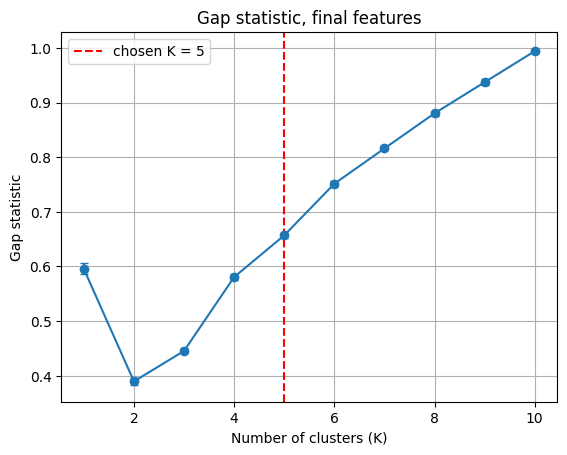

Gap one-standard-error selected K (range 1-10): 1
Highest gap among K >= 2: 10
The gap statistic finds no evidence of discrete clusters (K = 1). K = 5 is kept for business granularity (5-8 segments) and for stability, NOT because of the gap statistic. Report the data as a continuum and use segments as soft guidelines.


In [ ]:
# REMAINING CELL 3 (replacement): Gap statistic for the final feature set, full range K = 1..10

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

GAP_B = 30
GAP_SAMPLE_SIZE = min(5000, len(X_model))
rng_gap = np.random.default_rng(42)
if len(X_model) > GAP_SAMPLE_SIZE:
    X_gap_final = X_model[rng_gap.choice(len(X_model), size=GAP_SAMPLE_SIZE, replace=False)]
else:
    X_gap_final = X_model.copy()

# PCA-aligned uniform reference (Tibshirani et al., method b)
pca_gap = PCA().fit(X_gap_final)
Z_gap = pca_gap.transform(X_gap_final)
lower_gap, upper_gap = Z_gap.min(axis=0), Z_gap.max(axis=0)

gap_final_rows = []
for k_gap in range(1, 11):          # FULL range: K = 1 must be allowed, otherwise the result is forced
    observed = KMeans(n_clusters=k_gap, n_init=10, random_state=42).fit(X_gap_final)
    log_w_observed = np.log(max(observed.inertia_, 1e-12))

    null_log_w = []
    for b in range(GAP_B):
        rng = np.random.default_rng(10000 + 100 * k_gap + b)
        reference = pca_gap.inverse_transform(rng.uniform(lower_gap, upper_gap, size=Z_gap.shape))
        ref_model = KMeans(n_clusters=k_gap, n_init=5, random_state=20000 + 100 * k_gap + b).fit(reference)
        null_log_w.append(np.log(max(ref_model.inertia_, 1e-12)))

    null_log_w = np.asarray(null_log_w)
    gap_final_rows.append({
        "K": k_gap,
        "Gap": float(null_log_w.mean() - log_w_observed),
        "Gap_SE": float(null_log_w.std(ddof=1) * np.sqrt(1 + 1 / GAP_B)),
        "Observed_Inertia": float(observed.inertia_)
    })

gap_final_table = pd.DataFrame(gap_final_rows).set_index("K")
print("GAP STATISTIC FOR FINAL FEATURE SET:", FINAL_SCENARIO)
display(gap_final_table.round(4))

plt.errorbar(gap_final_table.index, gap_final_table["Gap"], yerr=gap_final_table["Gap_SE"],
             marker="o", capsize=3)
plt.axvline(FINAL_K, color="red", linestyle="--", label=f"chosen K = {FINAL_K}")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Gap statistic")
plt.title("Gap statistic, final features")
plt.legend()
plt.grid(True)
plt.show()

# one-standard-error rule over the FULL range
gap_selected_final = None
for k_gap in range(1, 10):
    if gap_final_table.loc[k_gap, "Gap"] >= (
        gap_final_table.loc[k_gap + 1, "Gap"] - gap_final_table.loc[k_gap + 1, "Gap_SE"]
    ):
        gap_selected_final = k_gap
        break
best_k_ge2 = int(gap_final_table.loc[2:, "Gap"].idxmax())

print("Gap one-standard-error selected K (range 1-10):", gap_selected_final)
print("Highest gap among K >= 2:", best_k_ge2)
if gap_selected_final == 1:
    print("The gap statistic finds no evidence of discrete clusters (K = 1). "
          f"K = {FINAL_K} is kept for business granularity (5-8 segments) and for stability, "
          "NOT because of the gap statistic. Report the data as a continuum and use segments as soft guidelines.")
elif gap_selected_final != FINAL_K:
    print("Gap statistic and the chosen K differ; justify K by profile usefulness and stability.")

In [ ]:
# REMAINING CELL 4: Compare clustering algorithms on the SAME final feature set
# A fixed sample is used for computationally heavier algorithms so every method
# sees identical observations and features.

import numpy as np
import pandas as pd
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score

ALGO_SAMPLE_SIZE = min(3000, len(X_model))
rng_algo = np.random.default_rng(42)
algo_indices = rng_algo.choice(len(X_model), size=ALGO_SAMPLE_SIZE, replace=False)
X_algo = X_model[algo_indices]
K_ALGO = FINAL_K
algo_rows = []


def record_algorithm(name, labels, X_eval, noise_label=None, params=None):
    labels = np.asarray(labels)
    if noise_label is None:
        valid_mask = np.ones(len(labels), dtype=bool)
        noise_fraction = 0.0
    else:
        valid_mask = labels != noise_label
        noise_fraction = float((~valid_mask).mean())

    valid_labels = labels[valid_mask]
    valid_X = X_eval[valid_mask]
    n_clusters = len(np.unique(valid_labels)) if len(valid_labels) else 0
    sil = np.nan
    db = np.nan
    if n_clusters >= 2 and len(valid_labels) > n_clusters:
        try:
            sil = float(silhouette_score(
                valid_X,
                valid_labels,
                sample_size=min(2000, len(valid_labels)),
                random_state=42
            ))
            db = float(davies_bouldin_score(valid_X, valid_labels))
        except Exception as exc:
            print(f"Metric warning for {name}: {exc}")

    algo_rows.append({
        "Algorithm": name,
        "Clusters_Excluding_Noise": n_clusters,
        "Noise_Fraction": noise_fraction,
        "Silhouette_NonNoise": sil,
        "Davies_Bouldin_NonNoise": db,
        "Parameters": str(params or {})
    })

# K-means++
km_algo = KMeans(n_clusters=K_ALGO, init="k-means++", n_init=20, random_state=42)
record_algorithm("KMeans++", km_algo.fit_predict(X_algo), X_algo, params={"k": K_ALGO})

# Hierarchical Ward
ward_algo = AgglomerativeClustering(n_clusters=K_ALGO, linkage="ward")
record_algorithm("Hierarchical_Ward", ward_algo.fit_predict(X_algo), X_algo, params={"k": K_ALGO})

# Fuzzy C-means (hard labels are used only for comparable internal metrics)
try:
    import skfuzzy as fuzz
    _, membership, *_ = fuzz.cluster.cmeans(
        X_algo.T, c=K_ALGO, m=2, error=0.005, maxiter=500, seed=42
    )
    fuzzy_labels = membership.argmax(axis=0)
    record_algorithm("Fuzzy_CMeans", fuzzy_labels, X_algo, params={"c": K_ALGO, "m": 2})
except Exception as exc:
    print("Fuzzy C-means skipped:", exc)

# DBSCAN: test a small eps grid based on 10-nearest-neighbour distances.
try:
    nn = NearestNeighbors(n_neighbors=min(11, len(X_algo))).fit(X_algo)
    distances, _ = nn.kneighbors(X_algo)
    kdist = distances[:, -1]
    eps_candidates = np.unique(np.quantile(kdist, [0.90, 0.95, 0.98, 0.99]))
    dbscan_candidates = []
    for eps in eps_candidates:
        labels = DBSCAN(eps=float(eps), min_samples=10).fit_predict(X_algo)
        temp_rows = []
        before = len(algo_rows)
        record_algorithm("DBSCAN_candidate", labels, X_algo, noise_label=-1, params={"eps": float(eps), "min_samples": 10})
        candidate_row = algo_rows.pop()
        if candidate_row["Clusters_Excluding_Noise"] >= 2 and candidate_row["Noise_Fraction"] < 0.80:
            dbscan_candidates.append(candidate_row)
    if dbscan_candidates:
        best_dbscan = max(
            dbscan_candidates,
            key=lambda r: (-1 if pd.isna(r["Silhouette_NonNoise"]) else r["Silhouette_NonNoise"])
        )
        best_dbscan["Algorithm"] = "DBSCAN_best_grid"
        algo_rows.append(best_dbscan)
    else:
        print("DBSCAN: no tested eps produced at least two non-noise clusters with <80% noise.")
except Exception as exc:
    print("DBSCAN skipped:", exc)

# HDBSCAN, when available in this scikit-learn installation
try:
    from sklearn.cluster import HDBSCAN
    hdb = HDBSCAN(min_cluster_size=30, min_samples=10)
    hdb_labels = hdb.fit_predict(X_algo)
    record_algorithm(
        "HDBSCAN",
        hdb_labels,
        X_algo,
        noise_label=-1,
        params={"min_cluster_size": 30, "min_samples": 10}
    )
except Exception as exc:
    print("HDBSCAN unavailable or failed; install/upgrade scikit-learn if required:", exc)

algorithm_comparison_final = pd.DataFrame(algo_rows)
print("ALGORITHM COMPARISON — SAME FEATURE SET AND SAME SAMPLE")
display(algorithm_comparison_final.round(4))
print("Sample rows used by every algorithm:", len(X_algo))
print("Feature scenario:", FINAL_SCENARIO)


ALGORITHM COMPARISON — SAME FEATURE SET AND SAME SAMPLE


,Algorithm,Clusters_Excluding_Noise,Noise_Fraction,Silhouette_NonNoise,Davies_Bouldin_NonNoise,Parameters
0,KMeans++,5,0.0000,0.3207,1.0929,{'k': 5}
1,Hierarchical_Ward,5,0.0000,0.3116,1.2765,{'k': 5}
2,Fuzzy_CMeans,5,0.0000,0.3170,1.1070,"{'c': 5, 'm': 2}"
3,DBSCAN_best_grid,2,0.0000,0.7159,0.3422,"{'eps': 1.4142135623730951, 'min_samples': 10}"
4,HDBSCAN,56,0.0457,0.7670,0.7375,"{'min_cluster_size': 30, 'min_samples': 10}"


Sample rows used by every algorithm: 3000
Feature scenario: B_Without_Rainfall


In [ ]:
# REMAINING CELL 5: Seasonal stability using matched Crop-State units over adjacent years
# This is a complementary stability diagnostic. It compares the same crop-state-season
# units across consecutive years using the fixed final model's cluster assignments.
# It does NOT treat records as individual farmers.

import pandas as pd
import numpy as np
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

seasonal_data_final = final_model_data.copy()
required_season_cols = ["Crop", "State", "Season", "Crop_Year", "Cluster"]
missing_season_cols = [c for c in required_season_cols if c not in seasonal_data_final.columns]
if missing_season_cols:
    raise ValueError(f"Missing columns for matched seasonal stability: {missing_season_cols}")

season_pair_rows = []
for season_name in ["Kharif", "Rabi", "Summer"]:
    subset = seasonal_data_final[
        seasonal_data_final["Season"].astype(str).str.lower() == season_name.lower()
    ].copy()
    observed_years = sorted(subset["Crop_Year"].dropna().astype(int).unique())

    for year_a in observed_years:
        year_b = year_a + 1
        if year_b not in observed_years:
            continue

        left = subset.loc[subset["Crop_Year"] == year_a, ["Crop", "State", "Cluster"]].rename(
            columns={"Cluster": "Cluster_Previous"}
        )
        right = subset.loc[subset["Crop_Year"] == year_b, ["Crop", "State", "Cluster"]].rename(
            columns={"Cluster": "Cluster_Current"}
        )

        matched = left.merge(right, on=["Crop", "State"], how="inner", validate="one_to_one")
        if len(matched) < 10:
            continue

        season_pair_rows.append({
            "Season": season_name,
            "Year_Pair": f"{year_a}-{year_b}",
            "Matched_Crop_State_Units": len(matched),
            "ARI": adjusted_rand_score(matched["Cluster_Previous"], matched["Cluster_Current"]),
            "NMI": normalized_mutual_info_score(matched["Cluster_Previous"], matched["Cluster_Current"])
        })

seasonal_transition_results = pd.DataFrame(season_pair_rows)
if seasonal_transition_results.empty:
    print("No adjacent-year seasonal matches met the minimum of 10 common Crop-State units.")
    seasonal_stability_summary = pd.DataFrame()
else:
    print("ADJACENT-YEAR SEASONAL STABILITY")
    display(seasonal_transition_results.round(4))

    seasonal_stability_summary = (
        seasonal_transition_results.groupby("Season")
        .agg(
            Year_Pairs=("Year_Pair", "count"),
            Mean_ARI=("ARI", "mean"),
            Mean_NMI=("NMI", "mean"),
            Minimum_ARI=("ARI", "min"),
            Mean_Matched_Units=("Matched_Crop_State_Units", "mean")
        )
        .reset_index()
    )
    print("SEASONAL SUMMARY")
    display(seasonal_stability_summary.round(4))
    print("Target reference from the plan: ARI/NMI >= 0.6. Report seasons separately; do not average away a weak season.")

# Year-by-year cluster shares for each season, useful for the report/dashboard.
season_cluster_shares = (
    seasonal_data_final[seasonal_data_final["Season"].isin(["Kharif", "Rabi", "Summer"])]
    .groupby(["Season", "Crop_Year", "Cluster"])
    .size()
    .rename("Rows")
    .reset_index()
)
season_cluster_shares["Share"] = season_cluster_shares["Rows"] / season_cluster_shares.groupby(
    ["Season", "Crop_Year"]
)["Rows"].transform("sum")

display(season_cluster_shares.head(20).round(4))


ADJACENT-YEAR SEASONAL STABILITY


,Season,Year_Pair,Matched_Crop_State_Units,ARI,NMI
0,Kharif,1997-1998,149,1.0,1.0
1,Kharif,1998-1999,226,1.0,1.0
2,Kharif,1999-2000,278,1.0,1.0
3,Kharif,2000-2001,325,1.0,1.0
4,Kharif,2001-2002,328,1.0,1.0
...,...,...,...,...,...
61,Summer,2014-2015,63,1.0,1.0
62,Summer,2015-2016,68,1.0,1.0
63,Summer,2016-2017,74,1.0,1.0
64,Summer,2017-2018,76,1.0,1.0


SEASONAL SUMMARY


,Season,Year_Pairs,Mean_ARI,Mean_NMI,Minimum_ARI,Mean_Matched_Units
0,Kharif,22,1.0,1.0,1.0,343.3182
1,Rabi,22,1.0,1.0,1.0,239.9545
2,Summer,22,1.0,1.0,1.0,46.3182


Target reference from the plan: ARI/NMI >= 0.6. Report seasons separately; do not average away a weak season.


,Season,Crop_Year,Cluster,Rows,Share
0,Kharif,1997,0,178,1.0
1,Kharif,1998,0,286,1.0
2,Kharif,1999,0,293,1.0
3,Kharif,2000,0,350,1.0
4,Kharif,2001,0,338,1.0
5,Kharif,2002,0,351,1.0
6,Kharif,2003,0,342,1.0
7,Kharif,2004,0,341,1.0
8,Kharif,2005,0,364,1.0
9,Kharif,2006,0,343,1.0


In [ ]:
# REMAINING CELL 6: Final segment profiles and recommendation engine
# Yield is used only for post-hoc profile/validation, never in clustering.

import os
import json
import numpy as np
import pandas as pd
import joblib

recommendation_data = final_model_data.copy()
if "Yield" not in recommendation_data.columns:
    recommendation_data["Yield"] = recommendation_data["Production"] / recommendation_data["Area"]

profile_metrics = [
    "Area", "Production", "Annual_Rainfall",
    "Fertilizer_per_ha", "Pesticide_per_ha",
    "Fertilizer_to_Pesticide_ratio", "Yield"
]
profile_metrics = [c for c in profile_metrics if c in recommendation_data.columns]

cluster_profile_final = recommendation_data.groupby("Cluster")[profile_metrics].median().round(4)
cluster_sizes_final = recommendation_data["Cluster"].value_counts().sort_index()

# Quantile thresholds are descriptive comparison points, not agronomic safety limits.
thresholds = {}
for metric in ["Annual_Rainfall", "Fertilizer_per_ha", "Pesticide_per_ha"]:
    thresholds[metric] = recommendation_data[metric].quantile([1/3, 2/3]).to_dict()


def relative_level(value, low_cut, high_cut):
    if value <= low_cut:
        return "Low"
    if value >= high_cut:
        return "High"
    return "Typical"

profile_rows = []
recommendation_rows = []

for cluster_id, row in cluster_profile_final.iterrows():
    group = recommendation_data[recommendation_data["Cluster"] == cluster_id]

    rain_level = relative_level(
        row.get("Annual_Rainfall", np.nan),
        thresholds["Annual_Rainfall"][1/3],
        thresholds["Annual_Rainfall"][2/3]
    )
    fert_level = relative_level(
        row.get("Fertilizer_per_ha", np.nan),
        thresholds["Fertilizer_per_ha"][1/3],
        thresholds["Fertilizer_per_ha"][2/3]
    )
    pest_level = relative_level(
        row.get("Pesticide_per_ha", np.nan),
        thresholds["Pesticide_per_ha"][1/3],
        thresholds["Pesticide_per_ha"][2/3]
    )

    segment_name = f"{rain_level} Rainfall | {fert_level} Fertilizer | {pest_level} Pesticide"

    top_crops = group["Crop"].value_counts().head(3).index.tolist()
    top_states = group["State"].value_counts().head(3).index.tolist()
    top_seasons = group["Season"].value_counts().head(3).index.tolist()

    profile_rows.append({
        "Cluster": int(cluster_id),
        "Segment_Name": segment_name,
        "Rows": int(len(group)),
        "Share_Percent": 100 * len(group) / len(recommendation_data),
        "Top_Crops": ", ".join(top_crops),
        "Top_States": ", ".join(top_states),
        "Top_Seasons": ", ".join(top_seasons),
        **row.to_dict()
    })

    # Irrigation recommendation based on rainfall context only; actual soil moisture is unavailable.
    if rain_level == "Low":
        irrigation = "Review rainfall and crop growth stage; monitor field soil moisture and schedule irrigation only when needed. Prioritize water-efficient delivery methods where locally suitable."
    elif rain_level == "High":
        irrigation = "Check field drainage and waterlogging risk; avoid unnecessary irrigation when rainfall and soil moisture are adequate."
    else:
        irrigation = "Use rainfall together with field soil-moisture checks and crop growth stage to adjust irrigation scheduling."

    # Fertilizer intensity is a screening indicator, not proof of over- or under-application.
    if fert_level == "High":
        fertilizer = "Review nutrient application against soil-test results and crop requirements; consider split applications at suitable growth stages and avoid blanket application."
    elif fert_level == "Low":
        fertilizer = "Check soil-test results and crop nutrient symptoms before adjusting inputs; use a balanced nutrient plan based on local agronomic guidance."
    else:
        fertilizer = "Maintain field-level nutrient records and follow crop- and soil-specific fertilizer recommendations; reassess after soil testing."

    # Pesticide intensity is not a pest diagnosis. Keep advice within integrated pest management.
    if pest_level == "High":
        pest = "Increase pest scouting and use integrated pest management: cultural, mechanical and biological controls first; apply only locally registered products when monitoring and economic thresholds justify it, following the label and local expert advice."
    else:
        pest = "Continue regular pest scouting, conserve beneficial insects and avoid calendar-based or prophylactic spraying when pest thresholds are not reached."

    recommendation_rows.extend([
        {"Cluster": int(cluster_id), "Segment_Name": segment_name, "Area": "Irrigation", "Recommendation": irrigation},
        {"Cluster": int(cluster_id), "Segment_Name": segment_name, "Area": "Fertilization", "Recommendation": fertilizer},
        {"Cluster": int(cluster_id), "Segment_Name": segment_name, "Area": "Pest Management", "Recommendation": pest}
    ])

segment_profiles_final = pd.DataFrame(profile_rows).sort_values("Cluster")
recommendations_final = pd.DataFrame(recommendation_rows).sort_values(["Cluster", "Area"])

print("FINAL AGRICULTURAL SEGMENT PROFILES")
display(segment_profiles_final.round(3))
print("RECOMMENDATIONS: at least three actions per segment")
display(recommendations_final)

# Save core artifacts used by MLflow and the Streamlit dashboard.
ARTIFACT_DIR = "agrisense_final_artifacts"
os.makedirs(ARTIFACT_DIR, exist_ok=True)

joblib.dump(final_model, os.path.join(ARTIFACT_DIR, "final_kmeans_k5.joblib"))
joblib.dump(final_scaler, os.path.join(ARTIFACT_DIR, "final_robust_scaler.joblib"))

with open(os.path.join(ARTIFACT_DIR, "feature_columns.json"), "w", encoding="utf-8") as f:
    json.dump({
        "scenario": FINAL_SCENARIO,
        "features": final_feature_columns,
        "excluded_from_clustering": ["Area_log", "Production_log", "Rainfall_state_z", "Yield", "LogYield", "Yield_rel"],
        "fit_years": "1997-2019",
        "k": FINAL_K,
        "note": "Rainfall is retained for profile/recommendation context but excluded from clustering in B_Without_Rainfall."
    }, f, indent=2)

final_model_data.to_csv(os.path.join(ARTIFACT_DIR, "training_cluster_assignments.csv"), index=False)
final_dashboard_data.to_csv(os.path.join(ARTIFACT_DIR, "dashboard_data.csv"), index=False)
segment_profiles_final.to_csv(os.path.join(ARTIFACT_DIR, "segment_profiles.csv"), index=False)
recommendations_final.to_csv(os.path.join(ARTIFACT_DIR, "recommendations.csv"), index=False)
final_model_comparison.to_csv(os.path.join(ARTIFACT_DIR, "kmeans_comparison.csv"), index=False)

with open(os.path.join(ARTIFACT_DIR, "final_model_metrics.json"), "w", encoding="utf-8") as f:
    json.dump(final_metrics, f, indent=2)

print("Core model and dashboard artifacts saved to:", ARTIFACT_DIR)


FINAL AGRICULTURAL SEGMENT PROFILES


,Cluster,Segment_Name,Rows,Share_Percent,Top_Crops,Top_States,Top_Seasons,Area,Production,Annual_Rainfall,Fertilizer_per_ha,Pesticide_per_ha,Fertilizer_to_Pesticide_ratio,Yield
0,0,Typical Rainfall | Low Fertilizer | Typical Pe...,7235,36.981,"Rice, Maize, Groundnut","Karnataka, Andhra Pradesh, West Bengal","Kharif, Rabi, Whole Year",12996.0,16805.0,1248.1,102.13,0.25,393.074,0.954
1,1,Typical Rainfall | Typical Fertilizer | Low Pe...,844,4.314,"Rice, Maize, Urad","Karnataka, West Bengal, Andhra Pradesh","Kharif, Rabi, Whole Year",9201.5,14330.0,1199.8,143.04,0.09,1589.333,1.023
2,2,Typical Rainfall | High Fertilizer | Low Pesti...,2544,13.003,"Rice, Maize, Urad","Karnataka, West Bengal, Andhra Pradesh","Kharif, Rabi, Whole Year",8835.5,13431.5,1297.0,155.82,0.17,833.750,1.000
3,3,Typical Rainfall | High Fertilizer | High Pest...,3947,20.175,"Rice, Maize, Sesamum","Andhra Pradesh, Nagaland, Karnataka",Kharif,6678.0,8120.0,1217.7,157.44,0.33,464.216,1.000
4,4,Typical Rainfall | High Fertilizer | High Pest...,4994,25.526,"Rice, Wheat, Potato","Karnataka, Andhra Pradesh, Tamil Nadu","Rabi, Whole Year, Summer",7008.0,13857.0,1247.6,157.44,0.33,464.216,1.345


RECOMMENDATIONS: at least three actions per segment


,Cluster,Segment_Name,Area,Recommendation
1,0,Typical Rainfall | Low Fertilizer | Typical Pe...,Fertilization,Check soil-test results and crop nutrient symp...
0,0,Typical Rainfall | Low Fertilizer | Typical Pe...,Irrigation,Use rainfall together with field soil-moisture...
2,0,Typical Rainfall | Low Fertilizer | Typical Pe...,Pest Management,"Continue regular pest scouting, conserve benef..."
4,1,Typical Rainfall | Typical Fertilizer | Low Pe...,Fertilization,Maintain field-level nutrient records and foll...
3,1,Typical Rainfall | Typical Fertilizer | Low Pe...,Irrigation,Use rainfall together with field soil-moisture...
5,1,Typical Rainfall | Typical Fertilizer | Low Pe...,Pest Management,"Continue regular pest scouting, conserve benef..."
7,2,Typical Rainfall | High Fertilizer | Low Pesti...,Fertilization,Review nutrient application against soil-test ...
6,2,Typical Rainfall | High Fertilizer | Low Pesti...,Irrigation,Use rainfall together with field soil-moisture...
8,2,Typical Rainfall | High Fertilizer | Low Pesti...,Pest Management,"Continue regular pest scouting, conserve benef..."
10,3,Typical Rainfall | High Fertilizer | High Pest...,Fertilization,Review nutrient application against soil-test ...


Core model and dashboard artifacts saved to: agrisense_final_artifacts


In [ ]:
# REMAINING CELL 7: Simulated A/B testing framework
# This is an assumption-based scenario simulation, NOT a real field experiment,
# measured causal impact, or evidence of actual yield improvement.

import numpy as np
import pandas as pd
import os

ab_data = final_model_data.copy().reset_index(drop=True)
if "Yield" not in ab_data.columns:
    ab_data["Yield"] = ab_data["Production"] / ab_data["Area"]

# Explicit hypothetical assumptions. Change these only with documented rationale.
GENERIC_INPUT_REDUCTION = 0.05       # 5% generic reduction in both inputs
TARGETED_INPUT_REDUCTION = 0.20      # 20% reduction only for high-intensity cluster/metric combinations
ASSUMED_YIELD_CHANGE = 0.00           # Hold yield constant; do not invent yield uplift

fert_q75 = ab_data["Fertilizer_per_ha"].quantile(0.75)
pest_q75 = ab_data["Pesticide_per_ha"].quantile(0.75)
profile_for_ab = ab_data.groupby("Cluster").agg(
    Median_Fertilizer_per_ha=("Fertilizer_per_ha", "median"),
    Median_Pesticide_per_ha=("Pesticide_per_ha", "median")
)
high_fertilizer_clusters = set(profile_for_ab.index[
    profile_for_ab["Median_Fertilizer_per_ha"] >= fert_q75
])
high_pesticide_clusters = set(profile_for_ab.index[
    profile_for_ab["Median_Pesticide_per_ha"] >= pest_q75
])

# Randomize 50/50 within each cluster so the two simulated groups have similar segment composition.
rng_ab = np.random.default_rng(42)
group_assignment = pd.Series(index=ab_data.index, dtype="object")
for cluster_id, idx in ab_data.groupby("Cluster").groups.items():
    idx = np.asarray(list(idx))
    shuffled = rng_ab.permutation(idx)
    treatment_idx = shuffled[::2]
    control_idx = shuffled[1::2]
    group_assignment.loc[control_idx] = "Generic_Control"
    group_assignment.loc[treatment_idx] = "Segment_Treatment"

ab_data["Experiment_Group"] = group_assignment

# Generic control: same modest assumed reduction for every segment.
control_mask = ab_data["Experiment_Group"] == "Generic_Control"
treatment_mask = ab_data["Experiment_Group"] == "Segment_Treatment"

ab_data["Sim_Fertilizer_per_ha"] = ab_data["Fertilizer_per_ha"].astype(float)
ab_data["Sim_Pesticide_per_ha"] = ab_data["Pesticide_per_ha"].astype(float)
ab_data["Sim_Yield"] = ab_data["Yield"].astype(float) * (1 + ASSUMED_YIELD_CHANGE)

ab_data.loc[control_mask, "Sim_Fertilizer_per_ha"] *= (1 - GENERIC_INPUT_REDUCTION)
ab_data.loc[control_mask, "Sim_Pesticide_per_ha"] *= (1 - GENERIC_INPUT_REDUCTION)

# Targeted treatment reduces only the input whose cluster median is in the high-intensity group.
for cluster_id in ab_data["Cluster"].unique():
    cluster_mask = treatment_mask & (ab_data["Cluster"] == cluster_id)
    if cluster_id in high_fertilizer_clusters:
        ab_data.loc[cluster_mask, "Sim_Fertilizer_per_ha"] *= (1 - TARGETED_INPUT_REDUCTION)
    if cluster_id in high_pesticide_clusters:
        ab_data.loc[cluster_mask, "Sim_Pesticide_per_ha"] *= (1 - TARGETED_INPUT_REDUCTION)

# Efficiency KPIs are input per tonne of observed yield; yield is held constant by assumption.
valid_yield = ab_data["Sim_Yield"].where(ab_data["Sim_Yield"] > 0)
ab_data["Sim_Fertilizer_per_tonne"] = ab_data["Sim_Fertilizer_per_ha"] / valid_yield
ab_data["Sim_Pesticide_per_tonne"] = ab_data["Sim_Pesticide_per_ha"] / valid_yield
ab_data["Sim_Combined_Inputs_per_tonne"] = (
    ab_data["Sim_Fertilizer_per_tonne"] + ab_data["Sim_Pesticide_per_tonne"]
)

ab_summary = ab_data.groupby("Experiment_Group").agg(
    Rows=("Cluster", "size"),
    Mean_Yield=("Sim_Yield", "mean"),
    Mean_Fertilizer_per_ha=("Sim_Fertilizer_per_ha", "mean"),
    Mean_Pesticide_per_ha=("Sim_Pesticide_per_ha", "mean"),
    Fertilizer_per_tonne=("Sim_Fertilizer_per_tonne", "mean"),
    Pesticide_per_tonne=("Sim_Pesticide_per_tonne", "mean"),
    Combined_Inputs_per_tonne=("Sim_Combined_Inputs_per_tonne", "mean")
).reset_index()

print("SIMULATED A/B RESULTS — ASSUMPTION-BASED, NOT OBSERVED EFFECTS")
display(ab_summary.round(4))

control_eff = ab_summary.loc[
    ab_summary["Experiment_Group"] == "Generic_Control",
    "Combined_Inputs_per_tonne"
].iloc[0]
treatment_eff = ab_summary.loc[
    ab_summary["Experiment_Group"] == "Segment_Treatment",
    "Combined_Inputs_per_tonne"
].iloc[0]
resource_efficiency_change = (control_eff - treatment_eff) / control_eff * 100 if control_eff else np.nan
print(f"Simulated change in combined inputs per tonne vs generic control: {resource_efficiency_change:.2f}%")
print("Reminder: this value is generated from stated assumptions. It is not a measured 15-25% improvement or a causal estimate.")

os.makedirs(ARTIFACT_DIR, exist_ok=True)
ab_data.to_csv(os.path.join(ARTIFACT_DIR, "ab_test_simulated_rows.csv"), index=False)
ab_summary.to_csv(os.path.join(ARTIFACT_DIR, "ab_test_simulated_summary.csv"), index=False)

ab_design_text = f"""# AgriSense A/B Testing Design — Simulation Only

## Objective
Compare a generic advisory scenario with a segment-targeted advisory scenario using the crop-season-state-year proxy records.

## Groups
- Generic control: hypothetical 5% reduction in fertilizer and pesticide intensity for every record.
- Segment treatment: hypothetical 20% reduction only for the input whose cluster median is above the dataset's 75th percentile; otherwise no reduction for that input.

## Randomization
Records are assigned 50/50 within each cluster using a fixed random seed. This is a simulated assignment, not a real farmer trial.

## Outcomes
- Mean yield (held unchanged by assumption)
- Fertilizer per tonne of yield
- Pesticide per tonne of yield
- Combined inputs per tonne of yield

## Critical limitations
All treatment effects are assumptions. The dataset contains aggregated crop-season-state-year observations, not individual farmers or measured intervention outcomes. This simulation cannot establish causal yield uplift or actual resource savings. A real evaluation would require consented farmer/field identifiers, treatment assignment, baseline and follow-up measurements, and agronomic oversight.

## Scenario parameters
- Generic reduction: {GENERIC_INPUT_REDUCTION:.0%}
- Targeted reduction: {TARGETED_INPUT_REDUCTION:.0%}
- Assumed yield change: {ASSUMED_YIELD_CHANGE:.0%}
"""
with open(os.path.join(ARTIFACT_DIR, "AB_TEST_DESIGN.md"), "w", encoding="utf-8") as f:
    f.write(ab_design_text)
print("A/B design and simulated outputs saved.")


SIMULATED A/B RESULTS — ASSUMPTION-BASED, NOT OBSERVED EFFECTS


,Experiment_Group,Rows,Mean_Yield,Mean_Fertilizer_per_ha,Mean_Pesticide_per_ha,Fertilizer_per_tonne,Pesticide_per_tonne,Combined_Inputs_per_tonne
0,Generic_Control,9781,82.6475,130.2183,0.2602,183.4539,0.3728,183.8267
1,Segment_Treatment,9783,85.9574,137.0229,0.2436,187.8547,0.3441,188.1988


Simulated change in combined inputs per tonne vs generic control: -2.38%
Reminder: this value is generated from stated assumptions. It is not a measured 15-25% improvement or a causal estimate.
A/B design and simulated outputs saved.


In [ ]:
# REMAINING CELL 8: MiniBatchKMeans and incremental-update benchmark
# The real benchmark uses the available aggregate records (not individual farmer records).
# A separate 100,000-row resampling run is a synthetic computational load test only.

import time
import math
import numpy as np
import pandas as pd
from sklearn.cluster import MiniBatchKMeans
import os

BATCH_SIZE = 1024
TARGET_SYNTHETIC_ROWS = 100_000
rng_scale = np.random.default_rng(42)

# Batch fit on the actual in-period feature matrix.
t0 = time.perf_counter()
mb_batch = MiniBatchKMeans(
    n_clusters=FINAL_K,
    random_state=42,
    batch_size=BATCH_SIZE,
    n_init=10,
    max_iter=100
)
mb_batch.fit(X_model)
batch_fit_seconds = time.perf_counter() - t0

# Incremental partial_fit on the actual in-period feature matrix.
t0 = time.perf_counter()
mb_incremental = MiniBatchKMeans(
    n_clusters=FINAL_K,
    random_state=42,
    batch_size=BATCH_SIZE,
    n_init=10,
    reassignment_ratio=0.01
)
permutation = rng_scale.permutation(len(X_model))
X_shuffled = X_model[permutation]
for start in range(0, len(X_shuffled), BATCH_SIZE):
    batch = X_shuffled[start:start + BATCH_SIZE]
    if len(batch) >= FINAL_K:
        mb_incremental.partial_fit(batch)
incremental_seconds = time.perf_counter() - t0

# Synthetic scale test: resample existing feature rows with replacement to 100K.
synthetic_indices = rng_scale.integers(0, len(X_model), size=TARGET_SYNTHETIC_ROWS)
X_synthetic = X_model[synthetic_indices]

t0 = time.perf_counter()
mb_synthetic = MiniBatchKMeans(
    n_clusters=FINAL_K,
    random_state=42,
    batch_size=2048,
    n_init=10,
    reassignment_ratio=0.01
)
for start in range(0, len(X_synthetic), 2048):
    batch = X_synthetic[start:start + 2048]
    if len(batch) >= FINAL_K:
        mb_synthetic.partial_fit(batch)
synthetic_seconds = time.perf_counter() - t0

scalability_results = pd.DataFrame([
    {"Benchmark": "MiniBatchKMeans.fit on actual 1997-2019 aggregate rows", "Rows": len(X_model), "Seconds": batch_fit_seconds, "Data_Type": "Actual aggregated dataset"},
    {"Benchmark": "MiniBatchKMeans.partial_fit on actual 1997-2019 aggregate rows", "Rows": len(X_model), "Seconds": incremental_seconds, "Data_Type": "Actual aggregated dataset"},
    {"Benchmark": "MiniBatchKMeans.partial_fit on 100K resampled rows", "Rows": len(X_synthetic), "Seconds": synthetic_seconds, "Data_Type": "Synthetic computational load test"}
])

print("SCALABILITY BENCHMARK")
display(scalability_results.round(3))
print("Actual batch fit under five minutes:", batch_fit_seconds < 300)
print("Synthetic 100K load test under five minutes:", synthetic_seconds < 300)
print("Important: the 100K benchmark is resampled aggregate data, not 100K real farmers.")

os.makedirs(ARTIFACT_DIR, exist_ok=True)
scalability_results.to_csv(os.path.join(ARTIFACT_DIR, "scalability_benchmark.csv"), index=False)
joblib.dump(mb_incremental, os.path.join(ARTIFACT_DIR, "minibatch_incremental_model.joblib"))


SCALABILITY BENCHMARK


,Benchmark,Rows,Seconds,Data_Type
0,MiniBatchKMeans.fit on actual 1997-2019 aggreg...,19564,0.035,Actual aggregated dataset
1,MiniBatchKMeans.partial_fit on actual 1997-201...,19564,0.018,Actual aggregated dataset
2,MiniBatchKMeans.partial_fit on 100K resampled ...,100000,0.038,Synthetic computational load test


Actual batch fit under five minutes: True
Synthetic 100K load test under five minutes: True
Important: the 100K benchmark is resampled aggregate data, not 100K real farmers.


['agrisense_final_artifacts/minibatch_incremental_model.joblib']

In [ ]:
# REMAINING CELL 9: Generate the Streamlit + Plotly dashboard app.py
# Run this cell after the profile/recommendation cell has saved dashboard_data.csv,
# segment_profiles.csv and recommendations.csv.

from pathlib import Path

app_source = r'''import json
from pathlib import Path
import pandas as pd
import streamlit as st
import plotly.express as px

ARTIFACT_DIR = Path("agrisense_final_artifacts")
DATA_PATH = ARTIFACT_DIR / "dashboard_data.csv"
PROFILE_PATH = ARTIFACT_DIR / "segment_profiles.csv"
REC_PATH = ARTIFACT_DIR / "recommendations.csv"

st.set_page_config(page_title="AgriSense | Precision Agriculture", page_icon="🌾", layout="wide")
st.title("🌾 AgriSense — Precision Agriculture Segmentation")
st.caption("Segments are crop-season-state-year observation proxies, not individual farmer profiles. Recommendations are general screening guidance, not field-specific prescriptions.")

required_files = [DATA_PATH, PROFILE_PATH, REC_PATH]
missing = [str(p) for p in required_files if not p.exists()]
if missing:
    st.error("Missing model outputs. Run the final notebook cells first: " + ", ".join(missing))
    st.stop()

data = pd.read_csv(DATA_PATH)
profiles = pd.read_csv(PROFILE_PATH)
recommendations = pd.read_csv(REC_PATH)

if "Model_Status" in data.columns:
    n_out = int(data["Model_Status"].astype(str).str.contains("Out-of-period", case=False).sum())
    if n_out:
        st.warning(f"{n_out} records are from the low-coverage 2020 period. They are assigned using a model trained through 2019 and should be interpreted cautiously.")

st.sidebar.header("Filters")
state_options = sorted(data["State"].dropna().astype(str).unique())
crop_options = sorted(data["Crop"].dropna().astype(str).unique())
season_options = sorted(data["Season"].dropna().astype(str).unique())
cluster_options = sorted(data["Cluster"].dropna().astype(int).unique())

selected_states = st.sidebar.multiselect("State", state_options)
selected_crops = st.sidebar.multiselect("Crop", crop_options)
selected_seasons = st.sidebar.multiselect("Season", season_options)
selected_clusters = st.sidebar.multiselect("Segment", cluster_options)
year_min, year_max = int(data["Crop_Year"].min()), int(data["Crop_Year"].max())
selected_years = st.sidebar.slider("Crop year", year_min, year_max, (year_min, year_max))

filtered = data[data["Crop_Year"].between(*selected_years)].copy()
if selected_states:
    filtered = filtered[filtered["State"].astype(str).isin(selected_states)]
if selected_crops:
    filtered = filtered[filtered["Crop"].astype(str).isin(selected_crops)]
if selected_seasons:
    filtered = filtered[filtered["Season"].astype(str).isin(selected_seasons)]
if selected_clusters:
    filtered = filtered[filtered["Cluster"].astype(int).isin(selected_clusters)]

if filtered.empty:
    st.warning("No records match the selected filters.")
    st.stop()

c1, c2, c3, c4 = st.columns(4)
c1.metric("Observations", f"{len(filtered):,}")
c2.metric("Segments present", filtered["Cluster"].nunique())
c3.metric("States present", filtered["State"].nunique())
c4.metric("Median yield", f"{filtered['Yield'].median():.3f}" if "Yield" in filtered.columns else "N/A")

left, right = st.columns(2)
with left:
    counts = filtered["Cluster"].value_counts().sort_index().rename_axis("Cluster").reset_index(name="Rows")
    fig = px.bar(counts, x="Cluster", y="Rows", title="Observations by segment", text="Rows")
    st.plotly_chart(fig, use_container_width=True)
with right:
    if {"Fertilizer_per_ha", "Pesticide_per_ha"}.issubset(filtered.columns):
        fig = px.scatter(
            filtered,
            x="Fertilizer_per_ha",
            y="Pesticide_per_ha",
            color=filtered["Cluster"].astype(str),
            hover_data=["Crop", "State", "Season", "Crop_Year"],
            title="Resource intensity by segment",
            labels={"color": "Cluster"}
        )
        st.plotly_chart(fig, use_container_width=True)

st.subheader("Segment profiles")
visible_clusters = sorted(filtered["Cluster"].dropna().astype(int).unique())
profile_view = profiles[profiles["Cluster"].isin(visible_clusters)]
st.dataframe(profile_view, use_container_width=True, hide_index=True)

st.subheader("Recommendations")
rec_view = recommendations[recommendations["Cluster"].isin(visible_clusters)]
st.dataframe(rec_view, use_container_width=True, hide_index=True)

st.subheader("Filtered observations")
st.dataframe(filtered.head(500), use_container_width=True, hide_index=True)
csv_bytes = filtered.to_csv(index=False).encode("utf-8")
st.download_button("Download filtered segment report (CSV)", csv_bytes, file_name="agrisense_filtered_segments.csv", mime="text/csv")

st.caption("Interpret input intensity carefully: high fertilizer/pesticide use is not, by itself, proof of over-application or pest incidence. Validate recommendations with soil tests, field scouting and local agricultural experts.")
'''

Path("app.py").write_text(app_source, encoding="utf-8")
print("Created app.py")
print("Run after creating the artifact folder: streamlit run app.py")


Created app.py
Run after creating the artifact folder: streamlit run app.py


In [ ]:
# REMAINING CELL 10: Generate README, requirements, Dockerfile and final report outline

from pathlib import Path
import json

requirements_text = """numpy
pandas
scikit-learn
scikit-fuzzy
mlflow
joblib
streamlit
plotly
scipy
matplotlib
seaborn
"""

readme_text = f"""# AgriSense — Unsupervised Segmentation for Precision Agriculture

## Project scope
AgriSense segments crop-season-state-year aggregate observations into agronomic groups and maps the groups to general irrigation, fertilization and integrated pest-management guidance. The dataset does not contain individual farmer identifiers or field-level sensor measurements; therefore, segments are observation proxies, not verified individual-farmer segments.

## Provisional final model
- Algorithm: K-means++
- K: {FINAL_K}
- Feature scenario: {FINAL_SCENARIO}
- Training period: 1997–2019
- 2020: retained as a low-coverage out-of-period assignment; only 37 observations from one state were observed in the current cleaned data.
- Clustering features: {', '.join(final_feature_columns)}
- Excluded from clustering: Area_log, Production_log, Rainfall_state_z, Yield and yield-derived variables.
- Rainfall remains available for segment profiling and recommendation context.

## Validation
Run the final notebook cells to populate `agrisense_final_artifacts/`. Report the actual silhouette, Davies–Bouldin, gap-statistic, seasonal stability, algorithm comparison and scalability outputs from that run. Do not claim the PDF target of silhouette >= 0.4 or ARI/NMI >= 0.6 unless the final computed results meet it.

## Run the dashboard
1. Install dependencies: `pip install -r requirements.txt`
2. Run the final notebook cells to create `agrisense_final_artifacts/` and `app.py`.
3. Start the dashboard: `streamlit run app.py`

## Important limitations
- Input data are aggregate crop-season-state-year observations, not individual farmers.
- 2020 coverage is incomplete in the current cleaned data and is not used to fit the final model.
- Pest input intensity is not a pest diagnosis. Recommendations are screening guidance and require field scouting and local expert validation.
- The A/B test is a transparent assumption-based simulation, not evidence of measured or causal impacts.
- The synthetic 100K MiniBatch benchmark is a computational load test created by resampling existing aggregate observations, not a real 100K-farmer benchmark.

## Repository structure
- `Crop_Cluster_AgriSense_Remaining_Work_Cells.ipynb` — analysis and implementation
- `app.py` — Streamlit dashboard
- `agrisense_final_artifacts/` — generated model, scaler, profiles, assignments, recommendations and metrics
- `requirements.txt` — Python dependencies
- `Dockerfile` — container setup
- `AB_TEST_DESIGN.md` — simulation assumptions and limitations
- `FINAL_REPORT_OUTLINE.md` — report structure
"""

# Put dynamic values into README from the completed notebook run.
Path("README.md").write_text(readme_text, encoding="utf-8")
Path("requirements.txt").write_text(requirements_text, encoding="utf-8")

# Dashboard container
Path("Dockerfile").write_text("""FROM python:3.11-slim
WORKDIR /app
COPY requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt
COPY app.py .
COPY agrisense_final_artifacts ./agrisense_final_artifacts
EXPOSE 8501
CMD [\"streamlit\", \"run\", \"app.py\", \"--server.address=0.0.0.0\", \"--server.port=8501\"]
""", encoding="utf-8")

report_outline = """# AgriSense Final Project Report — Outline (10–18 pages)

1. Executive summary and project objective
2. Problem statement and business context
3. Dataset description and data reality check (aggregate observation unit; row-count reconciliation; 2020 low coverage)
4. Data cleaning and feature engineering (include yield leakage prevention)
5. Exploratory data analysis and data-quality findings
6. Clustering methodology and comparison (K-means++, Ward, fuzzy C-means, DBSCAN/HDBSCAN)
7. Cluster selection (elbow, silhouette, Davies–Bouldin, gap statistic; explain why K=5 is retained or changed)
8. Final cluster profiles and agricultural interpretation
9. Seasonal and temporal stability (Kharif/Rabi/Summer; year-holdout; drift limitations)
10. Recommendation engine (irrigation, fertilizer, integrated pest management)
11. Simulated A/B testing design (assumptions and explicit non-causal limitation)
12. Scalability benchmark and incremental-update approach
13. Dashboard and deployment architecture
14. Risks, limitations and future data enrichment
15. Conclusion and references/appendices

Only insert metrics actually produced by the executed final notebook. Do not present synthetic A/B outcomes or synthetic scalability rows as observed real-world results.
"""
Path("FINAL_REPORT_OUTLINE.md").write_text(report_outline, encoding="utf-8")

print("Created README.md, requirements.txt, Dockerfile and FINAL_REPORT_OUTLINE.md")


Created README.md, requirements.txt, Dockerfile and FINAL_REPORT_OUTLINE.md


In [ ]:
# REMAINING CELL 11: Log the complete final candidate to MLflow and print a readiness summary

import os
import json

# Attach final diagnostic tables to the artifact directory where available.
os.makedirs(ARTIFACT_DIR, exist_ok=True)

if "gap_final_table" in globals():
    gap_final_table.to_csv(os.path.join(ARTIFACT_DIR, "gap_statistic_final.csv"))
if "algorithm_comparison_final" in globals():
    algorithm_comparison_final.to_csv(os.path.join(ARTIFACT_DIR, "algorithm_comparison_final.csv"), index=False)
if "seasonal_transition_results" in globals():
    seasonal_transition_results.to_csv(os.path.join(ARTIFACT_DIR, "seasonal_transition_results.csv"), index=False)
if "seasonal_stability_summary" in globals() and not seasonal_stability_summary.empty:
    seasonal_stability_summary.to_csv(os.path.join(ARTIFACT_DIR, "seasonal_stability_summary.csv"), index=False)
if "scalability_results" in globals():
    scalability_results.to_csv(os.path.join(ARTIFACT_DIR, "scalability_benchmark.csv"), index=False)
if "ab_summary" in globals():
    ab_summary.to_csv(os.path.join(ARTIFACT_DIR, "ab_test_simulated_summary.csv"), index=False)

# Add final run to MLflow without deleting old experimental runs.
try:
    import mlflow
    mlflow.set_tracking_uri("sqlite:///mlflow.db")
    mlflow.set_experiment("AgriSense_Segmentation")

    with mlflow.start_run(run_name="FINAL_B_Without_Rainfall_K5_1997_2019"):
        mlflow.log_params({
            "algorithm": "KMeans++",
            "k": FINAL_K,
            "feature_scenario": FINAL_SCENARIO,
            "training_period": "1997-2019",
            "n_init": 50,
            "random_state": 42,
            "yield_leakage": False,
            "scale_features_excluded": "Area_log,Production_log",
            "rainfall_state_z_excluded": True
        })
        mlflow.log_metrics({
            "silhouette": float(final_silhouette),
            "davies_bouldin": float(final_davies_bouldin),
            "inertia": float(final_inertia)
        })
        for root, _, files in os.walk(ARTIFACT_DIR):
            for filename in files:
                path = os.path.join(root, filename)
                relative_dir = os.path.relpath(root, ARTIFACT_DIR)
                artifact_path = "final_artifacts" if relative_dir == "." else os.path.join("final_artifacts", relative_dir)
                mlflow.log_artifact(path, artifact_path=artifact_path)
    print("Final candidate logged to MLflow. Earlier runs were retained.")
except Exception as exc:
    print("MLflow logging was skipped or failed; local artifacts remain available:", exc)

print("\nAGRISENSE FINAL READINESS SUMMARY")
print("Feature candidate:", FINAL_SCENARIO)
print("K:", FINAL_K)
print("Silhouette:", round(final_silhouette, 4), "| target >= 0.4:", final_silhouette >= 0.4)
print("Davies-Bouldin:", round(final_davies_bouldin, 4))
print("Gap one-SE K:", gap_selected_final if "gap_selected_final" in globals() else "Not computed")
print("Seasonal matched-unit report:", "Computed" if "seasonal_transition_results" in globals() else "Not computed")
print("Recommendation rows:", len(recommendations_final), "(expected at least 3 per cluster)")
print("A/B output:", "Created (assumption-based simulation)" if "ab_summary" in globals() else "Not run")
print("Scalability benchmark:", "Created" if "scalability_results" in globals() else "Not run")
print("Dashboard source:", "app.py created" if os.path.exists("app.py") else "Run dashboard generator cell")
print("Artifact directory:", ARTIFACT_DIR)
print("Still manual: inspect agronomic recommendations, verify GitHub contents, deploy dashboard, create final 10-18 page report, record 4-8 minute demo video.")


Final candidate logged to MLflow. Earlier runs were retained.

AGRISENSE FINAL READINESS SUMMARY
Feature candidate: B_Without_Rainfall
K: 5
Silhouette: 0.3162 | target >= 0.4: False
Davies-Bouldin: 1.0961
Gap one-SE K: 1
Seasonal matched-unit report: Computed
Recommendation rows: 15 (expected at least 3 per cluster)
A/B output: Created (assumption-based simulation)
Scalability benchmark: Created
Dashboard source: app.py created
Artifact directory: agrisense_final_artifacts
Still manual: inspect agronomic recommendations, verify GitHub contents, deploy dashboard, create final 10-18 page report, record 4-8 minute demo video.


In [ ]:
# OPTIONAL FINAL CELL: Create the separate Recommendation Engine Notebook deliverable
# Run after the recommendation-engine cell has created recommendations.csv and segment_profiles.csv.

import json
from pathlib import Path

recommendation_cells = [
    {
        "cell_type": "markdown",
        "metadata": {},
        "source": [
            "# AgriSense — Recommendation Engine\n",
            "\n",
            "This notebook loads the segment profiles and the rule-based irrigation, fertilization and integrated pest-management recommendations produced by the main AgriSense notebook.\n",
            "\n",
            "**Data limitation:** segment units are crop-season-state-year aggregate observations, not individual farmer records. Recommendations are screening guidance and must be reviewed against field conditions, soil tests, pest scouting and local agricultural expertise.\n"
        ]
    },
    {
        "cell_type": "code", "execution_count": None, "metadata": {}, "outputs": [],
        "source": [
            "from pathlib import Path\n",
            "import pandas as pd\n",
            "ARTIFACT_DIR = Path('agrisense_final_artifacts')\n",
            "profiles = pd.read_csv(ARTIFACT_DIR / 'segment_profiles.csv')\n",
            "recommendations = pd.read_csv(ARTIFACT_DIR / 'recommendations.csv')\n",
            "print('Segments:', len(profiles))\n",
            "print('Recommendation rows:', len(recommendations))\n",
            "display(profiles)\n"
        ]
    },
    {
        "cell_type": "markdown", "metadata": {},
        "source": ["## Segment-to-intervention mapping\n", "Each segment should have at least three recommendation areas: irrigation, fertilization and pest management."]
    },
    {
        "cell_type": "code", "execution_count": None, "metadata": {}, "outputs": [],
        "source": [
            "for cluster_id in sorted(recommendations['Cluster'].unique()):\n",
            "    segment = recommendations[recommendations['Cluster'] == cluster_id]\n",
            "    print('\\nCluster ' + str(cluster_id) + ': ' + str(segment['Segment_Name'].iloc[0]))\n",
            "    for _, item in segment.iterrows():\n",
            "        print('\\n' + str(item['Area']) + ': ' + str(item['Recommendation']))\n"
        ]
    },
    {
        "cell_type": "markdown", "metadata": {},
        "source": ["## Export a selected segment's recommendations\n", "Set the cluster number below and export the recommendations for review."]
    },
    {
        "cell_type": "code", "execution_count": None, "metadata": {}, "outputs": [],
        "source": [
            "SELECTED_CLUSTER = int(sorted(recommendations['Cluster'].unique())[0])\n",
            "selected = recommendations[recommendations['Cluster'] == SELECTED_CLUSTER].copy()\n",
            "display(selected)\n",
            "output_path = ARTIFACT_DIR / ('recommendations_cluster_' + str(SELECTED_CLUSTER) + '.csv')\n",
            "selected.to_csv(output_path, index=False)\n",
            "print('Saved:', output_path)\n"
        ]
    }
]

recommendation_nb = {
    "cells": recommendation_cells,
    "metadata": {
        "kernelspec": {"display_name": "Python 3", "language": "python", "name": "python3"},
        "language_info": {"name": "python", "version": "3.11"}
    },
    "nbformat": 4,
    "nbformat_minor": 5
}

output_path = Path('AgriSense_Recommendation_Engine.ipynb')
output_path.write_text(json.dumps(recommendation_nb, ensure_ascii=False, indent=1), encoding='utf-8')
print('Created:', output_path)


Created: AgriSense_Recommendation_Engine.ipynb


In [ ]:
from sklearn.metrics import normalized_mutual_info_score
chk = final_model_data
print("Max clusters inside one Year x Season x Water group:",
      chk.groupby(["Crop_Year", "Season", "Water_Demand"])["Cluster"].nunique().max())
print("NMI(cluster, year):", round(normalized_mutual_info_score(chk["Cluster"], chk["Crop_Year"]), 3))

Max clusters inside one Year x Season x Water group: 1
NMI(cluster, year): 0.494
